<a href="https://colab.research.google.com/github/Avazquezlopez1/proyecto-econometria/blob/main/Proyecto_Alumnos_RESUELTO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


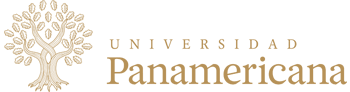

# PROYECTO FINAL

**Proyecto:** De la regresión regularizada al portafolio óptimo

**Materia:** Fundamentos de Econometría, Universidad Panamericana

**Profesor:** Dr. Julio César Galindo López

**Equipo:** Equipo CFA Challenge

**Integrantes:**
- Vázquez López Alvaro —  0267889
- Alvaro Fernandez Lozano — 0273215
- [Nombre completo 3] — matrícula [número]



**Semilla usada:** 267889



**Fecha de entrega:** 18 de Noviembre de 2026

# Proyecto: de la regresión regularizada al portafolio óptimo

**Fundamentos de Econometría (ECO515), Universidad Panamericana. Otoño 2026.**

Las cuatro partes del proyecto parecen temas distintos, pero comparten una sola idea: **todo depende de los valores propios de una matriz**.

| Parte | Matriz | Qué pasa si está mal condicionada |
|---|---|---|
| 1. Ridge, Lasso, Elastic Net | $X^\top X$ | Los coeficientes de MCO se vuelven muy variables |
| 2. Multicolinealidad | $X^\top X$ | VIF enormes y signos que cambian |
| 3. PCA | $\Sigma$ | Pocos componentes explican casi toda la varianza |
| 4. Markowitz | $\Sigma^{-1}$ | Los pesos óptimos se vuelven extremos e inestables |

## Cómo trabajar este notebook

1. **Escribe tu semilla** en la primera celda de código: la matrícula de un integrante. Con ella se eligen tus sectores, así que cada equipo obtiene números distintos.
2. **Corre las celdas en orden.** Donde veas `# TU CÓDIGO AQUÍ`, escribe tu código y **borra la línea `raise NotImplementedError`**.
3. **Revisa las comprobaciones.** Después de cada paso aparecen líneas `✅` o `❌`. Un `✅` indica que el resultado es coherente, no que tu interpretación sea correcta.
4. **Contesta cada `✍️` con tus números.** Una respuesta sin cifras de tu equipo no recibe puntos.
5. **No cambies los nombres de las variables** que ya están escritos: las celdas siguientes los usan.
6. **Documenta tu trabajo.** Agrega una portada, explica cada paso con celdas de texto propias, comenta tu código e interpreta cada tabla y gráfica. La lista completa está en `INSTRUCCIONES.md`.

**Datos.** Rendimientos mensuales de 30 portafolios de industria de EE. UU. (Kenneth R. French Data Library, 2000-01 a 2026-09, en porcentaje). No hace falta internet.

**Instrucciones de entrega, dashboard y rúbrica:** consulta `INSTRUCCIONES.md`. **Deducciones en papel:** están en el enunciado en PDF y se contestan al final de este notebook.

## 0. Preparación

**EXPLICACION** Cargamos las librerías y los datos de los 30 sectores, usamos el ID 267889 como semilla. La semilla determina nuestro sector objetivo (Carry) y los 12 activos del portafolio. Se separa los datos en entrenamiento (2000-2019, 240 meses) y prueba (2020-2026, 81 meses). Así cada resultado puede repetirse y se evalúa con datos que los modelos no vieron.

In [1]:
SEMILLA = 267889
EQUIPO = "Equipo CFA Challenge"

if SEMILLA is None:
    raise ValueError("Escribe tu matrícula en SEMILLA antes de continuar.")

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import (ElasticNetCV, LassoCV, LinearRegression, RidgeCV,
                                  lasso_path, ridge_regression)
from sklearn.model_selection import KFold, LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.formula.api import ols
from statsmodels.multivariate.manova import MANOVA
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3})


def comprobar(condicion, mensaje):
    print(("✅ " if condicion else "❌ ") + mensaje)


ARCHIVO = "industrias_ff30_mensual.csv"
candidatas = [Path("datos") / ARCHIVO, Path("../kit_alumnos/datos") / ARCHIVO, Path(ARCHIVO)]
ruta = next((r for r in candidatas if r.exists()), None)
# Sin el archivo local (por ejemplo, en Colab) se descarga del repositorio del proyecto
fuente = ruta if ruta is not None else f"https://raw.githubusercontent.com/IvliCaesar/Proyecto-Econometria-Regularizacion-PCA-Markowitz/main/datos/{ARCHIVO}"
datos = pd.read_csv(fuente, index_col="fecha")
FACTORES = ["Mkt-RF", "SMB", "HML", "RF"]
SECTORES = [c for c in datos.columns if c not in FACTORES]
excesos = datos[SECTORES].sub(datos["RF"], axis=0)  # rendimiento en exceso de la tasa libre

generador = np.random.default_rng(SEMILLA)
OBJETIVO = str(generador.choice(SECTORES))
ACTIVOS = sorted(str(s) for s in generador.choice(SECTORES, size=12, replace=False))

corte = int(0.75 * len(datos))
ENTRENA, PRUEBA = datos.index[:corte], datos.index[corte:]
print(f"Equipo: {EQUIPO} | Semilla: {SEMILLA}")
print(f"Sector objetivo (Parte 1): {OBJETIVO}")
print(f"Activos del portafolio (Parte 4): {ACTIVOS}")
print(f"Entrenamiento: {ENTRENA[0]} a {ENTRENA[-1]} ({len(ENTRENA)} meses)")
print(f"Prueba:        {PRUEBA[0]} a {PRUEBA[-1]} ({len(PRUEBA)} meses)")

Equipo: Equipo CFA Challenge | Semilla: 267889
Sector objetivo (Parte 1): Carry
Activos del portafolio (Parte 4): ['Autos', 'Beer', 'Books', 'Chems', 'Coal', 'FabPr', 'Food', 'Hshld', 'Meals', 'Other', 'Smoke', 'Trans']
Entrenamiento: 2000-01 a 2019-12 (240 meses)
Prueba:        2020-01 a 2026-09 (81 meses)


# Parte 1. Regresión lineal, Ridge, Lasso y Elastic Net

**Pregunta:** ¿en qué mejora la regularización a MCO, y en qué casos no?

**Caso.** Un fondo quiere **replicar** el rendimiento de tu sector objetivo con los otros 29 sectores. Es una relación *contemporánea*: mide replicación, **no pronóstico**. Por eso una $R^2$ alta aquí no significa que se pueda anticipar el mercado.

| Método | Se minimiza | Efecto |
|---|---|---|
| MCO | $\lVert y-X\beta\rVert^2$ | Insesgado, sin penalización |
| Ridge | $\lVert y-X\beta\rVert^2+\lambda\lVert\beta\rVert_2^2$ | Encoge todos los coeficientes; casi nunca los hace cero |
| Lasso | $\frac{1}{2n}\lVert y-X\beta\rVert^2+\lambda\lVert\beta\rVert_1$ | Encoge y **selecciona**: hace ceros exactos |
| Elastic Net | $\frac{1}{2n}\lVert y-X\beta\rVert^2+\lambda\left[\rho\lVert\beta\rVert_1+\frac{1-\rho}{2}\lVert\beta\rVert_2^2\right]$ | Selecciona y reparte el peso entre variables correlacionadas |

Tres reglas para no invalidar los resultados:

- **Estandariza dentro de un `Pipeline`.** La penalización depende de la escala, y el escalador debe ajustarse solo con los datos de entrenamiento.
- **Elige $\lambda$ solo con entrenamiento** (validación cruzada). El periodo de prueba se usa una vez, al final.
- **Los valores de `alpha` de Ridge y de Lasso no son comparables.** En `scikit-learn`, las fórmulas de la tabla usan escalas distintas (Lasso divide entre $2n$).

Usamos `KFold` sin barajar porque estimamos una relación contemporánea entre rendimientos con poca autocorrelación. Para **pronosticar** habría que usar `TimeSeriesSplit`.

### Paso 1.1. Separar los datos y estimar MCO

Construye `X_tr`, `y_tr`, `X_te`, `y_te`: la $y$ es el exceso de `OBJETIVO` y la $X$ son los excesos de los otros 29 sectores. Después estima MCO con `statsmodels` (recuerda `sm.add_constant`) y guárdalo en `mco`.

**EXPLICACION** Construimos la variable a replicar (el exceso de rendimiento de Carry) y las 29 regresoras (los excesos de las demas industrias) separadas para entrenamiento y prueba. Estimamos MCO solo con entrenamiento.

In [2]:
OTROS = [s for s in SECTORES if s != OBJETIVO] #arma lista de los sectores que no son el objetivo

# Datos de entrenamiento (2000-2019)
X_tr = excesos.loc[ENTRENA, OTROS]    # Los 29 sectores
y_tr = excesos.loc[ENTRENA, OBJETIVO] # Carry

#Datos de prueba (2020-2026) (PARA EVALUAR)
X_te = excesos.loc[PRUEBA, OTROS]
y_te = excesos.loc[PRUEBA, OBJETIVO]

# Regresion por MCO solo con datos de entrenamiento
# add_constant agrega un intercepto

mco = sm.OLS(y_tr, sm.add_constant(X_tr)).fit()

# Que tanto explica el modelo el conjunto de datos
print(f"R² = {mco.rsquared:.3f} | R² ajustada = {mco.rsquared_adj:.3f} | "
      f"F = {mco.fvalue:.1f} (p = {mco.f_pvalue:.2g})")

#Cuántos sectores salen signifativos por separado
print(f"Coeficientes individuales significativos al 5%: {(mco.pvalues.drop('const') < 0.05).sum()} de {len(OTROS)}")
comprobar(X_tr.shape == (len(ENTRENA), 29), "X_tr tiene 29 regresoras")
comprobar(OBJETIVO not in X_tr.columns, "El sector objetivo no está entre las regresoras")
comprobar(len(mco.params) == 30, "MCO tiene 29 pendientes y una constante")

R² = 0.712 | R² ajustada = 0.672 | F = 17.9 (p = 4.3e-42)
Coeficientes individuales significativos al 5%: 4 de 29
✅ X_tr tiene 29 regresoras
✅ El sector objetivo no está entre las regresoras
✅ MCO tiene 29 pendientes y una constante


*Con* MCO los otros 29 sectores explican el 71.2 % de la varianza de Carry en el entrenamiento con R² = 0.712 y R² ajustada = 0.672. La prueba F conjunta es significativa F = 17.9  y con valor p de p = 4.3 × 10⁻⁴².

### Paso 1.1b. Ridge por dentro

En el enunciado demuestras en papel que, si $X=UDV^\top$ es la descomposición en valores singulares,

$$\hat\beta_{\text{Ridge}}=(X^\top X+\lambda I)^{-1}X^\top y=V\,\mathrm{diag}\!\left(\frac{d_j}{d_j^2+\lambda}\right)U^\top y.$$

Comprueba ambas fórmulas con $\lambda=100$, usando `X_est` (regresoras estandarizadas) y `y_cen` (respuesta centrada). Calcula `beta_cerrada`, `beta_svd` y `factor`, el vector de encogimiento $d_j^2/(d_j^2+\lambda)$.

**EXPLICACION** Ridge es como MCO, pero le pone un castigo a los coeficientes muy grandes para que no se vuelvan inestables.La calculamos de dos maneras, con la fórmula directa y con la descomposición en valores singulares, y revisamos que las dos den lo mismo que la función de Ridge de Python. Además vemos cuánto encoge Ridge cada dirección de los datos, porque esperamos que encoja más las direcciones donde los sectores casi no varían, que son las que hacen inestable a MCO.

In [3]:
#Se estandarizan los 29 sectores con media 0 y desviación 1
X_est = StandardScaler().fit_transform(X_tr)
#centra a carry
y_cen = (y_tr - y_tr.mean()).to_numpy()
#lambda para la prueba
LAMBDA_PRUEBA = 100.0

p = X_est.shape[1]  # número de sectores (29)

# Forma 1: fórmula cerrada de Ridge
#np.eye(p) es matriz identidad
beta_cerrada = np.linalg.solve(X_est.T @ X_est + LAMBDA_PRUEBA * np.eye(p), X_est.T @ y_cen)

# Forma 2: descomposición en valores singulares
#d es la lista de valores singulares y Vt es V transpuesta
U, d, Vt = np.linalg.svd(X_est, full_matrices=False)
beta_svd = Vt.T @ ((d / (d**2 + LAMBDA_PRUEBA)) * (U.T @ y_cen))

# Factor de encogimiento de cada dirección
factor = d**2 / (d**2 + LAMBDA_PRUEBA)

#Comprobaciones
print(f"Encogimiento: dirección de mayor varianza {factor.max():.3f}; de menor varianza {factor.min():.3f}")
comprobar(np.allclose(beta_cerrada, ridge_regression(X_est, y_cen, alpha=LAMBDA_PRUEBA)), "La fórmula cerrada coincide con scikit-learn")
comprobar(np.allclose(beta_cerrada, beta_svd), "La fórmula por valores singulares coincide")
comprobar(np.all((factor > 0) & (factor < 1)), "Cada dirección se encoge por un factor entre 0 y 1")

Encogimiento: dirección de mayor varianza 0.975; de menor varianza 0.131
✅ La fórmula cerrada coincide con scikit-learn
✅ La fórmula por valores singulares coincide
✅ Cada dirección se encoge por un factor entre 0 y 1


Las tres formas de calcular Ridge dieron exactamente los mismos coeficientes. También vimos que Ridge no encoge todo igual. En la dirección donde los datos varían más, que es básicamente el movimiento general del mercado, Ridge deja casi todo el coeficiente (97.5 %). En la dirección donde los datos casi no varían lo encoge y solo deja el 13.1 %. En esas direcciones hay muy poca información y ahí es donde MCO da coeficientes inestables.

### Paso 1.2. Ajustar los cuatro modelos

Completa `construir_modelos()`. Cada modelo debe ser `make_pipeline(StandardScaler(), estimador)`. Usa:

- `LinearRegression()`
- `RidgeCV(alphas=ALFAS_RIDGE, cv=CV)`
- `LassoCV(alphas=ALFAS_L1, cv=CV, max_iter=20000)`
- `ElasticNetCV(l1_ratio=RAZONES_L1, alphas=ALFAS_L1, cv=CV, max_iter=20000)`

**EXPLICACION** Vamos a estimar cuatro modelos para replicar Carry: MCO y tres versiones que castigan los coeficientes grandes (Ridge, Lasso y Elastic Net). Lasso además puede dejar algunos coeficientes en cero (elegir qué sectores usar). Antes de estimar se ponen las variables en la misma escala para que el castigo sea parejo. El tamaño del castigo (λ) lo elegimos probando varios valores, pero solo con los datos de entrenamiento. Al final comparamos qué tan bueno es cada modelo con los datos que usó para estimar y con los datos de prueba.

In [4]:
RAZONES_L1 = [0.1, 0.5, 0.9]
CV = KFold(n_splits=5, shuffle=False)


def construir_modelos(n_alfas=40):
    ALFAS_RIDGE = np.logspace(-2, 4, n_alfas)
    ALFAS_L1 = np.logspace(-3, 1, n_alfas)

      # Cada modelo estandariza y luego estima
    return {
        "MCO": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=ALFAS_RIDGE, cv=CV)),
        "Lasso": make_pipeline(StandardScaler(), LassoCV(alphas=ALFAS_L1, cv=CV, max_iter=20000)),
        "Elastic Net": make_pipeline(StandardScaler(),
                                     ElasticNetCV(l1_ratio=RAZONES_L1, alphas=ALFAS_L1, cv=CV, max_iter=20000)),
    }


def evaluar(X_a, y_a, X_b, y_b):
   # estima con los datos a (entrenamiento) y evalua con los datos b (prueba)
    filas = {}
    for nombre, modelo in construir_modelos().items():
        modelo.fit(X_a, y_a) #estima el modelo
        final = modelo[-1]
        error_b = y_b - modelo.predict(X_b) #errores en los datos de prueba
        filas[nombre] = {
            # RMSE = raiz del promedio de los errores al cuadrado
            "RMSE entrenamiento": np.sqrt(np.mean((y_a - modelo.predict(X_a)) ** 2)),
            "RMSE prueba": np.sqrt(np.mean(error_b ** 2)),
            "R² prueba": 1 - np.sum(error_b ** 2) / np.sum((y_b - y_a.mean()) ** 2),
            "Coef. distintos de 0": int(np.sum(np.abs(final.coef_) > 1e-8)),
           # tamaño total de los coeficientes
            "Norma L2 (coef. estand.)": np.linalg.norm(final.coef_),
            "lambda": getattr(final, "alpha_", np.nan),
        }

    return pd.DataFrame(filas).T

# se compara los 4 modelos con datos de entrenamiento y prueba
tabla_completa = evaluar(X_tr, y_tr, X_te, y_te)
display(tabla_completa)

# Comrobaciones
comprobar(tabla_completa.loc["Ridge", "Norma L2 (coef. estand.)"] <= tabla_completa.loc["MCO", "Norma L2 (coef. estand.)"],
          "Ridge encoge la norma respecto de MCO")
comprobar(tabla_completa.loc["MCO", "RMSE entrenamiento"] == tabla_completa["RMSE entrenamiento"].min(),
          "MCO tiene el menor error de ENTRENAMIENTO, como debe ser")

,RMSE entrenamiento,RMSE prueba,R² prueba,Coef. distintos de 0,Norma L2 (coef. estand.),lambda
MCO,3.2704,4.8119,0.6103,29.0000,3.2478,NaN
Ridge,3.5138,4.8026,0.6118,29.0000,1.2864,289.4266
Lasso,3.3759,4.7606,0.6185,12.0000,2.2281,0.1805
Elastic Net,3.4645,4.7750,0.6162,26.0000,1.4302,0.7444


✅ Ridge encoge la norma respecto de MCO
✅ MCO tiene el menor error de ENTRENAMIENTO, como debe ser


Con los datos de entrenamiento, MCO tiene el menor error (RMSE de 3.27) lo cual es normal porque está hecho justo para minimizar ese error. Pero con los datos de prueba (2020-2026), los tres modelos con castigo le ganan. El mejor es Lasso, con un error de 4.761 contra 4.812 de MCO, 1.1 % menos, y además usa solo 12 de los 29 sectores. Ridge sí usa todos los sectores, pero hace sus coeficientes 60 % más chicos. Las mejoras son pequeñas porque con 240 meses MCO ya tiene suficientes datos.

### Paso 1.3. Trayectorias de los coeficientes

Grafica cómo cambian los coeficientes con $\lambda$. Ya está hecho Ridge; completa Lasso con `lasso_path(X, y, alphas=malla_l1)`, que devuelve `(alphas, coefs, _)` con los coeficientes en las **filas** de `coefs`.

**EXPLICACION** Vamos a graficar qué les pasa a los 29 coeficientes cuando el castigo (λ) se hace cada vez más grande, en Ridge y en Lasso. Queremos ver la diferencia entre los dos.

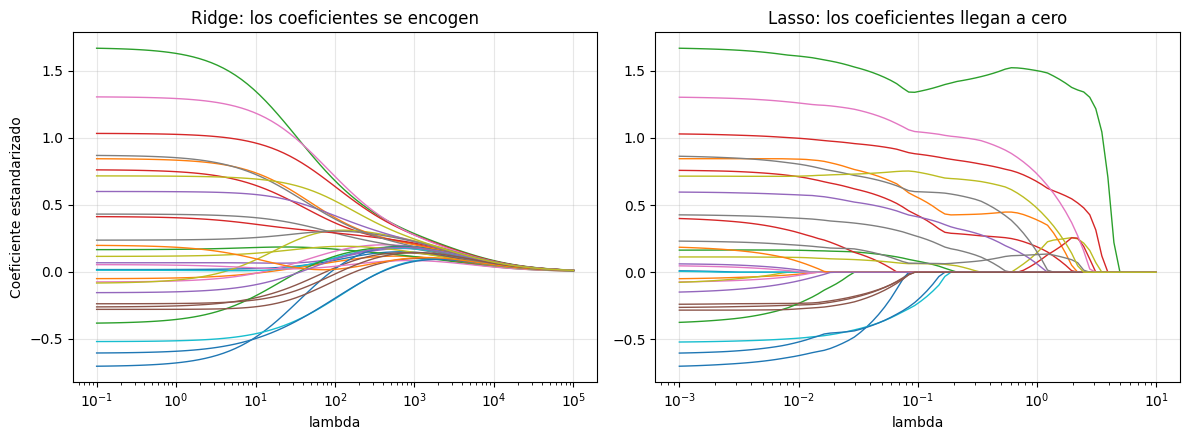

✅ La trayectoria de Lasso tiene la forma correcta
✅ Al crecer lambda, Lasso encoge los coeficientes


In [5]:
malla_ridge = np.logspace(-1, 5, 80)
malla_l1 = np.logspace(-3, 1, 80)
trayectoria_ridge = np.array([ridge_regression(X_est, y_cen, alpha=a) for a in malla_ridge])

# lasso_path calcula Lasso para los 80 lambdas de una vez
alphas_lasso, coefs_lasso, _ = lasso_path(X_est, y_cen, alphas=malla_l1)

# lasso_path regresa los lambdas de mayor a menor, asi que los ordenamos de menor a mayor
orden = np.argsort(alphas_lasso)
trayectoria_lasso = coefs_lasso[:, orden].T

# dos graficas lado a lado: Ridge a la izquierda y Lasso a la derecha
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
ejes[0].plot(malla_ridge, trayectoria_ridge, lw=1)
ejes[0].set(xscale="log", title="Ridge: los coeficientes se encogen", xlabel="lambda", ylabel="Coeficiente estandarizado")
ejes[1].plot(malla_l1, trayectoria_lasso, lw=1)
ejes[1].set(xscale="log", title="Lasso: los coeficientes llegan a cero", xlabel="lambda")
plt.tight_layout(); plt.show()

comprobar(trayectoria_lasso.shape == (80, 29), "La trayectoria de Lasso tiene la forma correcta")
comprobar(np.abs(trayectoria_lasso[-1]).sum() < np.abs(trayectoria_lasso[0]).sum(),
          "Al crecer lambda, Lasso encoge los coeficientes")

Las gráficas muestran la diferencia entre los dos métodos. En Ridge, todos los coeficientes se van haciendo chicos poco a poco, pero ninguno llega exactamente a 0. En Lasso, los coeficientes van llegando a cero uno por uno, así que Lasso va eliminando sectores. Con el λ que eligió la validación cruzada ( =0.18) se quedan 12 de los 29 sectores. También se ve que cuando Lasso elimina un sector a veces otro parecido crece como la línea verde porque "absorbe" su peso. Por eso Lasso sirve para quedarse con pocos sectores.

**EXPLICACION** Este paso es extra. sacamos la lista de los sectores que Lasso decidió conservar y sus coeficientes, ordenados de mayor a menor. Así podemos ver qué sectores pesan más para imitar el rendimiento de Carry.



In [6]:
# Sectores que Lasso conserva con el lambda elegido por validación cruzada
lasso_final = construir_modelos()["Lasso"].fit(X_tr, y_tr)[-1]
conservados = pd.Series(lasso_final.coef_, index=OTROS)
conservados[conservados != 0].sort_values(key=abs, ascending=False)

,0
Paper,1.4044
Meals,1.0138
Trans,0.8434
Other,0.6979
Oil,0.5853
Steel,0.4262
Autos,0.3433
Games,0.2905
Hlth,0.1782
Fin,0.0635


 Lasso se quedó con 12 sectores. Los que más pesan para imitar a Carry son Paper (1.40), Meals (1.01) y Trans (0.84). Todos los coeficientes son positivos, lo que significa que tiende a subir cuando estos sectores suben. Los 17 sectores que Lasso eliminó no son inútiles: muchos se parecen a otros que sí se quedaron, y Lasso solo se queda con uno de cada grupo parecido. Por eso esta lista sirve para replicar a Carry, pero no dice qué sectores lo "causan".

### Paso 1.4. ¿Y si hay pocos datos?

Repite la comparación con ventanas de entrenamiento cada vez más cortas: los **últimos** $n$ meses de entrenamiento, para $n\in\{36, 60, 120,\ \text{todos}\}$. El periodo de prueba no cambia. Guarda en `rmse_ventanas` un `DataFrame` con una columna por modelo, una fila por $n$ y el RMSE de prueba.

**EXPLICACION** Vamos a repetir la comparación de los cuatro modelos, pero solo con los últimos 36, 60 y 120 meses, y también con los 240 completos. Los datos de prueba no cambian. Queremos ver si los modelos con castigo ayudan más cuando hay pocos datos, ya que con 29 sectores y pocos meses, MCO tiene que estimar muchos coeficientes con poca información.

,MCO,Ridge,Lasso,Elastic Net
n de entrenamiento,,,,
36,13.6394,5.1416,5.1638,5.1437
60,6.4681,5.0383,4.9778,5.0720
120,5.1259,5.0095,5.0515,5.0271
240,4.8119,4.8026,4.7606,4.7750


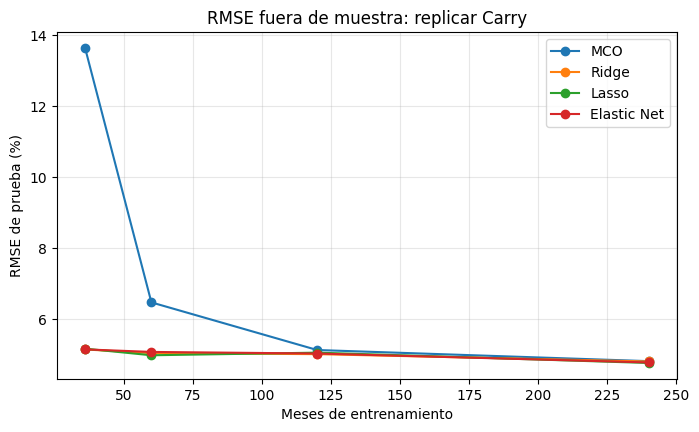

✅ Una fila por ventana y una columna por modelo


In [7]:
#tamaños de meustra para probar
VENTANAS = [36, 60, 120, len(X_tr)]
#ahi se guarda el error de prueba
filas = {}

#se repite la comparacion por cada tamaño de muestra
for n in VENTANAS:

    # Entrenamos solo con los últimos n meses del periodo de entrenamiento. la prueba no cambia
    tabla_n = evaluar(X_tr.iloc[-n:], y_tr.iloc[-n:], X_te, y_te)
    filas[n] = tabla_n["RMSE prueba"]  # guardamos el RMSE de prueba de los 4 modelos

# juntamos todo en una tabla y la volteamos, una fila por ventana y una columna por modelo
rmse_ventanas = pd.DataFrame(filas).T

# nombre de la columna de la izquierda
rmse_ventanas.index.name = "n de entrenamiento"
display(rmse_ventanas)

# grafica del error de prueba de cada modelo segun los meses de entrenamiento
ax = rmse_ventanas.plot(marker="o", title=f"RMSE fuera de muestra: replicar {OBJETIVO}")
ax.set(xlabel="Meses de entrenamiento", ylabel="RMSE de prueba (%)"); plt.show()

#comprobacion
comprobar(list(rmse_ventanas.index) == VENTANAS and rmse_ventanas.shape[1] == 4, "Una fila por ventana y una columna por modelo")

Con pocos datos, los modelos con castigo ayudan más. Con solo 36 meses, el error de prueba de MCO se dispara a 13.64, mientras que Ridge tiene 5.14, lo cual es 62 % menor. MCO tiene que estimar 30 coeficientes con solo 36 meses y termina ajustandose con ruido. Conforme hay más datos, la ventaja se hace más chica: con los 240 meses, Lasso solo mejora a MCO en 1.1 %. la regularización sirve más cuando hay pocos datos comparados con el número de variables.

### Paso 1.4b. ¿La diferencia es estadísticamente significativa?

Un RMSE menor puede deberse al azar. La prueba de **Diebold-Mariano** contrasta si dos modelos tienen la misma pérdida esperada: con $d_t=e_{\text{MCO},t}^2-e_{\text{Ridge},t}^2$, se regresa $d_t$ sobre una constante con errores estándar HAC.

Ajusta MCO y Ridge con **todo** el entrenamiento y calcula `d`. Guarda en `dm` el resultado de `sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": 3})`.

**EXPLICACION** Aplicamos la prueba de Diebold-Mariano para saber si la diferencia de error entre MCO y Ridge con la muestra completa es estadísticamente significativa o puede deberse al azar. Usamos errores estándar HAC porque los errores de meses consecutivos pueden estar correlacionados.

In [8]:
pred_mco = construir_modelos()["MCO"].fit(X_tr, y_tr).predict(X_te)
pred_ridge = construir_modelos()["Ridge"].fit(X_tr, y_tr).predict(X_te)
# TU CÓDIGO AQUÍ:

# Pérdida de cada modelo en cada mes de prueba  (error al cuadrado)
perdida_mco = (y_te.to_numpy() - pred_mco) ** 2
perdida_ridge = (y_te.to_numpy() - pred_ridge) ** 2

# diferencia mes por mes
d = perdida_mco - perdida_ridge

# prueba de Diebold-Mariano: regresion de d sobre una constante (columna de unos)
dm = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": 3})

print(f"Diferencia media de pérdida: {dm.params[0]:.3f}; t = {dm.tvalues[0]:.2f}; p = {dm.pvalues[0]:.3f}")
comprobar(abs(dm.params[0] - (tabla_completa.loc["MCO", "RMSE prueba"] ** 2 - tabla_completa.loc["Ridge", "RMSE prueba"] ** 2)) < 1e-8,
          "La media de d es la diferencia de los errores cuadráticos medios")

Diferencia media de pérdida: 0.089; t = 0.04; p = 0.965
✅ La media de d es la diferencia de los errores cuadráticos medios


**Interpretación.** En promedio, Ridge comete un error al cuadrado 0.089 menor que MCO cada mes, pero la diferencia no es significativa: la prueba de Diebold-Mariano da t = 0.04 y p = 0.965. Con los 240 meses, la pequeña ventaja de Ridge puede deberse solo al azar.

✍️ **Pregunta 1.1.** Con tus números: ¿cuántos sectores conserva Lasso de los 29?, ¿cuál método gana con muestra completa y cuál con $n=36$?, ¿por cuánto, en términos porcentuales? ¿La diferencia entre MCO y Ridge con muestra completa es significativa según Diebold-Mariano? ¿Por qué una sola ventana no basta para concluir?

**✍️ Tu respuesta (con los números de TU equipo):**

**1. ¿Cuántos sectores conserva Lasso?** Con los 240 meses, Lasso se queda con 12 de los 29 sectores. Los que más pesan son Paper, Meals y Trans.

**2. ¿Qué método gana y por cuánto?** Con los 240 meses gana Lasso, con un error de prueba de 4.761 contra 4.812 de MCO: apenas 1.1 % menos. Con solo 36 meses gana Ridge, con un error de 5.142 contra 13.639 de MCO: 62 % menos.

**3. ¿Es significativa la diferencia entre MCO y Ridge con los 240 meses?** No. La prueba de Diebold-Mariano da p = 0.965, así que la pequeña ventaja de Ridge puede ser solo suerte.

**4. ¿Por qué una sola ventana no basta?** Porque todo sale de un solo periodo de prueba (2020-2026), que además tuvo la pandemia. El ganador cambia según la ventana y las diferencias entre los modelos con castigo son muy chicas, así que no sabemos si un método es mejor en general o solo tuvo suerte. Para saberlo hay que repetir el experimento muchas veces.

### Paso 1.5. Experimento de Monte Carlo

Para saber **en qué casos** mejora la regularización, simulamos datos donde conocemos el verdadero $\beta$ y variamos tres condiciones:

- **Colinealidad:** $\rho = 0.1$ o $\rho = 0.95$ entre todas las regresoras.
- **Verdad:** *escasa* (3 coeficientes distintos de cero) o *densa* (todos distintos de cero), con la misma $\lVert\beta\rVert$.
- **Datos:** *abundantes* ($n=200,\ p=20$) o *escasos* ($n=40,\ p=30$).

Son 8 escenarios y 4 métodos, con **una muestra independiente para cada método y réplica**. Eso importa: MANOVA supone observaciones independientes. Medimos dos respuestas: el logaritmo del RMSE de prueba y el logaritmo del error de estimación $\lVert\hat\beta-\beta\rVert$.

Completa `simular_datos`: genera $X_{ij}=\sqrt{\rho}\,z_i+\sqrt{1-\rho}\,e_{ij}$, con $z_i$ y $e_{ij}$ normales estándar independientes, y $y=X\beta+\sigma\varepsilon$. La celda tarda unos minutos la primera vez; el resultado queda guardado en un archivo.

**EXPLICACION** Con nuestros datos reales solo tenemos una muestra así que no podemos saber en qué casos conviene usar los modelos con castigo. Por eso vamos a inventar datos con una simulación donde sí conocemos los coeficientes verdaderos. Cambiamos 3 cosas: qué tan parecidas son las variables entre sí, si solo unas cuantas variables importan o todas y si hay muchos o pocos datos. En cada caso repetimos el experimento 20 veces y medimos dos cosas: qué tan bien predice cada modelo y qué tan cerca quedan sus coeficientes de los verdaderos.

In [9]:
N_REPETICIONES = 20
METODOS = ["MCO", "Ridge", "Lasso", "Elastic Net"]
ESCENARIOS = [(r, v, d) for r in (0.1, 0.95) for v in ("escasa", "densa") for d in ("abundantes", "escasos")]
TAMANOS = {"abundantes": (200, 20), "escasos": (40, 30)}
SIGMA = 1.5


def simular_datos(n, p, rho, verdad, rng, sigma=SIGMA):
    # Regresa X (n x p), y (n,), beta (p,)
    k = 3
    beta = np.zeros(p)
    if verdad == "escasa":
        beta[:k] = rng.choice([-1.0, 1.0], size=k)
    else:
        beta = rng.normal(size=p)
        beta *= np.sqrt(k) / np.linalg.norm(beta)  # misma norma en ambos casos
    # TU CÓDIGO AQUÍ:

    # z = factor comun que comparten todas las variables (un numero por observacion)
    z = rng.normal(size=(n, 1))
    # e = ruido de cada variable
    e = rng.normal(size=(n, p))
    X = np.sqrt(rho) * z + np.sqrt(1 - rho) * e
    # y = X por beta mas ruido de tamano sigma
    y = X @ beta + sigma * rng.normal(size=n)
    return X, y, beta


def correr_monte_carlo(semilla, repeticiones=N_REPETICIONES):
    rng = np.random.default_rng(semilla)
    filas = []
    # se recorre los 8 escenarios los 4 metodos y las 20 repeticiones
    for rho, verdad, disp in ESCENARIOS:
        n, p = TAMANOS[disp]
        for metodo in METODOS:
            for _ in range(repeticiones):
              # se genera n datos para estimar y 500 extra para evaluar
                X, y, beta = simular_datos(n + 500, p, rho, verdad, rng)
                modelo = construir_modelos(n_alfas=10)[metodo].fit(X[:n], y[:n])  # malla corta: más rápido
                error = y[n:] - modelo.predict(X[n:])
                # se regresa los coeficientes a la escala original para compararlos conn beta
                coef = modelo[-1].coef_ / modelo[0].scale_  # de regreso a la escala original
                filas.append({
                    "metodo": metodo, "colinealidad": f"rho={rho}", "verdad": verdad, "datos": disp,
                    "escenario": f"rho={rho}|{verdad}|{disp}",
                    "log_rmse": np.log(np.sqrt(np.mean(error ** 2))),
                    "log_error_beta": np.log(np.linalg.norm(coef - beta)),
                })
    return pd.DataFrame(filas)


# Se guarda en disco para no repetirlo
archivo_mc = Path(f"montecarlo_{SEMILLA}.csv")
if archivo_mc.exists():
    mc = pd.read_csv(archivo_mc)
else:
    mc = correr_monte_carlo(SEMILLA)
    mc.to_csv(archivo_mc, index=False)

#COMPROBACION
_X, _y, _b = simular_datos(100_000, 3, 0.95, "escasa", np.random.default_rng(1))
comprobar(abs(np.corrcoef(_X[:, 0], _X[:, 1])[0, 1] - 0.95) < 0.01, "La correlación simulada entre regresoras es rho")
comprobar(len(mc) == 8 * 4 * N_REPETICIONES, "El diseño está balanceado")
tabla_rmse = mc.pivot_table(index=["colinealidad", "verdad", "datos"], columns="metodo", values="log_rmse", aggfunc="mean").pipe(np.exp)[METODOS]
tabla_beta = mc.pivot_table(index=["colinealidad", "verdad", "datos"], columns="metodo", values="log_error_beta", aggfunc="mean").pipe(np.exp)[METODOS]
print("RMSE de prueba (media geométrica). El mínimo posible es sigma = 1.5")
display(tabla_rmse.style.format("{:.3f}").highlight_min(axis=1, color="#b7e4c7"))
print("Error de estimación de beta (media geométrica)")
display(tabla_beta.style.format("{:.3f}").highlight_min(axis=1, color="#b7e4c7"))

✅ La correlación simulada entre regresoras es rho
✅ El diseño está balanceado
RMSE de prueba (media geométrica). El mínimo posible es sigma = 1.5


Error de estimación de beta (media geométrica)


**Muchos datos y variables poco parecidas:**
 los cuatro modelos predicen casi igual, así que aquí no hace falta el castigo.

**Muchos datos y variables muy parecidas:**
predicen casi igual, pero MCO estima mucho peor los coeficientes. Ridge y Lasso reducen ese error en más de 30 %.

**Pocos datos:**
 En MCO, su error de predicción es casi el doble y su error en los coeficientes es hasta 85 % mayor que el de los modelos con castigo.

También importa cuántas variables importan de verdad. Cuando son pocas y las variables no se parecen, Lasso y Elastic Net funcionan mejor. Cuando las variables son casi iguales, Ridge funciona mejor porque Lasso puede elegir la variable equivocada. En general, Elastic Net fue el más seguro: ganó en predicción en 6 de los 8 casos. el mejor método cambia según el caso.

### Paso 1.6. Tabla MANOVA, construida a mano

Queremos contrastar si el **vector** de respuestas $(\log\text{RMSE},\ \log\lVert\hat\beta-\beta\rVert)$ depende del método, del escenario y de su interacción. Para un diseño balanceado de dos factores ($a$ métodos, $b$ escenarios, $r$ réplicas), con $\bar y_{i\cdot}$, $\bar y_{\cdot j}$, $\bar y_{ij}$ y $\bar y$ como vectores de medias:

$$H_A=br\sum_i(\bar y_{i\cdot}-\bar y)(\bar y_{i\cdot}-\bar y)^\top,\qquad H_B=ar\sum_j(\bar y_{\cdot j}-\bar y)(\bar y_{\cdot j}-\bar y)^\top$$

$$H_{AB}=r\sum_{i,j}(\bar y_{ij}-\bar y_{i\cdot}-\bar y_{\cdot j}+\bar y)(\cdot)^\top,\qquad E=\sum_{i,j,k}(y_{ijk}-\bar y_{ij})(\cdot)^\top$$

Si $\theta_1,\dots,\theta_s$ son los valores propios de $E^{-1}H$, los cuatro estadísticos son:

$$\Lambda_{\text{Wilks}}=\prod_i\frac{1}{1+\theta_i},\quad V_{\text{Pillai}}=\sum_i\frac{\theta_i}{1+\theta_i},\quad T_{\text{Hotelling-Lawley}}=\sum_i\theta_i,\quad R_{\text{Roy}}=\max_i\theta_i$$

Completa `matrices_manova` y `estadisticos`. Recuerda: **MANOVA no diagnostica multicolinealidad**. Compara medias de varias respuestas entre grupos; la multicolinealidad es una relación entre las columnas de $X$.

**EXPLICACION** En el Monte Carlo vimos que el mejor modelo parece cambiar según el caso pero tenemos que probarlo con estadística. Para eso hacemos una MANOVA que es como una ANOVA pero con dos variables de respuesta a la vez: el error de predicción y el error en los coeficientes. Vamos a calcularla a mano, separando cuánta variación viene del método, cuánta del escenario, cuánta de la combinación de los dos y cuánta es solo ruido. Luego revisamos que esas partes sumen exactamente la variación total.

In [10]:
RESPUESTAS = ["log_rmse", "log_error_beta"]


def matrices_manova(df, factor_a, factor_b, respuestas=RESPUESTAS):
    a, b = df[factor_a].nunique(), df[factor_b].nunique()
    r = len(df) / (a * b)
    m = df[respuestas].mean().to_numpy()
    m_a = df.groupby(factor_a)[respuestas].mean()
    m_b = df.groupby(factor_b)[respuestas].mean()
    m_ab = df.groupby([factor_a, factor_b])[respuestas].mean()
    # TU CÓDIGO AQUÍ:

    # H del factor A (método): desviaciones de las medias de cada método respecto de la media general
    H_a = b * r * sum(np.outer(v - m, v - m) for v in m_a.to_numpy())
    # H del factor B (escenario)
    H_b = a * r * sum(np.outer(v - m, v - m) for v in m_b.to_numpy())

    # H de la interacción: lo que la media de cada celda no explican los efectos principales
    H_ab = np.zeros((len(respuestas), len(respuestas)))
    for (i, j), fila in m_ab.iterrows():
        dv = fila.to_numpy() - m_a.loc[i].to_numpy() - m_b.loc[j].to_numpy() + m
        H_ab += r * np.outer(dv, dv)

    # E (error): cada observación menos la media de su celda (método, escenario)
    residuos = df[respuestas] - df.groupby([factor_a, factor_b])[respuestas].transform("mean")
    E = (residuos.T @ residuos).to_numpy()
    return {factor_a: H_a, factor_b: H_b, f"{factor_a} x {factor_b}": H_ab}, E


def estadisticos(H, E):
    # TU CÓDIGO AQUÍ:

    theta = np.real(np.linalg.eigvals(np.linalg.solve(E, H)))
    return {
        "Wilks": np.prod(1 / (1 + theta)),
        "Pillai": np.sum(theta / (1 + theta)),
        "Hotelling-Lawley": np.sum(theta),
        "Roy": np.max(theta),
    }


H_dict, E = matrices_manova(mc, "metodo", "escenario")
a_mano = pd.DataFrame({efecto: estadisticos(H, E) for efecto, H in H_dict.items()}).T
print("Estadísticos calculados a mano")
display(a_mano)
T = (mc[RESPUESTAS] - mc[RESPUESTAS].mean()).pipe(lambda d: d.T @ d).to_numpy()
comprobar(np.allclose(sum(H_dict.values()) + E, T),
          "Descomposición exacta: H_metodo + H_escenario + H_interaccion + E = T")

Estadísticos calculados a mano


,Wilks,Pillai,Hotelling-Lawley,Roy
metodo,0.2844,0.7182,2.5076,2.5039
escenario,0.0224,1.6343,14.3389,11.8663
metodo x escenario,0.2516,0.9223,2.2832,1.9239


✅ Descomposición exacta: H_metodo + H_escenario + H_interaccion + E = T


las partes suman exactamente la variación total. En la tabla, un Wilks chico significa que el efecto es grande. Los tres efectos importan:

**Escenario** es el más fuerte (Wilks = 0.022): las condiciones de los datos son lo que más cambia los errores.

**Método** también importa (Wilks = 0.284): la diferencia más grande es entre MCO y los modelos con castigo.

**Método × escenario** (Wilks = 0.252) nos dice que el mejor método depende del caso igual que en Monte Carlo.


### Paso 1.7. Tabla MANOVA con `statsmodels` y tamaño de efecto

Compara tu cálculo con `statsmodels`. La fórmula usa contrastes de suma, `C(metodo, Sum)`, para que cada término contraste el efecto principal correcto. La celda arma la tabla que reportarás.

Agregamos el **tamaño de efecto** $\eta^2_{\text{multiv.}}=1-\Lambda^{1/s}$, con $s=\min(\text{respuestas},\ gl_H)$: con muchas réplicas casi cualquier diferencia es significativa, y un valor $p$ pequeño no dice que la diferencia sea grande.

**EXPLICACION** Vamos a calcular la misma MANOVA con la función de Python (`statsmodels`) para revisar que nuestro cálculo esté bien. Esta función también nos da los valores p. Además calculamos el tamaño de efecto (η²), porque con 640 observaciones casi todo sale significativo.

In [11]:
resultado = MANOVA.from_formula(
    "log_rmse + log_error_beta ~ C(metodo, Sum) * C(escenario, Sum)", data=mc
).mv_test()

TERMINOS = {
    "C(metodo, Sum)": "metodo",
    "C(escenario, Sum)": "escenario",
    "C(metodo, Sum):C(escenario, Sum)": "metodo x escenario",
}
NOMBRES = {"Wilks' lambda": "Wilks", "Pillai's trace": "Pillai",
           "Hotelling-Lawley trace": "Hotelling-Lawley", "Roy's greatest root": "Roy"}
filas = []
for termino, efecto in TERMINOS.items():
    for original, corto in NOMBRES.items():
        s = resultado.results[termino]["stat"].loc[original]
        filas.append({"Efecto": efecto, "Estadístico": corto, "Valor": float(s["Value"]),
                      "gl num.": float(s["Num DF"]), "gl den.": float(s["Den DF"]),
                      "F": float(s["F Value"]), "p": float(s["Pr > F"])})
tabla_manova = pd.DataFrame(filas).set_index(["Efecto", "Estadístico"])
gl_h = {"metodo": 3, "escenario": 7, "metodo x escenario": 21}
tabla_manova["eta² multiv."] = [
    1 - tabla_manova.loc[(e, "Wilks"), "Valor"] ** (1 / min(2, gl_h[e])) if est == "Wilks" else np.nan
    for e, est in tabla_manova.index
]
display(tabla_manova.style.format({"Valor": "{:.4f}", "gl num.": "{:.0f}", "gl den.": "{:.0f}", "F": "{:.2f}",
                                   "p": "{:.2e}", "eta² multiv.": "{:.3f}"}, na_rep=""))

comprobar(abs(a_mano.loc["metodo", "Wilks"] - tabla_manova.loc[("metodo", "Wilks"), "Valor"]) < 1e-6,
          "Tu Wilks de método coincide con statsmodels")
comprobar(abs(a_mano.loc["metodo x escenario", "Pillai"] - tabla_manova.loc[("metodo x escenario", "Pillai"), "Valor"]) < 1e-6,
          "Tu Pillai de la interacción coincide con statsmodels")

✅ Tu Wilks de método coincide con statsmodels
✅ Tu Pillai de la interacción coincide con statsmodels


Nuestro cálculo da lo mismo que `statsmodels`. Los tres efectos son significativos con valores p prácticamente de 0. Como con tantos datos casi todo sale significativo. lo que más importa es el tamaño de efecto (η²), que va de 0 a 1. El escenario tiene el efecto más grande (0.850), despues, la combinación método × escenario (0.498) y del método (0.467). Los tres son efectos grandes, y el de la combinación confirma que el mejor método depende del caso.

### Paso 1.8. ¿Se cumplen los supuestos? ¿Qué respuesta explica el efecto?

Un MANOVA significativo no dice *cuál* respuesta ni *qué* método. Completa el primero; el segundo ya está hecho:

1. **ANOVA univariada por respuesta** (`ols` + `anova_lm`, `typ=2`). Como hay dos respuestas, usa corrección de Bonferroni: nivel $0.05/2$.
2. **Varianza de los residuos por celda.** MANOVA supone covarianzas iguales entre celdas; la celda calcula la razón entre la mayor y la menor varianza residual de cada respuesta. Una razón grande indica que los valores $p$ son solo aproximados: el diseño balanceado y la traza de Pillai ayudan, pero no lo resuelven del todo.

**EXPLICACION** Hacemos una ANOVA para cada error por separado. Como son dos pruebas, usamos un nivel de significancia más estricto (0.05 / 2 = 0.025), que se llama corrección de Bonferroni. También revisamos un supuesto de la MANOVA: que la variación sea parecida en todos los grupos. Si no se cumple, los valores p son solo aproximados.

In [12]:
seguimiento = {}
for respuesta in RESPUESTAS:
    # TU CÓDIGO AQUÍ:

      # regresion de esta respuesta contra el metodo, el escenario y su interaccion
    modelo_respuesta = ols(f"{respuesta} ~ C(metodo) * C(escenario)", data=mc).fit()
    # tabla ANOVA con sumas de cuadrados tipo II
    seguimiento[respuesta] = anova_lm(modelo_respuesta, typ=2)

    # nivel con Bonferroni: como son 2 pruebas 0.05 / 2 = 0.025
    print(f"ANOVA de {respuesta} (nivel con Bonferroni: 0.025)")
    display(seguimiento[respuesta])

# revisamos el supuesto de que la variacion sea parecida en todos los grupos
residuos = mc[RESPUESTAS] - mc.groupby(["metodo", "escenario"])[RESPUESTAS].transform("mean")
var_celda = residuos.groupby([mc["metodo"], mc["escenario"]]).var()
razon_var = var_celda.max() / var_celda.min()
print("Razón varianza máxima / mínima entre celdas:")
print(razon_var.round(2).to_string())

#comprobacion
comprobar(set(seguimiento) == set(RESPUESTAS), "Hay una ANOVA por respuesta")

ANOVA de log_rmse (nivel con Bonferroni: 0.025)


,sum_sq,df,F,PR(>F)
C(metodo),11.0873,3.0000,375.2023,0.0000
C(escenario),15.1401,7.0000,219.5787,0.0000
C(metodo):C(escenario),10.1314,21.0000,48.9790,0.0000
Residual,5.9889,608.0000,NaN,NaN


ANOVA de log_error_beta (nivel con Bonferroni: 0.025)


,sum_sq,df,F,PR(>F)
C(metodo),76.3162,3.0000,457.8132,0.0000
C(escenario),287.9240,7.0000,740.2400,0.0000
C(metodo):C(escenario),54.6176,21.0000,46.8065,0.0000
Residual,33.7840,608.0000,NaN,NaN


Razón varianza máxima / mínima entre celdas:
log_rmse         136.2800
log_error_beta    34.7300
✅ Hay una ANOVA por respuesta


Las dos ANOVA confirman lo que dijo la MANOVA: para los dos errores, el método, el escenario y su combinación son significativos, a pesar de contar con el nivel más estricto de 0.025. En el error de predicción el método y el escenario pesan parecido. En el error de los coeficientes, el escenario pesa mucho más. Pero el supuesto de que la variación sea parecida en todos los grupos no se cumple. Por eso los valores p de la MANOVA son solo aproximados, aunque al ser tan pequeños la conclusión no cambia.

✍️ **Pregunta 1.2. Conclusión de la Parte 1.** Llena esta tabla con tus resultados y justifica cada renglón.

| Situación | ¿Mejora la regularización a MCO en predicción? | ¿Y en la estimación de β? | Método preferido |
|---|---|---|---|
| Muchos datos, baja colinealidad (ρ = 0.1, n = 200) | **Casi no.** Todos predicen casi igual (diferencias de 1 % a 5 %). | **Depende.** Casi nada si todas las variables importan. con pocas variables importantes, Elastic Net reduce el error 32 %. | MCO está bien. Elastic Net si solo pocas variables importan |
| Muchos datos, alta colinealidad (ρ = 0.95, n = 200) | **Poco.** Ridge y Elastic Net mejoran apenas 3 % a 4 %. | **Sí, mucho.** Ridge y Lasso reducen el error de 32 % a 38 %. | Ridge o Lasso. Elastic Net funciona bien en los dos casos |
| Pocos datos, verdad escasa (n = 40, p = 30) | **Sí, mucho.** El error baja de 44 % a 51 %. | **Sí, mucho.** El error baja de 67 % a 85 %. | Elastic Net o Lasso con baja colinealidad. Ridge con alta |
| Pocos datos, verdad densa (n = 40, p = 30) | **Sí, mucho.** El error baja de 35 % a 49 %. | **Sí, mucho.** El error baja de 51 % a 84 %. | Elastic Net (Ridge muy cerca) |

Responde también:

- ¿Qué renglón de la tabla MANOVA responde "*depende del caso*"? ¿Qué dice su $\eta^2$?
- ¿Cuál estadístico reportas como principal y por qué? (Elígelo por el diseño, no por el valor $p$.) ¿Se cumple la igualdad de covarianzas? ¿Qué tanto puedes confiar en los valores $p$?
- ¿Qué pierdes al usar Lasso frente a MCO si tu objetivo es hacer inferencia sobre un coeficiente?

**✍️ Tu respuesta (con los números de TU equipo):**

**¿Qué renglón de la tabla MANOVA responde "depende del caso"? ¿Qué dice su η²?**

El de la interacción método × escenario. Su η² es 0.498, un efecto grande. Quiere decir que el mejor método cambia según el caso. Por ejemplo, con pocos datos y pocas variables importantes, gana Elastic Net si las variables no se parecen, pero gana Ridge si se parecen mucho.

**¿Cuál estadístico reportas como principal y por qué? ¿Se cumple la igualdad de covarianzas? ¿Qué tanto puedes confiar en los valores p?**

Reporto la traza de Pillai, porque es la que mejor aguanta cuando no se cumplen los supuestos, sobre todo cuando todos los grupos tienen el mismo número de datos, como aquí. La igualdad de covarianzas no se cumple. Por eso los valores p son solo aproximados. Aun asi no cambia la conclusión, porque los p son muy pequeños y los efectos son grandes.

**¿Qué pierdes al usar Lasso frente a MCO si tu objetivo es hacer inferencia sobre un coeficiente?**

Con Lasso los coeficientes salen encogidos, o sea sesgados, y ya no se puede usar las pruebas t ni los intervalos de confianza de MCO. Además, si un coeficiente sale en 0 no significa que el sector no importe: cuando dos sectores se parecen, Lasso se queda con uno casi al azar. Por eso uso Lasso para replicar, pero MCO si quiero interpretar un coeficiente.

# Parte 2. ¿Cómo evadir el problema de multicolinealidad?

Primero, una precisión: la multicolinealidad **no sesga** a MCO y las pruebas siguen siendo válidas; solo aumenta la varianza de los coeficientes individuales. Si solo te importa predecir y la relación entre regresoras se mantiene, quizá no haya nada que arreglar. Es un problema cuando quieres interpretar un coeficiente individual.

Usaremos **Longley** (16 años, EE. UU.), el mismo ejemplo de las notas del curso, cuyo VIF de GNP es cercano a 1788.

$$\mathrm{VIF}_j=\frac{1}{1-R_j^2}$$

### Paso 2.1. Diagnóstico

Completa `tabla_vif(X)`: agrega la constante a $X$ y usa `variance_inflation_factor` para cada regresora (sin incluir la constante). Calcula también `condicion`: el número de condición de $X$ **estandarizada**, con `np.linalg.cond`.

**EXPLICACION** Usamos los datos de Longley. Primero se programa 2 medidas para detectar la multicolinealidad: el VIF de cada variable, que indica cuánto aumenta la varianza de su coeficiente por estar correlacionada con las demás, y el número de condición, que mide qué tan grave es el problema en conjunto. Con estas medidas evaluamos qué tan seria es la multicolinealidad antes de corregirla.

In [13]:
longley = sm.datasets.longley.load_pandas().data
y_l = longley["TOTEMP"]
X_l = longley.drop(columns="TOTEMP")


def tabla_vif(X):
    # TU CÓDIGO AQUÍ:

     # agregamos la constante (intercepto), porque el VIF sale de regresiones con intercepto
    Xc = sm.add_constant(X)
     # VIF de cada variable = 1 / (1 - R2)
    valores = [variance_inflation_factor(Xc.to_numpy(dtype=float), i) for i in range(1, Xc.shape[1])]
    return pd.Series(valores, index=X.columns)

def condicion(X):
    # TU CÓDIGO AQUÍ:

    # Se estandariza para que el número de condición no dependa de las unidades de cada variable
    return np.linalg.cond(StandardScaler().fit_transform(X))

# tabla con el VIF y la tolerancia (1 / VIF) de cada variable de Longley
vif_longley = tabla_vif(X_l)
display(vif_longley.to_frame("VIF").assign(Tolerancia=lambda d: 1 / d["VIF"]))

# regresion con MCO con los datos de Longley
mco_l = sm.OLS(y_l, sm.add_constant(X_l)).fit()
print(f"Número de condición (estandarizado): {condicion(X_l):.1f}")
print(f"R² = {mco_l.rsquared:.4f}; F: p = {mco_l.f_pvalue:.2g}; pendientes significativas al 5%: {(mco_l.pvalues.drop('const') < .05).sum()} de 6")
comprobar(abs(vif_longley["GNP"] - 1788.5) < 1, "El VIF de GNP coincide con las notas (1788.5)")

,VIF,Tolerancia
GNPDEFL,135.5324,0.0074
GNP,"1,788.5135",0.0006
UNEMP,33.6189,0.0297
ARMED,3.5889,0.2786
POP,399.1510,0.0025
YEAR,758.9806,0.0013


Número de condición (estandarizado): 110.5
R² = 0.9955; F: p = 5e-10; pendientes significativas al 5%: 3 de 6
✅ El VIF de GNP coincide con las notas (1788.5)


Longley presenta una multicolinealidad grave. 5 de las 6 variables tienen un VIF mayor que 10, que es el umbral. el caso más extremo es GNP, con 1788.5. Esto significa que el 99.9 % de la variación de GNP se explica con las demás variables. El número de condición 110.5 también es alto. En la regresión, el modelo explica casi todo el empleo (R² = 0.9955), pero solo 3 de las 6 variables son significativas por separado. Es decir, en conjunto las variables explican muy bien el empleo, pero no es posible separar el efecto individual de cada una.

### Paso 2.2. El síntoma: coeficientes inestables

Quita una observación a la vez, reestima MCO y guarda las pendientes en `jack_coef` (una fila por observación eliminada). La celda reporta cuántas pendientes cambian de signo.

**EXPLICACION** Queremos comprobar qué tan estables son los coeficientes de MCO en Longley. quitamos un año a la vez, volvemos a estimar la regresión con los 15 años restantes y guardamos los 6 coeficientes. Este procedimiento se conoce como jackknife. Si al quitar un solo año un coeficiente cambia de signo, ese coeficiente no se puede interpretar con confianza. Esta es una de las consecuencias de la multicolinealidad.

In [14]:
# TU CÓDIGO AQUÍ:
filas = []

# se repite 16 veces quitando un ano diferente cada vez
for i in range(len(X_l)):
    # Quitamos la observación i (un año) de X y de y
    X_sin_i = X_l.drop(index=X_l.index[i])
    y_sin_i = y_l.drop(index=y_l.index[i])
    # Reestimamos MCO con los 15 años restantes y guardamos solo las 6 pendientes
    modelo_i = sm.OLS(y_sin_i, sm.add_constant(X_sin_i)).fit()
    filas.append(modelo_i.params.drop("const"))

# tabla de 16 x 6: una fila por ano quitado y una columna por variable
# reset_index renumera las filas del 0 al 15
jack_coef = pd.DataFrame(filas).reset_index(drop=True)


resumen_jack = pd.DataFrame({"Completo": mco_l.params.drop("const"), "Mín.": jack_coef.min(), "Máx.": jack_coef.max()})
resumen_jack["Cambia de signo"] = np.sign(resumen_jack["Mín."]) != np.sign(resumen_jack["Máx."])
display(resumen_jack)
comprobar(jack_coef.shape == (16, 6), "16 reestimaciones de 6 pendientes")

,Completo,Mín.,Máx.,Cambia de signo
GNPDEFL,15.0619,-52.3573,40.7809,True
GNP,-0.0358,-0.0838,-0.0212,False
UNEMP,-2.0202,-2.6978,-1.7473,False
ARMED,-1.0332,-1.2558,-0.9043,False
POP,-0.0511,-0.1917,0.1661,True
YEAR,"1,829.1515","1,432.1248","2,583.5791",False


✅ 16 reestimaciones de 6 pendientes


Los coeficientes de MCO en Longley son muy inestables. Basta con quitar un solo año para que dos de ellos cambien de signo: el de GNPDEFL va de −52.36 a +40.78, y el de POP de −0.19 a +0.17. Por lo tanto no es posible saber si su efecto sobre el empleo es positivo o negativo. Los únicos coeficientes relativamente estables son los de UNEMP y ARMED, que son también las variables con menor VIF. Esto confirma lo del Paso 2.1, el modelo ajusta bien en conjunto, pero sus coeficientes individuales no se pueden interpretar.

### Paso 2.3. Los remedios, comparados

Completa el diccionario `remedios`. Cada entrada es un `(X, modelo)` y se evalúa con error de validación *leave-one-out*, que reajusta todo el `Pipeline` sin la observación omitida.

| Remedio | Idea | Qué completar |
|---|---|---|
| **Quitar variables** | Eliminar las redundantes | $X$ sin `GNP` ni `POP` |
| **Transformar** | Usar razones que tengan sentido económico | `PIB_real_pc` = `GNP`/(`GNPDEFL`·`POP`), más `UNEMP`, `ARMED` |
| **PCR** | Regresar sobre componentes principales | `StandardScaler` + `PCA(n_components=0.95)` + `LinearRegression` |
| **PLS** | Componentes que también miran a $y$ | `StandardScaler` + `PLSRegression(n_components=2)` |
| **Ridge** | Penalizar en lugar de eliminar | `StandardScaler` + `RidgeCV(alphas=np.logspace(-4, 2, 60))` |

**Advertencia.** Longley es una serie de tiempo pequeña y con tendencia: el error LOO solo sirve para comparar remedios en esta muestra. Conseguir más datos también es un remedio, cuando se puede.

**EXPLICACION** Comparamos cinco formas de corregir la multicolinealidad contra MCO con todas las variables. Para cada una medimos qué tan bien predice el empleo y si reduce el VIF y el número de condición. Lo hacemos porque el mejor remedio depende del objetivo, interpretar los coeficientes o predecir.

In [15]:
X_transformada = pd.DataFrame({
    "PIB_real_pc": X_l["GNP"] / (X_l["GNPDEFL"] * X_l["POP"]),
    "UNEMP": X_l["UNEMP"],
    "ARMED": X_l["ARMED"],
})
base = make_pipeline(StandardScaler(), LinearRegression())
remedios = {"MCO completo": (X_l, base)}
# TU CÓDIGO AQUÍ:

# Quitar variables: sin GNP ni POP, las de VIF más alto junto con YEAR
remedios["Quitar GNP y POP"] = (X_l.drop(columns=["GNP", "POP"]),
                                make_pipeline(StandardScaler(), LinearRegression()))
# Transformar: PIB real per cápita (combina GNP, GNPDEFL y POP) más UNEMP y ARMED
remedios["Transformar"] = (X_transformada,
                           make_pipeline(StandardScaler(), LinearRegression()))
# PCR: cambia las 6 variables por los componentes que explican el 95% de la varianza y luego MCO
remedios["PCR"] = (X_l, make_pipeline(StandardScaler(), PCA(n_components=0.95), LinearRegression()))
# PLS: 2 componentes elegidos para que tambien se relacionen con y (no solo con X)
remedios["PLS"] = (X_l, make_pipeline(StandardScaler(), PLSRegression(n_components=2)))
# Ridge: usa las 6 variables con castigo; prueba 60 lambdas y elige el mejor
remedios["Ridge"] = (X_l, make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-4, 2, 60))))


filas = {}
for nombre, (X_r, modelo) in remedios.items():

    prediccion = np.ravel(cross_val_predict(modelo, X_r, y_l, cv=LeaveOneOut()))
    usa_columnas = X_r is not X_l or nombre == "MCO completo"
    filas[nombre] = {
        # error de esas predicciones: raiz del promedio de los errores al cuadrado
        "RMSE LOO": np.sqrt(np.mean((y_l - prediccion) ** 2)),
        "VIF máximo": tabla_vif(X_r).max() if usa_columnas else np.nan,
        "Condición de X": condicion(X_r) if usa_columnas else np.nan,
    }
tabla_remedios = pd.DataFrame(filas).T
display(tabla_remedios)
comprobar(len(remedios) == 6, "Se comparan los seis enfoques")
comprobar(tabla_remedios.loc["Quitar GNP y POP", "VIF máximo"] < tabla_remedios.loc["MCO completo", "VIF máximo"],
          "Quitar variables reduce el VIF")

,RMSE LOO,VIF máximo,Condición de X
MCO completo,424.7714,"1,788.5135",110.5442
Quitar GNP y POP,398.4945,76.8551,19.8075
Transformar,586.2179,3.0725,3.2143
PCR,"1,075.5636",NaN,NaN
PLS,899.3874,NaN,NaN
Ridge,439.6235,NaN,NaN


✅ Se comparan los seis enfoques
✅ Quitar variables reduce el VIF


Ningún remedio es el mejor en todo. Quitar GNP y POP es el que mejor predice, con un error 6 % menor que MCO, aunque la multicolinealidad no desaparece por completo. Transformar las variables es el único remedio que elimina la multicolinealidad, pero predice 38 % peor. PCR y PLS predicen mucho peor que MCO y Ridge queda igual.

### Paso 2.4. Un remedio falso: centrar

Muchos textos sugieren centrar las variables. Comprueba cuándo funciona. Calcula el VIF máximo de:

- `X_l` y `X_l` centrada (`X_l - X_l.mean()`);
- $\{x, x^2\}$ con $x=$`UNEMP`, y $\{x-\bar x, (x-\bar x)^2\}$.

**EXPLICACION** calcularemos el VIF antes y después de centrar en dos casos: las variables de Longley y un polinomio del desempleo (x y x²).

In [16]:
x = X_l["UNEMP"]
# TU CÓDIGO AQUÍ:

# Caso 1: regresoras lineales de Longley, originales y centradas
vif_lineal = tabla_vif(X_l).max()
vif_lineal_centrado = tabla_vif(X_l - X_l.mean()).max()

## caso 2: polinomio con el desempleo y el desempleo al cuadrado
polinomio = pd.DataFrame({"x": x, "x2": x ** 2})
vif_polinomio = tabla_vif(polinomio).max()

#le resta el promedio al desempleo y luego lo eleva al cuadrado
x_c = x - x.mean()
polinomio_centrado = pd.DataFrame({"x": x_c, "x2": x_c ** 2})
vif_polinomio_centrado = tabla_vif(polinomio_centrado).max()

print(f"Regresoras lineales: {vif_lineal:.1f} -> centradas: {vif_lineal_centrado:.1f}")
print(f"Polinomio:           {vif_polinomio:.1f} -> centrado:  {vif_polinomio_centrado:.1f}")
comprobar(abs(vif_lineal - vif_lineal_centrado) < 1e-6, "Centrar NO cambia el VIF de regresoras lineales")
comprobar(vif_polinomio_centrado < vif_polinomio, "Centrar SÍ reduce el VIF de términos polinomiales")

Regresoras lineales: 1788.5 -> centradas: 1788.5
Polinomio:           58.3 -> centrado:  1.0
✅ Centrar NO cambia el VIF de regresoras lineales
✅ Centrar SÍ reduce el VIF de términos polinomiales


Centrar no sirve con las variables de Longley: el VIF máximo es 1788.5 antes y después de centrar. Restar la media solo mueve los datos, pero no cambia la correlación entre las variables que es lo que causa la multicolinealidad. En cambio, sí funciona con el polinomio: el VIF baja de 58.3 a 1.0. Como el desempleo siempre es positivo, x y x² crecen juntos. al centrar, x toma valores negativos y positivos, y su correlación con x² desaparece. Por lo tanto, centrar solo ayuda cuando la colinealidad la crea el propio modelo, como en los polinomios, y no cuando viene de los datos.

### Paso 2.5. Tus datos: ¿hay multicolinealidad entre sectores?

Calcula el VIF y la condición de `X_tr` (Parte 1). Muestra los cinco VIF mayores.

**EXPLICACION** Aplicamos el mismo diagnóstico a nuestros datos, los 29 sectores que usamos en la Parte 1 para replicar Carry. Así podemos comparar qué tan grave es su multicolinealidad frente a la de Longley.

In [17]:
# TU CÓDIGO AQUÍ:

# VIF de los 29 sectores del periodo de entrenamiento, ordenados de mayor a menor
vif_sectores = tabla_vif(X_tr).sort_values(ascending=False)
# Número de condición de X_tr estandarizada
cond_sectores = condicion(X_tr)

display(vif_sectores.head().to_frame("VIF"))
print(f"Número de condición: {cond_sectores:.1f}. En Longley: {condicion(X_l):.1f}")
comprobar(vif_sectores.iloc[0] >= vif_sectores.iloc[-1], "Los VIF están ordenados")

,VIF
FabPr,10.9964
ElcEq,7.6150
Servs,7.0108
Chems,6.9624
Paper,6.9422


Número de condición: 16.2. En Longley: 110.5
✅ Los VIF están ordenados


Entre los 29 sectores hay una multicolinealidad moderada mucho menor que en Longley. Solo FabPr supera el umbral de 10, con un VIF de 11.0. El número de condición es 16.2, casi 7 veces menor que el de Longley (110.5). Los sectores están correlacionados porque todos responden a la economía en general, pero ninguno es casi una copia de los demás. Esto explica por qué en la Parte 1 solo 4 coeficientes de MCO fueron significativos, y por qué Lasso eliminó sectores como FabPr, ElcEq y Chems, que son de los más parecidos al resto.

✍️ **Pregunta 2.** Si tu jefe te pide "quitar la multicolinealidad" de Longley:

1. ¿Qué remedio eliges si quiere **interpretar** el efecto de cada variable? ¿Y si solo quiere **predecir**? Justifica con `tabla_remedios`.
2. ¿Por qué PCR y Ridge aparecen sin VIF en la tabla? ¿Qué pierdes al usarlos?
3. Compara la condición de Longley con la de tus sectores. ¿Hay que preocuparse igual en ambos casos?

**✍️ Tu respuesta (con los números de TU equipo):**

**1. ¿Qué remedio elijo para interpretar? ¿Y para predecir?**

Para interpretar, Transformar, porque es el único remedio que elimina la multicolinealidad: el VIF máximo baja de 1,788.5 a 3.1. Así cada coeficiente se puede leer con confianza, aunque el modelo predice 38 % peor. Para
predecir, Quitar GNP y POP, porque tiene el menor error de validación (398.5, 6 % menos que MCO).

**2. ¿Por qué PCR y Ridge aparecen sin VIF? ¿Qué pierdo al usarlos?**

El VIF solo aplica a los coeficientes de MCO sobre las variables originales, y estos métodos no estiman eso: PCR usa componentes que ya no están correlacionados y Ridge castiga los coeficientes. Al usarlos pierdo la interpretación de cada variable y las pruebas t de MCO, porque los coeficientes quedan sesgados.

**3. ¿Hay que preocuparse igual por la multicolinealidad en Longley y en mis sectores?**

No. En Longley es severa: número de condición de 110.5 y coeficientes que cambian de signo al quitar un solo año. En mis sectores es moderada: número de condición de 16.2 y solo un sector con VIF mayor que 10. Además, en la Parte 1 el objetivo era replicar Carry, no interpretar coeficientes, y para predecir la multicolinealidad moderada casi no afecta.

# Parte 3. PCA a partir de un vector aleatorio

Partimos de un **vector aleatorio** $X\in\mathbb{R}^p$ con media $\mu$ y covarianza $\Sigma$, no de una tabla de datos. El primer componente es la combinación lineal unitaria de mayor varianza:

$$\max_{a}\ \mathrm{Var}(a^\top X)=a^\top\Sigma a\quad\text{sujeto a}\quad a^\top a=1.$$

Con el lagrangiano $\mathcal{L}=a^\top\Sigma a-\lambda(a^\top a-1)$, la condición de primer orden es

$$\Sigma a=\lambda a,$$

es decir, $a$ es un **vector propio** de $\Sigma$ y $\mathrm{Var}(a^\top X)=a^\top\Sigma a=\lambda$. Se maximiza con el mayor valor propio. Los siguientes componentes añaden la restricción de ortogonalidad, y $Y_k=a_k^\top(X-\mu)$ cumple $\mathrm{Var}(Y_k)=\lambda_k$ y $\mathrm{Cov}(Y_j,Y_k)=0$.

Vamos a obtenerlo de tres maneras: con la teoría, con una muestra del vector aleatorio, y con un **vector inicial aleatorio** (método de la potencia).

### Paso 3.1. La población

Esta celda define un $\Sigma$ exacto para tu equipo. Calcula los valores y vectores propios con `np.linalg.eigh` y ordénalos de **mayor a menor**, en `lambdas` y `vectores` (por columnas).

**EXPLICACION** Partimos de una matriz de covarianza conocida y calculamos sus valores y vectores propios, ordenados de mayor a menor. Es la solución teórica de la PCA.

In [18]:
rng_pca = np.random.default_rng(SEMILLA + 3)
P_PCA = 5
Q, _ = np.linalg.qr(rng_pca.normal(size=(P_PCA, P_PCA)))
LAMBDAS_VERDADERAS = np.array([8.0, 3.0, 1.5, 0.5, 0.2])
Sigma = Q @ np.diag(LAMBDAS_VERDADERAS) @ Q.T
mu = rng_pca.normal(size=P_PCA)

# TU CÓDIGO AQUÍ:

# valores y vectores propios de Sigma (eigh es para matrices simetricas)
# eigh los regresa de menor a mayor
valores, vecs = np.linalg.eigh(Sigma)
# Índices que ordenan de MAYOR a MENOR
orden = np.argsort(valores)[::-1]
# acomoda los valores propios de mayor a menor
lambdas = valores[orden]
# acomodamos las columnas de los vectores en el mismo orden, para que cada vector siga con su valor
vectores = vecs[:, orden]

print(pd.DataFrame(Sigma).round(2).to_string())
print("Valores propios:", lambdas.round(3))
print("Varianza explicada acumulada:", (np.cumsum(lambdas) / lambdas.sum()).round(3))
comprobar(np.allclose(lambdas, LAMBDAS_VERDADERAS), "Los valores propios son los correctos y están ordenados")
comprobar(np.allclose(Sigma @ vectores[:, 0], lambdas[0] * vectores[:, 0]), "Se cumple Sigma a = lambda a")
comprobar(np.allclose(vectores.T @ vectores, np.eye(P_PCA)), "Los vectores son ortonormales")

        0       1       2       3       4
0  1.5800 -0.8900 -1.0700 -0.3800  0.3700
1 -0.8900  5.1000  3.0300 -0.0500 -1.1500
2 -1.0700  3.0300  3.3700 -1.2800 -0.5200
3 -0.3800 -0.0500 -1.2800  2.4100 -0.1700
4  0.3700 -1.1500 -0.5200 -0.1700  0.7400
Valores propios: [8.  3.  1.5 0.5 0.2]
Varianza explicada acumulada: [0.606 0.833 0.947 0.985 1.   ]
✅ Los valores propios son los correctos y están ordenados
✅ Se cumple Sigma a = lambda a
✅ Los vectores son ortonormales


Los valores propios de Σ son 8, 3, 1.5, 0.5 y 0.2, y suman 13.2, que es la varianza total de las 5 variables. La PCA no cambia la varianza total, solo la reparte en direcciones distintas. El primer componente explica el 60.6 % de la varianza, y los tres primeros juntos el 94.7 %, así que con 3 de las 5 dimensiones se conserva casi toda la información. Las comprobaciones confirman que los vectores son vectores propios y que son perpendiculares entre sí, por lo que los componentes no están correlacionados.

### Paso 3.2. Ninguna dirección aleatoria le gana al primer componente

Sortea 20,000 direcciones unitarias $a$ al azar y calcula $a^\top\Sigma a$. Toda dirección debe dar una varianza entre $\lambda_{\min}$ y $\lambda_{\max}$: este es el cociente de Rayleigh.

**EXPLICACION** Sorteamos 20,000 direcciones unitarias al azar y calculamos la varianza de cada una. Queremos comprobar con números que ninguna supera al primer componente principal y que todas quedan entre la menor y la mayor varianza posible.

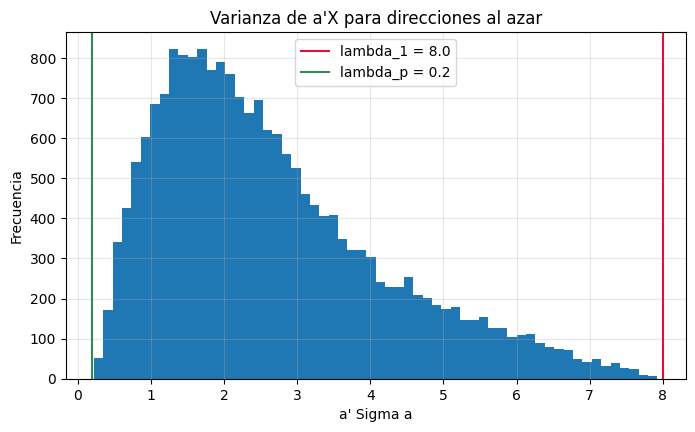

La mejor de 20,000 direcciones: 7.927; lambda_1 = 8.000
✅ Ninguna dirección supera a lambda_1
✅ Ninguna dirección queda por debajo de lambda_p


In [19]:
# TU CÓDIGO AQUÍ:

# 20,000 vectores al azar en 5 dimensiones (una dirección por fila)
direcciones = rng_pca.normal(size=(20_000, P_PCA))
# Se divide cada fila entre su norma para que tenga largo 1 (dirección unitaria)
direcciones = direcciones / np.linalg.norm(direcciones, axis=1, keepdims=True)
varianzas = ((direcciones @ Sigma) * direcciones).sum(axis=1)

# histograma de las 20,000 varianzas (60 barras)
plt.hist(varianzas, bins=60)
plt.axvline(lambdas[0], color="crimson", label=f"lambda_1 = {lambdas[0]:.1f}")
plt.axvline(lambdas[-1], color="seagreen", label=f"lambda_p = {lambdas[-1]:.1f}")
plt.gca().set(title="Varianza de a'X para direcciones al azar", xlabel="a' Sigma a", ylabel="Frecuencia"); plt.legend(); plt.show()
print(f"La mejor de 20,000 direcciones: {varianzas.max():.3f}; lambda_1 = {lambdas[0]:.3f}")
comprobar(varianzas.max() <= lambdas[0] + 1e-9, "Ninguna dirección supera a lambda_1")
comprobar(varianzas.min() >= lambdas[-1] - 1e-9, "Ninguna dirección queda por debajo de lambda_p")

Todas las varianzas quedan entre 0.2 y 8, que son el menor y el mayor valor propio. La mejor de las 20,000 direcciones llega a 7.927, muy cerca de 8 pero sin superarlo así que ninguna le gana al primer componente principal. La mayoría de las direcciones tienen varianzas entre 1 y 3 y las cercanas a 8 son muy raras. Por eso buscar la dirección de máxima varianza al azar es muy ineficiente mientras que la teoría la encuentra de forma exacta.

### Paso 3.3. Muestrear el vector aleatorio

Genera $n$ realizaciones de $X\sim N(\mu,\Sigma)$ y calcula la PCA **muestral**, para $n\in\{30,100,1000,10000\}$. Reporta $\hat\lambda_1$ y el ángulo entre $\hat a_1$ y $a_1$. Como $a$ y $-a$ son la misma dirección, usa $\theta=\arccos|\hat a_1^\top a_1|$.

**EXPLICACION** En la práctica no conocemos Σ; solo datos. Por eso generamos muestras de distintos tamaños (30, 100, 1,000 y 10,000 observaciones) y calculamos la PCA con cada una. Así medimos qué tan cerca quedan sus resultados de los verdaderos conforme crece la muestra.

In [20]:
def angulo(u, v):
    return np.degrees(np.arccos(np.clip(abs(u @ v) / (np.linalg.norm(u) * np.linalg.norm(v)), 0, 1)))


filas = []
for n in [30, 100, 1000, 10_000]:
    # TU CÓDIGO AQUÍ:

    # se generan n datos del vector aleatorio con media mu y covarianza Sigma
    muestra = rng_pca.multivariate_normal(mu, Sigma, size=n)
    # PCA muestral: centra los datos y obtiene los componentes de su covarianza
    pca_n = PCA().fit(muestra)
    l1 = pca_n.explained_variance_[0]  # primer valor propio muestral
    a1 = pca_n.components_[0]          # primer vector propio muestral

    filas.append({"n": n, "lambda_1 muestral": l1, "error relativo": abs(l1 / lambdas[0] - 1), "ángulo con a_1 (grados)": angulo(a1, vectores[:, 0])})
convergencia = pd.DataFrame(filas).set_index("n")
display(convergencia)
comprobar(convergencia["ángulo con a_1 (grados)"].iloc[-1] < convergencia["ángulo con a_1 (grados)"].iloc[0],
          "El componente muestral se acerca al poblacional cuando crece n")

Y = (muestra - mu) @ vectores
display(pd.DataFrame(np.cov(Y.T)).round(2))
comprobar(np.allclose(np.cov(Y.T), np.diag(lambdas), atol=0.5), "Los componentes son casi no correlacionados, con Var(Y_k) = lambda_k")

,lambda_1 muestral,error relativo,ángulo con a_1 (grados)
n,,,
30,10.5051,0.3131,5.1496
100,9.0843,0.1355,2.8918
1000,7.9449,0.0069,1.1605
10000,8.0566,0.0071,0.8414


✅ El componente muestral se acerca al poblacional cuando crece n


,0,1,2,3,4
0,8.0600,0.0200,0.0900,0.0300,-0.0100
1,0.0200,3.0000,0.0200,-0.0100,-0.0000
2,0.0900,0.0200,1.5200,0.0100,-0.0000
3,0.0300,-0.0100,0.0100,0.5000,0.0000
4,-0.0100,-0.0000,-0.0000,0.0000,0.2000


✅ Los componentes son casi no correlacionados, con Var(Y_k) = lambda_k


Conforme crece la muestra, la PCA se acerca a la verdadera. Con 30 observaciones, el primer valor propio sale en 10.51 en lugar de 8, un error de 31 %; con 1,000 o más el error baja a menos de 1 %. Además, los componentes casi no están correlacionados y su varianza coincide con los valores propios.

### Paso 3.4. PCA desde un vector inicial aleatorio (método de la potencia)

Ahora, **sin `eigh` ni `sklearn`**. Parte de un vector aleatorio $v_0$ y repite

$$v_{t+1}=\frac{\Sigma v_t}{\lVert\Sigma v_t\rVert}.$$

Cada multiplicación amplifica más la dirección de $\lambda_1$, y el error cae como $(\lambda_2/\lambda_1)^t$. Para el siguiente componente, **deflaciona**: $\Sigma\leftarrow\Sigma-\lambda_1a_1a_1^\top$ y repite.

Completa `metodo_potencia` y `pca_por_potencia`. El valor propio se estima con $\hat\lambda=v^\top\Sigma v$.

**EXPLICACION** Ahora obtenemos los componentes principales sin usar funciones de Python. Usamos el método de la potencia: partimos de un vector al azar y lo multiplicamos varias veces por Σ hasta que apunta en la dirección del primer componente. Después quitamos ese componente y repetimos para encontrar los siguientes. Al final comparamos el resultado con la solución teórica y vemos qué tan rápido llega a ella.

,Potencia,eigh,Ángulo (grados)
0,8.0000,8.0000,0.0000
1,3.0000,3.0000,0.0000
2,1.5000,1.5000,0.0000
3,0.5000,0.5000,0.0000
4,0.2000,0.2000,0.0000


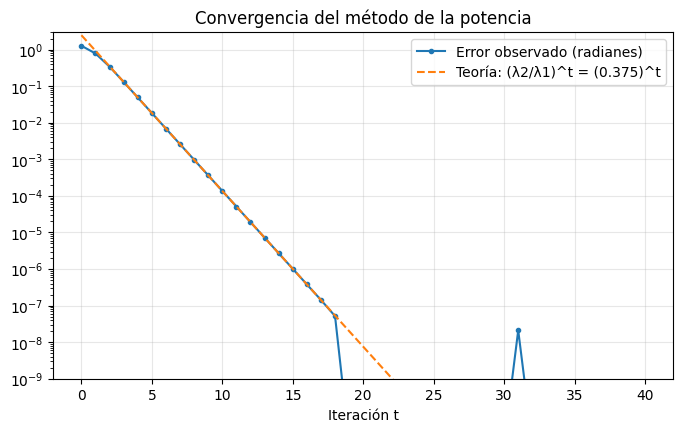

✅ Los valores propios coinciden con eigh
✅ Los vectores coinciden con eigh, salvo el signo


In [21]:
def metodo_potencia(S, rng, iteraciones=200):
    # regresa el valor propio, el vector propio y la lista con el vector de cada iteracion
    # TU CÓDIGO AQUÍ:

     # Vector inicial aleatorio de norma 1
    v = rng.normal(size=S.shape[0])
    v = v / np.linalg.norm(v)
    historia = [v]
    for _ in range(iteraciones):
        # Multiplicar por S amplifica la dirección del mayor valor propio
        w = S @ v
        # Se normaliza para que el vector no crezca sin límite
        v = w / np.linalg.norm(w)
        historia.append(v)
    # Valor propio estimado con el cociente de Rayleigh
    lam = v @ S @ v
    return lam, v, historia



def pca_por_potencia(S, k, rng, iteraciones=200):
     # regresa los k valores propios y una matriz con los k vectores propios en columnas
    # TU CÓDIGO AQUÍ:
    S_actual = S.copy()  # copia, para no modificar la matriz original
    lams, vecs = [], []
    for _ in range(k):
        lam, v, _ = metodo_potencia(S_actual, rng, iteraciones)
        lams.append(lam)
        vecs.append(v)
        # Deflación: se quita el componente encontrado para que el siguiente sea el mayor
        S_actual = S_actual - lam * np.outer(v, v)
    # Valores propios como arreglo y vectores como columnas de una matriz p x k
    return np.array(lams), np.column_stack(vecs)


lam_pot, vec_pot = pca_por_potencia(Sigma, P_PCA, np.random.default_rng(SEMILLA))
display(pd.DataFrame({"Potencia": lam_pot, "eigh": lambdas, "Ángulo (grados)": [angulo(vec_pot[:, k], vectores[:, k]) for k in range(P_PCA)]}))

_, _, historia = metodo_potencia(Sigma, np.random.default_rng(SEMILLA), 40)
errores = np.array([np.radians(max(angulo(v, vectores[:, 0]), 1e-9)) for v in historia])
t = np.arange(len(errores))
teorica = errores[3] * (lambdas[1] / lambdas[0]) ** (t - 3)
plt.semilogy(t, errores, "o-", ms=3, label="Error observado (radianes)")
plt.semilogy(t, teorica, "--", label=f"Teoría: (λ2/λ1)^t = ({lambdas[1]/lambdas[0]:.3f})^t")
plt.gca().set(title="Convergencia del método de la potencia", xlabel="Iteración t", ylim=(1e-9, 3)); plt.legend(); plt.show()
comprobar(np.allclose(lam_pot, lambdas, atol=1e-6), "Los valores propios coinciden con eigh")
comprobar(all(angulo(vec_pot[:, k], vectores[:, k]) < 0.01 for k in range(P_PCA)), "Los vectores coinciden con eigh, salvo el signo")

El método de la potencia obtiene los mismos cinco valores propios y vectores que la solución teórica. En la gráfica, el error baja muy rápido y sigue la línea que predice la teoría. en unas 18 iteraciones ya es casi 0. Lo que se ve después de esa iteración es solo error de redondeo de la computadora, no una falla del método.

### Paso 3.5. Datos reales: el factor de mercado

Aplica tu `pca_por_potencia` a la matriz de **correlación** de los 30 sectores (periodo de entrenamiento). Usamos correlación para que un sector volátil, como Coal, no domine solo por su escala. Calcula:

- `var_explicada`: proporción de varianza de cada uno de los 5 componentes;
- `pc1`: serie de $Y_1=a_1^\top Z$, con $Z$ los excesos estandarizados;
- `corr_mercado`: correlación absoluta de `pc1` con `Mkt-RF`.

**EXPLICACION** Aplicamos el método de la potencia a los 30 sectores reales. Usamos la matriz de correlación para que ningún sector domine solo por ser más volátil. Queremos saber cuánta varianza explica el primer componente y si se parece al rendimiento del mercado.

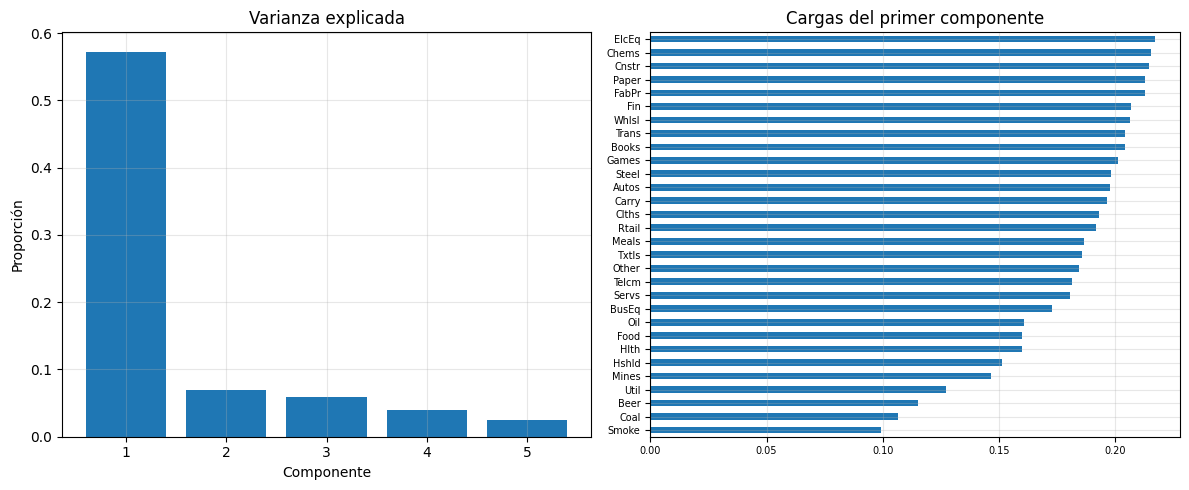

Varianza explicada: [0.572 0.07  0.059 0.039 0.025]; acumulada a 5: 0.765
Correlación absoluta del primer componente con el mercado: 0.949
✅ Tu método coincide con eigvalsh
✅ El primer componente se parece al mercado


In [22]:
Z = (excesos.loc[ENTRENA] - excesos.loc[ENTRENA].mean()) / excesos.loc[ENTRENA].std()
R = Z.corr().to_numpy()
# TU CÓDIGO AQUÍ:

# método de la potencia sobre la matriz de correlación de los 30 sectores (5 componentes)
# Se usan más iteraciones porque aquí los valores propios menores están más cerca entre sí
lam_R, vec_R = pca_por_potencia(R, 5, np.random.default_rng(SEMILLA), iteraciones=2000)

# En una matriz de correlación la varianza total es el número de variables (30)
# así que la proporción explicada por cada componente es lambda / 30
var_explicada = lam_R / R.shape[0]

# # valor del primer componente en cada mes
pc1 = pd.Series(Z.to_numpy() @ vec_R[:, 0], index=Z.index)

# correlacion del primer componente con el rendimiento del mercado
corr_mercado = abs(np.corrcoef(pc1, datos.loc[ENTRENA, "Mkt-RF"])[0, 1])

# cargas = peso de cada sector en el primer componente
cargas = pd.Series(vec_R[:, 0] * np.sign(vec_R[:, 0].sum()), index=SECTORES).sort_values()
# dos graficas: varianza explicada de los 5 componentes y cargas de cada sector
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
ejes[0].bar(range(1, 6), var_explicada)
ejes[0].set(title="Varianza explicada", xlabel="Componente", ylabel="Proporción")
cargas.plot.barh(ax=ejes[1], fontsize=7, title="Cargas del primer componente")
plt.tight_layout(); plt.show()
print(f"Varianza explicada: {np.round(var_explicada, 3)}; acumulada a 5: {var_explicada.sum():.3f}")
print(f"Correlación absoluta del primer componente con el mercado: {corr_mercado:.3f}")
comprobar(np.allclose(lam_R, np.sort(np.linalg.eigvalsh(R))[::-1][:5], atol=1e-3), "Tu método coincide con eigvalsh")
comprobar(corr_mercado > 0.8, "El primer componente se parece al mercado")

El primer componente explica el 57.2 % de la varianza de los 30 sectores, mientras que el segundo solo explica el 7.0 %. Es decir, hay una fuerza común que mueve a casi todas las industrias. Ese componente es el factor de mercado, su correlación con el rendimiento del mercado es de 0.949, y todos los sectores tienen carga positiva y de un tamaño similar. Los sectores que más se mueven con él son los industriales, como ElcEq y Chems, y los que menos son los defensivos, como Smoke y Beer, y los de materias primas, como Coal.

✍️ **Pregunta 3.**

1. ¿Qué pasa con la velocidad de convergencia del método de la potencia si $\lambda_2/\lambda_1\approx 1$? ¿Y si $v_0$ fuera exactamente ortogonal a $a_1$? ¿Por qué elegirlo al azar resuelve este último problema?
2. ¿Cuántos $n$ se necesitan para que el ángulo baje de 5°? Usa tu tabla `convergencia`.
3. Interpreta económicamente el primer componente de los sectores. ¿Qué implica para la diversificación y para la multicolinealidad de la Parte 2?

**✍️ Tu respuesta (con los números de TU equipo):**

**1. ¿Qué pasa con la velocidad de convergencia si λ₂/λ₁ ≈ 1? ¿Y si v₀ fuera exactamente ortogonal a a₁? ¿Por qué elegirlo al azar resuelve este último problema?**

El error del método baja en cada iteración según la razón λ₂/λ₁. En mi ejemplo es 3/8 = 0.375, así que converge rápido. Si la razón fuera cercana a 1, el método convergería muy lento, porque los dos primeros componentes serían casi igual de importantes. Si v₀ fuera exactamente ortogonal a a₁, no tendría ninguna parte en esa dirección y el método nunca la encontraría. Elegirlo al azar lo resuelve porque la probabilidad de caer exactamente en un vector ortogonal es prácticamente 0.

**2. ¿Cuántos n se necesitan para que el ángulo baje de 5°?**

de los tamaños probados, se necesitan 100 observaciones para que el ángulo sea menor que 5°.

**3. Interpretación económica del primer componente. ¿Qué implica para la diversificación y para la multicolinealidad de la Parte 2?**

El primer componente es el factor de mercado: explica el 57.2 % de la varianza de los sectores y tiene una correlación de 0.949 con el mercado. Representa el riesgo económico general que afecta a todas las empresas al mismo tiempo. Para la diversificación, implica que combinar sectores reduce el riesgo de cada industria, pero no el riesgo del mercado. Para la multicolinealidad, este factor común es la razón por la que los sectores están correlacionados entre sí, aunque la multicolinealidad sigue siendo moderada.

# Parte 4. Solución a Markowitz

Con media $\mu$, covarianza $\Sigma$ invertible y pesos $w$, buscamos el portafolio de mínima varianza para un rendimiento $m$:

$$\min_{w}\ \tfrac12w^\top\Sigma w\quad\text{sujeto a}\quad w^\top\mu=m,\quad w^\top\mathbf 1=1.$$

**Lagrangiano y CPO:** $\mathcal{L}=\tfrac12w^\top\Sigma w-\delta(w^\top\mu-m)-\gamma(w^\top\mathbf 1-1)$ da $\Sigma w=\delta\mu+\gamma\mathbf 1$, por lo que

$$w=\delta\,\Sigma^{-1}\mu+\gamma\,\Sigma^{-1}\mathbf 1.$$

Sustituyendo en las restricciones, con

$$A=\mathbf 1^\top\Sigma^{-1}\mu,\quad B=\mu^\top\Sigma^{-1}\mu,\quad C=\mathbf 1^\top\Sigma^{-1}\mathbf 1,\quad D=BC-A^2,$$

se obtiene

$$\delta=\frac{Cm-A}{D},\qquad\gamma=\frac{B-Am}{D},\qquad\sigma^2(m)=\frac{Cm^2-2Am+B}{D}.$$

**Casos especiales:**

| Portafolio | Pesos | Condición |
|---|---|---|
| Mínima varianza global (GMV) | $w_g=\Sigma^{-1}\mathbf 1/C$, con $m_g=A/C$ | Ninguna |
| Tangente (máximo Sharpe) | $w_t=\Sigma^{-1}(\mu-r_f\mathbf 1)/(A-Cr_f)$ | $r_f<A/C$ |

### Paso 4.1. Implementar la solución cerrada

Trabajamos con rendimientos **anualizados** de tus 12 `ACTIVOS`, estimados solo con entrenamiento. Completa `constantes` y `pesos_frontera`, `pesos_gmv` y `pesos_tangente`. Evita `np.linalg.inv`: usa `np.linalg.solve(S, b)`, que es más estable.

**Qué vamos a hacer y por qué.** Se programa la solución de Markowitz con nuestros 12 activos, usando los rendimientos anuales del periodo de entrenamiento. Con ella calculamos los pesos de tres tipos de portafolio: los de la frontera eficiente, el de mínima varianza global (GMV) y el tangente que es el de mayor rendimiento por unidad de riesgo.

In [23]:
def constantes(mu_v, S):
    # TU CÓDIGO AQUÍ: regresa A, B, C, D
    uno = np.ones(len(mu_v))
    S_inv_mu = np.linalg.solve(S, mu_v)
    S_inv_1 = np.linalg.solve(S, uno)
    # las 4 constantes de Markowitz
    A = uno @ S_inv_mu
    B = mu_v @ S_inv_mu
    C = uno @ S_inv_1
    D = B * C - A ** 2
    return A, B, C, D


def pesos_frontera(m, mu_v, S):
    # TU CÓDIGO AQUÍ:
    # portafolio de menor varianza que rinde m y cuyos pesos suman 1
    A, B, C, D = constantes(mu_v, S)
    uno = np.ones(len(mu_v))
    # multiplicadores de Lagrange
    delta = (C * m - A) / D
    gamma = (B - A * m) / D
    return delta * np.linalg.solve(S, mu_v) + gamma * np.linalg.solve(S, uno)


def pesos_gmv(S):
    # TU CÓDIGO AQUÍ:
    # portafolio de minima varianza global
    uno = np.ones(S.shape[0])
    S_inv_1 = np.linalg.solve(S, uno)
    return S_inv_1 / (uno @ S_inv_1)


def pesos_tangente(mu_v, S, rf):
   # TU CÓDIGO AQUÍ:
   # portafolio con mayor Sharpe: w = Sigma^-1 (mu - rf) / (A - C rf)
    A, B, C, D = constantes(mu_v, S)
    uno = np.ones(len(mu_v))
     # mu - rf * uno = rendimiento de cada activo menos la tasa libre de riesgo
    return np.linalg.solve(S, mu_v - rf * uno) / (A - C * rf)

def desempeno(w, mu_v, S):
    return w @ mu_v, np.sqrt(w @ S @ w)

# rendimientos mensuales de nuestros 12 activos en el entrenamiento
rend = datos.loc[ENTRENA, ACTIVOS]
mu_a = rend.mean().to_numpy() * 12
Sigma_a = rend.cov().to_numpy() * 12
rf_a = datos.loc[ENTRENA, "RF"].mean() * 12
A, B, C, D = constantes(mu_a, Sigma_a)
print(f"A={A:.4f}  B={B:.4f}  C={C:.6f}  D={D:.4f}  m_gmv={A/C:.2f}%  rf={rf_a:.2f}%")
print(f"Condición de Sigma: {np.linalg.cond(Sigma_a):.1f}")


m_ejemplo = mu_a.mean()
w_m, w_g, w_t = pesos_frontera(m_ejemplo, mu_a, Sigma_a), pesos_gmv(Sigma_a), pesos_tangente(mu_a, Sigma_a, rf_a)
comprobar(abs(w_m.sum() - 1) < 1e-8 and abs(w_m @ mu_a - m_ejemplo) < 1e-8, "w_m cumple las dos restricciones")
comprobar(abs(w_m @ Sigma_a @ w_m - (C * m_ejemplo ** 2 - 2 * A * m_ejemplo + B) / D) < 1e-6, "La varianza coincide con la fórmula cerrada")
comprobar(rf_a < A / C, "rf < A/C: el portafolio tangente es eficiente")
comprobar(abs(w_t.sum() - 1) < 1e-8, "Los pesos tangentes suman 1")

A=0.0752  B=1.6297  C=0.008912  D=0.0089  m_gmv=8.43%  rf=1.62%
Condición de Sigma: 89.2
✅ w_m cumple las dos restricciones
✅ La varianza coincide con la fórmula cerrada
✅ rf < A/C: el portafolio tangente es eficiente
✅ Los pesos tangentes suman 1


El portafolio de mínima varianza global tiene un rendimiento esperado de 8.43 % anual. La tasa libre de riesgo promedio fue de 1.62 % menor que ese rendimiento, por lo que el portafolio tangente existe y es eficiente. Las comprobaciones confirman que la solución está bien calculada. El número de condición de Σ es 89.2: indica que pequeños errores al estimar los rendimientos o las covarianzas pueden cambiar mucho los pesos óptimos.

**EXPLICACION** Este paso es extra. Mostramos cuánto invierte en cada activo el portafolio de mínima varianza (GMV) y el portafolio tangente. Así vemos qué tan concentrados son y cuántas ventas en corto (pesos negativos) necesitan.

In [24]:
#EXTRA
# Pesos de la GMV y de la tangente estimados con entrenamiento
pd.DataFrame({"GMV": w_g, "Tangente": w_t}, index=ACTIVOS).round(3)

,GMV,Tangente
Autos,-0.0630,-0.1100
Beer,0.1230,0.0550
Books,-0.0150,-0.7400
Chems,-0.2260,-0.0360
Coal,0.0390,-0.0590
FabPr,0.0230,0.5310
Food,0.5270,0.4120
Hshld,0.2400,0.0010
Meals,0.1740,0.6320
Other,0.1910,-0.3450


El portafolio GMV invierte sobre todo en sectores de bajo riesgo, como Food (52.7 %) y Hshld (24.0 %), y tiene pocas ventas en corto. El portafolio tangente es mucho más extremo, invierte 63.2 % en Meals y vende en corto 74.0 % de Books, y en total sus ventas en corto suman casi 129 % del capital. Esto pasa porque la tangente depende de los rendimientos esperados, que son muy difíciles de estimar, y pequeños errores en ellos generan pesos muy grandes.

### Paso 4.2. Comprobar con un optimizador numérico

Verifica la solución cerrada con `scipy.optimize.minimize` (`method="SLSQP"`). Completa `optimizar`, que además admitirá la prohibición de ventas en corto mediante `bounds`.

**EXPLICACION** Resolvemos el mismo problema con un optimizador numérico, que busca la solución paso a paso, para comprobar que la fórmula de Markowitz está bien. Además, este método permite prohibir las ventas en corto, algo que la fórmula no puede hacer.

In [25]:
def optimizar(m, mu_v, S, en_corto=True):
    n = len(mu_v)
    restricciones = [{"type": "eq", "fun": lambda w: w.sum() - 1}, {"type": "eq", "fun": lambda w: w @ mu_v - m}]
    limites = None if en_corto else [(0, 1)] * n
    # TU CÓDIGO AQUÍ:
    # minimize busca los pesos que hacen mas chica la mitad de la varianza
    # sujeto a las dos restricciones y, si en_corto=False, a pesos entre 0 y 1
    solucion = minimize(lambda w: 0.5 * w @ S @ w, np.ones(n) / n, method="SLSQP",
                        constraints=restricciones, bounds=limites,
                        options={"ftol": 1e-12, "maxiter": 2000})
    return solucion.x


w_num = optimizar(m_ejemplo, mu_a, Sigma_a)
print(f"Máxima diferencia entre pesos, cerrada vs. numérica: {np.abs(w_num - w_m).max():.2e}")
comprobar(np.abs(w_num - w_m).max() < 1e-2, "La solución numérica coincide con la cerrada")

Máxima diferencia entre pesos, cerrada vs. numérica: 1.16e-08
✅ La solución numérica coincide con la cerrada


El optimizador numérico llega prácticamente a los mismos pesos que la fórmula de Markowitz: la diferencia máxima es de 0.00000001, que es solo error de redondeo. Esto confirma que la fórmula está bien. La fórmula da la solución exacta de inmediato, mientras que el optimizador tiene la ventaja de permitir restricciones adicionales, como prohibir las ventas en corto.

### Paso 4.3. La frontera eficiente

Construye para una malla de rendimientos: `frontera_sigma` (fórmula cerrada) y `sigma_sin_corto` (con `optimizar(..., en_corto=False)`, solo para `malla_sc`, ya que sin ventas en corto el rendimiento no puede salir del rango de los activos). Calcula también `sharpe_t`, la pendiente de la línea del mercado de capitales.

**EXPLICACION** Graficamos la frontera eficiente con y sin ventas en corto, que muestra el mayor rendimiento posible para cada nivel de riesgo. En la misma gráfica ubicamos los 12 sectores, el portafolio de mínima varianza, el portafolio tangente y la línea del mercado de capitales. Todo se calcula con los datos de entrenamiento.

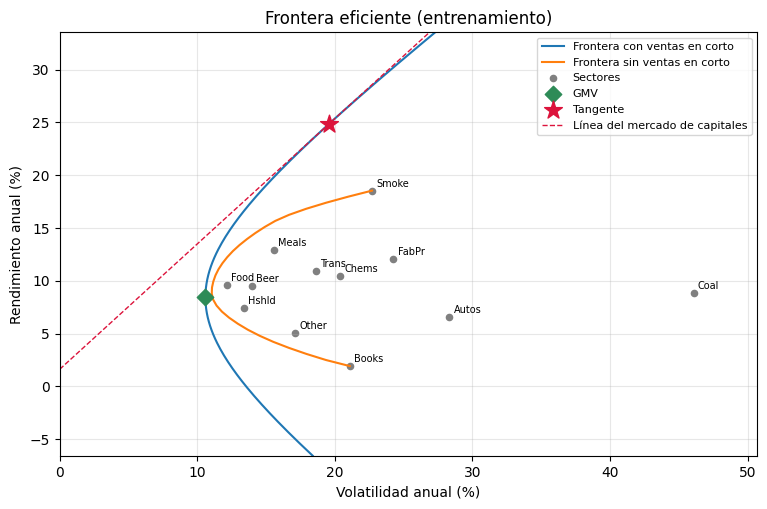

✅ Prohibir ventas en corto nunca reduce el riesgo
✅ El Sharpe tangente cumple H = B - 2A rf + C rf²


In [26]:
malla = np.linspace(A / C - 15, mu_a.max() + 15, 200)
malla_sc = np.linspace(mu_a.min() + 1e-3, mu_a.max() - 1e-3, 30)
# TU CÓDIGO AQUÍ:
# frontera con ventas en corto: formula del ejercicio en papel
frontera_sigma = np.sqrt((C * malla ** 2 - 2 * A * malla + B) / D)

# Frontera sin ventas en corto: no hay fórmula cerrada, se optimiza para cada m con pesos entre 0 y 1
sigma_sin_corto = np.array([
    desempeno(optimizar(m, mu_a, Sigma_a, en_corto=False), mu_a, Sigma_a)[1]
    for m in malla_sc
])

# Sharpe del portafolio tangente: (rendimiento - rf) / volatilidad
rend_t, vol_t = desempeno(w_t, mu_a, Sigma_a)
sharpe_t = (rend_t - rf_a) / vol_t

# rendimiento y volatilidad de la GMV y de la tangente

m_g, s_g = desempeno(w_g, mu_a, Sigma_a)
m_t, s_t = desempeno(w_t, mu_a, Sigma_a)
# grafica: volatilidad en el eje x y rendimiento en el eje y
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(frontera_sigma, malla, label="Frontera con ventas en corto")
ax.plot(sigma_sin_corto, malla_sc, label="Frontera sin ventas en corto")
ax.scatter(np.sqrt(np.diag(Sigma_a)), mu_a, c="gray", s=20, label="Sectores")
# nombre de cada activo junto a su punto
for nombre, xx, yy in zip(ACTIVOS, np.sqrt(np.diag(Sigma_a)), mu_a):
    ax.annotate(nombre, (xx, yy), fontsize=7, xytext=(3, 3), textcoords="offset points")
    # GMV como rombo verde y tangente como estrella roja
ax.scatter([s_g], [m_g], marker="D", s=70, color="seagreen", label="GMV", zorder=3)
ax.scatter([s_t], [m_t], marker="*", s=180, color="crimson", label="Tangente", zorder=3)
# linea del mercado de capitales: empieza en rf y su pendiente es el Sharpe de la tangente
x_lmc = np.array([0, frontera_sigma.max()])
ax.plot(x_lmc, rf_a + sharpe_t * x_lmc, "--", color="crimson", lw=1, label="Línea del mercado de capitales")
ax.set(xlabel="Volatilidad anual (%)", ylabel="Rendimiento anual (%)", title="Frontera eficiente (entrenamiento)",
       xlim=(0, max(np.sqrt(np.diag(Sigma_a)).max() * 1.1, s_t * 1.1)), ylim=(malla.min(), malla.max()))
ax.legend(fontsize=8); plt.show()

sigma_cerrada_sc = np.sqrt((C * malla_sc ** 2 - 2 * A * malla_sc + B) / D)
comprobar(np.all(sigma_sin_corto >= sigma_cerrada_sc - 1e-4), "Prohibir ventas en corto nunca reduce el riesgo")
comprobar(abs(sharpe_t - np.sqrt(B - 2 * A * rf_a + C * rf_a ** 2)) < 1e-6, "El Sharpe tangente cumple H = B - 2A rf + C rf²")

**Interpretación.** El portafolio de mínima varianza tiene una volatilidad de 10.6 % anual, menor que la de cualquier sector por separado; ese es el beneficio de diversificar. El portafolio tangente tiene un Sharpe de 1.19, mucho mayor que el del mejor sector (0.75), pero solo lo logra con ventas en corto muy grandes. La frontera sin ventas en corto siempre queda a la derecha, es decir, con más riesgo. Sin embargo, estos resultados son optimistas, porque usan los mismos datos con los que se estimaron los parámetros.

### Paso 4.4. Teorema de los dos fondos

**Afirmación:** todo portafolio de la frontera es combinación de dos portafolios cualesquiera de ella. Encuentra el `alfa` tal que $w_m=\alpha w_g+(1-\alpha)w_t$ para tu `m_ejemplo`.

**Qué vamos a hacer y por qué.** Comprobamos el teorema de los dos fondos, que dice que cualquier portafolio de la frontera se puede formar combinando otros dos portafolios de la frontera. Para ello buscamos qué proporción del portafolio de mínima varianza y del tangente produce  un portafolio de la frontera.

In [27]:
# TU CÓDIGO AQUÍ:
alfa = (m_ejemplo - m_t) / (m_g - m_t)
# Portafolio que combina los dos fondos con ese alfa
w_dos_fondos = alfa * w_g + (1 - alfa) * w_t
print(f"alfa = {alfa:.3f}")
comprobar(np.allclose(w_dos_fondos, w_m, atol=1e-6), "La combinación de dos fondos reproduce el portafolio de la frontera")

alfa = 0.936
✅ La combinación de dos fondos reproduce el portafolio de la frontera


El portafolio de la frontera con rendimiento de 9.48 % se forma exactamente con 93.6 % en el portafolio de mínima varianza y 6.4 % en el tangente. Casi todo va al de mínima varianza porque su rendimiento (8.43 %) está muy cerca de 9.48 %. Esto confirma el teorema de los dos fondos: un inversionista no necesita una mezcla distinta de los 12 activos para cada nivel de riesgo, sino que solo se necesitan dos portafolios y decidir cuánto invertir en cada uno.

### Paso 4.5. La prueba real: fuera de muestra

La frontera de arriba es **ilusoria**: usa los mismos datos con los que se optimizó. Compara las estrategias, estimadas con entrenamiento, en el periodo de **prueba**:

| Estrategia | Pesos |
|---|---|
| `1/N` | Iguales |
| `GMV muestral` | $w_g$ con $\hat\Sigma$ |
| `Tangente muestral` | $w_t$ con $\hat\mu,\hat\Sigma$ |
| `GMV Ledoit-Wolf` | $w_g$ con el estimador encogido `LedoitWolf().fit(rend).covariance_ * 12` |
| `GMV PCA` | $w_g$ con $\hat\Sigma_{\text{PCA}}$, de 3 componentes más la diagonal residual |
| `Tangente sin corto` | Máximo Sharpe con $w\geq 0$ (ya implementado) |

Completa `covarianza_pca` y el diccionario `estrategias`. La celda rebalancea cada mes a los mismos pesos y no incluye costos de transacción. El Sharpe es anualizado y usa exceso sobre `RF`.

**EXPLICACION** La frontera del paso anterior es optimista porque se evaluó con los mismos datos con los que se calculó. Por eso estimamos seis estrategias con los datos de entrenamiento y medimos cómo les fue realmente en 2020-2026. Así comparamos su desempeño esperado con su desempeño real.

In [28]:
def covarianza_pca(S, k=3):
    # TU CÓDIGO AQUÍ:
    valores, vecs = np.linalg.eigh(S)
    orden = np.argsort(valores)[::-1][:k]
    A_k = vecs[:, orden]
    # los k vectores mas grandes (se llama A_k para no borrar la constante A de Markowitz)
    S_k = A_k @ np.diag(valores[orden]) @ A_k.T
    # Lo que no explican se conserva solo en la diagonal (varianza propia de cada activo)
    return S_k + np.diag(np.diag(S - S_k))


def tangente_sin_corto(mu_v, S, rf):
    n = len(mu_v)
    negativo_sharpe = lambda w: -(w @ mu_v - rf) / np.sqrt(w @ S @ w)
    return minimize(negativo_sharpe, np.ones(n) / n, method="SLSQP", bounds=[(0, 1)] * n,
                    constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}], options={"maxiter": 1000}).x


Sigma_lw = LedoitWolf().fit(rend).covariance_ * 12
Sigma_pca = covarianza_pca(Sigma_a)
# TU CÓDIGO AQUÍ:
# Las seis estrategias, todas estimadas solo con datos de entrenamiento
estrategias = {
    "1/N": np.ones(len(ACTIVOS)) / len(ACTIVOS), # mismo peso en cada activo
    "GMV muestral": pesos_gmv(Sigma_a), # minima varianza con Sigma de los datos
    "Tangente muestral": pesos_tangente(mu_a, Sigma_a, rf_a), # mayor Sharpe con mu y Sigma de los datos
    "GMV Ledoit-Wolf": pesos_gmv(Sigma_lw),  # minima varianza con Sigma encogida
    "GMV PCA": pesos_gmv(Sigma_pca), # minima varianza con Sigma de 3 componentes
    "Tangente sin corto": tangente_sin_corto(mu_a, Sigma_a, rf_a), # mayor Sharpe sin pesos negativos
}

# como le fue a cada portafolio en la prueba (2020-2026)
def resultado_prueba(w):
  # rendimiento mensual del portafolio en la prueba y su exceso sobre la tasa libre de riesgo
    r = datos.loc[PRUEBA, ACTIVOS].to_numpy() @ w
    exceso = r - datos.loc[PRUEBA, "RF"].to_numpy()
    # cuanto valdria 1 peso invertido, mes a mes (rendimientos acumulados)
    acumulado = np.cumprod(1 + r / 100)
    return {
        "Rendimiento anual (%)": r.mean() * 12,
        "Volatilidad anual (%)": r.std(ddof=1) * np.sqrt(12),
        "Sharpe prueba": exceso.mean() / exceso.std(ddof=1) * np.sqrt(12),
        # peor caida desde un maximo anterior (maximum.accumulate = el valor mas alto hasta ese mes)
        "Máx. caída (%)": 100 * (1 - acumulado / np.maximum.accumulate(acumulado)).max(),
        "Mayor peso abs.": np.abs(w).max(),
        "Suma pesos cortos": w[w < 0].sum(),
        # Sharpe con los mismos datos con los que se optimizo
        "Sharpe entrenamiento (optimista)": (w @ mu_a - rf_a) / np.sqrt(w @ Sigma_a @ w),
    }

# tabla con una fila por estrategia
tabla_prueba = pd.DataFrame({n: resultado_prueba(w) for n, w in estrategias.items()}).T
display(tabla_prueba)
# numero de condicion de las tres Sigma
print(f"Condición de Sigma: muestral {np.linalg.cond(Sigma_a):.0f}, Ledoit-Wolf {np.linalg.cond(Sigma_lw):.0f}, PCA {np.linalg.cond(Sigma_pca):.0f}")
comprobar(all(abs(w.sum() - 1) < 1e-6 for w in estrategias.values()), "Todos los pesos suman 1")
comprobar(np.linalg.cond(Sigma_lw) < np.linalg.cond(Sigma_a), "Ledoit-Wolf mejora el condicionamiento (igual que Ridge)")

,Rendimiento anual (%),Volatilidad anual (%),Sharpe prueba,Máx. caída (%),Mayor peso abs.,Suma pesos cortos,Sharpe entrenamiento (optimista)
1/N,14.4046,18.2240,0.6361,24.0350,0.0833,0.0000,0.5222
GMV muestral,6.4394,14.6647,0.2495,18.4840,0.5265,-0.3668,0.6437
Tangente muestral,11.9273,25.3248,0.3616,22.1572,0.7400,-1.2901,1.1875
GMV Ledoit-Wolf,5.7754,14.7797,0.2028,18.8667,0.4142,-0.2579,0.6598
GMV PCA,-1.9361,17.3891,-0.2693,35.5897,0.5125,-0.6258,0.4208
Tangente sin corto,10.8311,16.8833,0.4768,21.6037,0.4923,0.0000,0.9075


Condición de Sigma: muestral 89, Ledoit-Wolf 59, PCA 59
✅ Todos los pesos suman 1
✅ Ledoit-Wolf mejora el condicionamiento (igual que Ridge)


el portafolio 1/N, con pesos iguales, tuvo el mayor Sharpe en 2020-2026 (0.636). En cambio, el portafolio tangente, que era el mejor en entrenamiento con un Sharpe de 1.19, cayó a 0.362 y perdió casi 70 % de su Sharpe. Esto pasa porque depende de los rendimientos esperados, que son muy difíciles de estimar, y apuesta fuerte a activos que solo parecían buenos en el pasado. Prohibir las ventas en corto ayudó, la tangente sin corto fue la segunda mejor (0.477). Los portafolios de mínima varianza sí lograron el menor riesgo, pero rindieron poco. La optimización de Markowitz pierde gran parte de su ventaja con datos nuevos.

### Paso 4.6. ¿Qué tan estables son los pesos?

Remuestrea 200 veces los meses de entrenamiento (*bootstrap*) y recalcula los pesos de la tangente y de la GMV. Guarda los pesos en las listas `pesos_t` y `pesos_g`. La celda resume la dispersión con el rango intercuartil, porque la tangente puede dar pesos enormes cuando $A-Cr_f$ se acerca a cero y eso distorsionaría una desviación estándar.

**EXPLICACION** Creamos 200 versiones distintas de los datos de entrenamiento, sorteando meses al azar (bootstrap). Con cada versión volvemos a calcular los pesos del portafolio tangente y del portafolio de mínima varianza. Así medimos qué tanto cambian los pesos con pequeñas variaciones en los datos.

In [29]:
rng_boot = np.random.default_rng(SEMILLA + 4)
r_ent = rend.to_numpy()
pesos_t, pesos_g = [], []
for _ in range(200):
    # TU CÓDIGO AQUÍ:
    # Remuestra de 240 meses sorteados con reemplazo
    idx = rng_boot.integers(0, len(r_ent), len(r_ent))
    muestra_b = r_ent[idx]
    # Media y covarianza anualizadas de esta remuestra
    mu_b = muestra_b.mean(axis=0) * 12
    S_b = np.cov(muestra_b, rowvar=False) * 12
    # Pesos óptimos recalculados con esta remuestra
    pesos_t.append(pesos_tangente(mu_b, S_b, rf_a))
    pesos_g.append(pesos_gmv(S_b))

pesos_t, pesos_g = np.array(pesos_t), np.array(pesos_g)
iqr = lambda m: np.subtract(*np.percentile(m, [75, 25], axis=0))
inestabilidad = pd.DataFrame({"Tangente (rango intercuartil)": iqr(pesos_t), "GMV (rango intercuartil)": iqr(pesos_g)}, index=ACTIVOS)
display(inestabilidad)
print(f"Rango intercuartil mediano: tangente {np.median(iqr(pesos_t)):.3f}, GMV {np.median(iqr(pesos_g)):.3f}")
comprobar(np.median(iqr(pesos_t)) > np.median(iqr(pesos_g)), "La tangente es más inestable que la GMV: depende de mu, muy difícil de estimar")

,Tangente (rango intercuartil),GMV (rango intercuartil)
Autos,0.3732,0.0745
Beer,0.5931,0.1211
Books,0.5809,0.0730
Chems,0.5991,0.1028
Coal,0.1791,0.0302
FabPr,0.5778,0.1001
Food,0.7171,0.1607
Hshld,0.5080,0.0917
Meals,0.5966,0.1058
Other,0.5811,0.0948


Rango intercuartil mediano: tangente 0.579, GMV 0.097
✅ La tangente es más inestable que la GMV: depende de mu, muy difícil de estimar


Los pesos del portafolio tangente cambian mucho más que los del portafolio de mínima varianza. Por ejemplo, según la muestra que toque, Food podría tener un peso pequeño o ser la mayor inversión del portafolio tangente. La razón es que el portafolio de mínima varianza solo depende de las covarianzas, mientras que el tangente también depende de los rendimientos esperados, que son mucho más difíciles de estimar. Esto explica por qué la tangente fue la estrategia que más perdió fuera de muestra en el Paso 4.5.

### Paso 4.7. Reestimar cada año

Una gestora real no fija los pesos durante años. Al inicio de cada año del periodo de prueba, estima con los **60 meses anteriores** y conserva esos pesos 12 meses, con rebalanceo mensual y sin costos. Completa `prueba_movil(regla)`, donde `regla(mu, S, rf, historia)` devuelve los pesos; `mu`, `S` y `rf` están anualizados y `historia` son los rendimientos de la ventana.

**EXPLICACION** Simulamos lo que haría un administrador de fondos real: al inicio de cada año, recalculamos los pesos con los datos de los últimos 5 años y los mantenemos durante los 12 meses siguientes. Así comparamos si actualizar los pesos cada año mejora el desempeño a comparacion de dejarlos fijos desde 2019.

In [30]:
def prueba_movil(regla, ventana=60):
    rendimientos = []
    for inicio in range(corte, len(datos), 12):
        historia = datos.iloc[inicio - ventana:inicio]
        # TU CÓDIGO AQUÍ:
        # Media, covarianza y tasa libre anualizadas con los 60 meses anteriores
        mu = historia[ACTIVOS].mean().to_numpy() * 12
        S = historia[ACTIVOS].cov().to_numpy() * 12
        rf = historia["RF"].mean() * 12
        # Pesos de esta regla para el año que empieza
        w = regla(mu, S, rf, historia[ACTIVOS])
        # Rendimientos del portafolio en los 12 meses siguientes (el último bloque tiene 9)
        bloque = datos.iloc[inicio:inicio + 12][ACTIVOS].to_numpy()
        rendimientos.extend(bloque @ w)

    return np.array(rendimientos)


reglas = {
    "1/N": lambda m, S, r, h: np.ones(len(m)) / len(m),
    "GMV muestral": lambda m, S, r, h: pesos_gmv(S),
    "GMV Ledoit-Wolf": lambda m, S, r, h: pesos_gmv(LedoitWolf().fit(h).covariance_ * 12),
    "Tangente muestral": lambda m, S, r, h: pesos_tangente(m, S, r),
    "Tangente sin corto": lambda m, S, r, h: tangente_sin_corto(m, S, r),
}
rf_prueba = datos.loc[PRUEBA, "RF"].to_numpy()
filas = {}
for nombre, regla in reglas.items():
    r = prueba_movil(regla)
    exceso = r - rf_prueba
    acumulado = np.cumprod(1 + np.maximum(r, -100) / 100)
    filas[nombre] = {"Rendimiento anual (%)": r.mean() * 12, "Volatilidad anual (%)": r.std(ddof=1) * np.sqrt(12),
                     "Sharpe": exceso.mean() / exceso.std(ddof=1) * np.sqrt(12),
                     "Máx. caída (%)": 100 * (1 - acumulado / np.maximum.accumulate(acumulado)).max()}
tabla_movil = pd.DataFrame(filas).T
display(tabla_movil)
comprobar(len(prueba_movil(reglas["1/N"])) == len(PRUEBA), "Hay un rendimiento por cada mes de prueba")

,Rendimiento anual (%),Volatilidad anual (%),Sharpe,Máx. caída (%)
1/N,14.4046,18.2240,0.6361,24.0350
GMV muestral,10.6540,17.3638,0.4529,21.7559
GMV Ledoit-Wolf,7.7037,16.3036,0.3017,21.5523
Tangente muestral,49.9562,49.3973,0.9560,53.2900
Tangente sin corto,12.3564,20.5873,0.4656,27.0899


✅ Hay un rendimiento por cada mes de prueba


**EXPLICACION** Este paso es extra. En la tabla anterior, el portafolio tangente reestimado tuvo el Sharpe más alto, pero también el mayor riesgo. Para entender por qué, podemos revisar año por año sus pesos más grandes, sus ventas en corto y su rendimiento, y hacer un analisis.

In [31]:
# EXTRA
# Diagnóstico año por año de la tangente muestral reestimada (ventana de 60 meses)
for inicio in range(corte, len(datos), 12):
    h = datos.iloc[inicio - 60:inicio]
    mu_h = h[ACTIVOS].mean().to_numpy() * 12
    S_h = h[ACTIVOS].cov().to_numpy() * 12
    rf_h = h["RF"].mean() * 12
    A_h, B_h, C_h, D_h = constantes(mu_h, S_h)
    w = pesos_tangente(mu_h, S_h, rf_h)
    r_anio = datos.iloc[inicio:inicio + 12][ACTIVOS].to_numpy() @ w
    print(f"{datos.index[inicio][:4]}: A/C = {A_h / C_h:5.2f}%, rf = {rf_h:4.2f}% | "
          f"mayor peso {np.abs(w).max():.2f}, cortos {w[w < 0].sum():.2f} | "
          f"rendimiento del año {100 * (np.prod(1 + r_anio / 100) - 1):6.1f}%, peor mes {r_anio.min():.1f}%")

2020: A/C = 10.17%, rf = 0.98% | mayor peso 1.36, cortos -2.24 | rendimiento del año   72.3%, peor mes -15.2%
2021: A/C =  7.51%, rf = 1.07% | mayor peso 3.93, cortos -7.45 | rendimiento del año   54.2%, peor mes -15.5%
2022: A/C =  9.12%, rf = 1.03% | mayor peso 3.36, cortos -6.45 | rendimiento del año  -42.8%, peor mes -28.0%
2023: A/C = 12.27%, rf = 1.15% | mayor peso 2.44, cortos -5.53 | rendimiento del año   27.6%, peor mes -11.1%
2024: A/C = 13.36%, rf = 1.76% | mayor peso 2.59, cortos -4.80 | rendimiento del año   43.8%, peor mes -19.5%
2025: A/C = 10.54%, rf = 2.36% | mayor peso 2.41, cortos -6.26 | rendimiento del año  254.0%, peor mes -11.6%
2026: A/C = 11.79%, rf = 3.11% | mayor peso 2.01, cortos -4.24 | rendimiento del año   31.0%, peor mes -29.2%


Al actualizar los pesos cada año, el portafolio de mínima varianza mejora bastante (su Sharpe sube de 0.250 a 0.453), pero sigue por debajo de 1/N, que se mantiene en 0.636. El portafolio tangente reestimado tiene el Sharpe más alto (0.956), pero no es un resultado confiable. Su riesgo es muy alto, con una caída máxima de 53.3 %, y el diagnóstico año por año muestra que usó posiciones extremas, con ventas en corto de hasta 745 % del capital. Además, su resultado depende casi todo de un solo año: ganó 254 % en 2025, pero perdió 42.8 % en 2022. Estos pesos serían imposibles de aplicar por lo que 1/N sigue siendo la mejor estrategia.

✍️ **Pregunta 4.**

1. ¿Por qué falla el portafolio tangente si $r_f\geq A/C$? ¿Se cumple la condición en tus datos?
2. ¿Cuál estrategia ganó fuera de muestra, medida por Sharpe? Compara "Sharpe entrenamiento" contra "Sharpe prueba" en la tangente muestral. ¿Cuánto se perdió?
3. Explica la analogía: **Ledoit-Wolf es a Markowitz lo que Ridge es a MCO**, y **la covarianza de PCA es a Markowitz lo que PCR es a MCO**.
4. Con este resultado, ¿le recomendarías a un fondo real la solución cerrada de Markowitz? ¿Cambia tu conclusión al reestimar cada año (`tabla_movil`)? ¿Qué limitaciones siguen (un solo periodo, sin costos)?

**✍️ Tu respuesta (con los números de TU equipo):**

**1. ¿Por qué falla el portafolio tangente si r_f ≥ A/C? ¿Se cumple la condición en mis datos?**

A/C es el rendimiento del portafolio de mínima varianza. Si la tasa libre de riesgo es igual a A/C, no existe un portafolio tangente. Si es mayor, la fórmula da un portafolio ineficiente, que rinde menos que el activo libre de riesgo. En los datos sí se cumple la condición: la tasa libre de riesgo es 1.62 % y A/C es 8.43 %.

**2. ¿Qué estrategia ganó fuera de muestra por Sharpe? ¿Cuánto se perdió en la tangente muestral?**

Ganó el portafolio 1/N, con un Sharpe de 0.636 en el periodo de prueba. La tangente muestral pasó de un Sharpe de 1.188 en entrenamiento a 0.362 en prueba, es decir perdió el 69.5 %.

**3. Explica la analogía: Ledoit-Wolf es a Markowitz lo que Ridge es a MCO, y la covarianza de PCA es a Markowitz lo que PCR es a MCO.**

MCO y Markowitz tienen el mismo problema: los dos invierten una matriz que si está mal estimada amplifica los errores. Ridge y Ledoit-Wolf lo resuelven igual: ajustan la matriz para hacerla más estable, aceptando un poco de sesgo a cambio de mucha menos varianza. PCR y la covarianza de PCA lo resuelven quedándose solo con los componentes principales y descartando las direcciones pequeñas, que son las más ruidosas. En ambos casos, descartar información puede salir mal, por ejemplo; PCR fue el peor remedio en Longley y la GMV con PCA fue la peor estrategia aquí.

**4. ¿Le recomendarías a un fondo real la solución cerrada de Markowitz? ¿Cambia tu conclusión al reestimar cada año? ¿Qué limitaciones siguen?**

No la recomendaría, sobre todo la tangente: sus pesos son extremos e inestables y perdió casi 70 % de su Sharpe con datos nuevos. Reestimar cada año mejora al portafolio de mínima varianza, pero no le gana a 1/N. La tangente reestimada tiene un Sharpe alto, pero con un riesgo enorme y posiciones imposibles de aplicar. Las principales limitaciones son que solo evaluamos un periodo de prueba (2020-2026), que con esos datos las diferencias entre estrategias no son significativas y que no estan incluidos los costos de transacción.

# Ejercicios en papel

Contesta aquí los ejercicios de deducción del enunciado en PDF: **1.1**, **2.1**, **3.1** y **4.1**. También puedes entregarlos escaneados.

**Qué vamos a hacer y por qué.** Presentamos las deducciones teóricas del enunciado (Ejercicios 1.1, 2.1, 3.1 y 4.1). Son la base de lo que comprobamos numéricamente en el notebook: la fórmula de Ridge, el VIF con dos regresoras, la PCA con multiplicadores de Lagrange y la solución cerrada de Markowitz.

**✍️ Tu respuesta (con los números de TU equipo):**


## Ejercicio 1.1

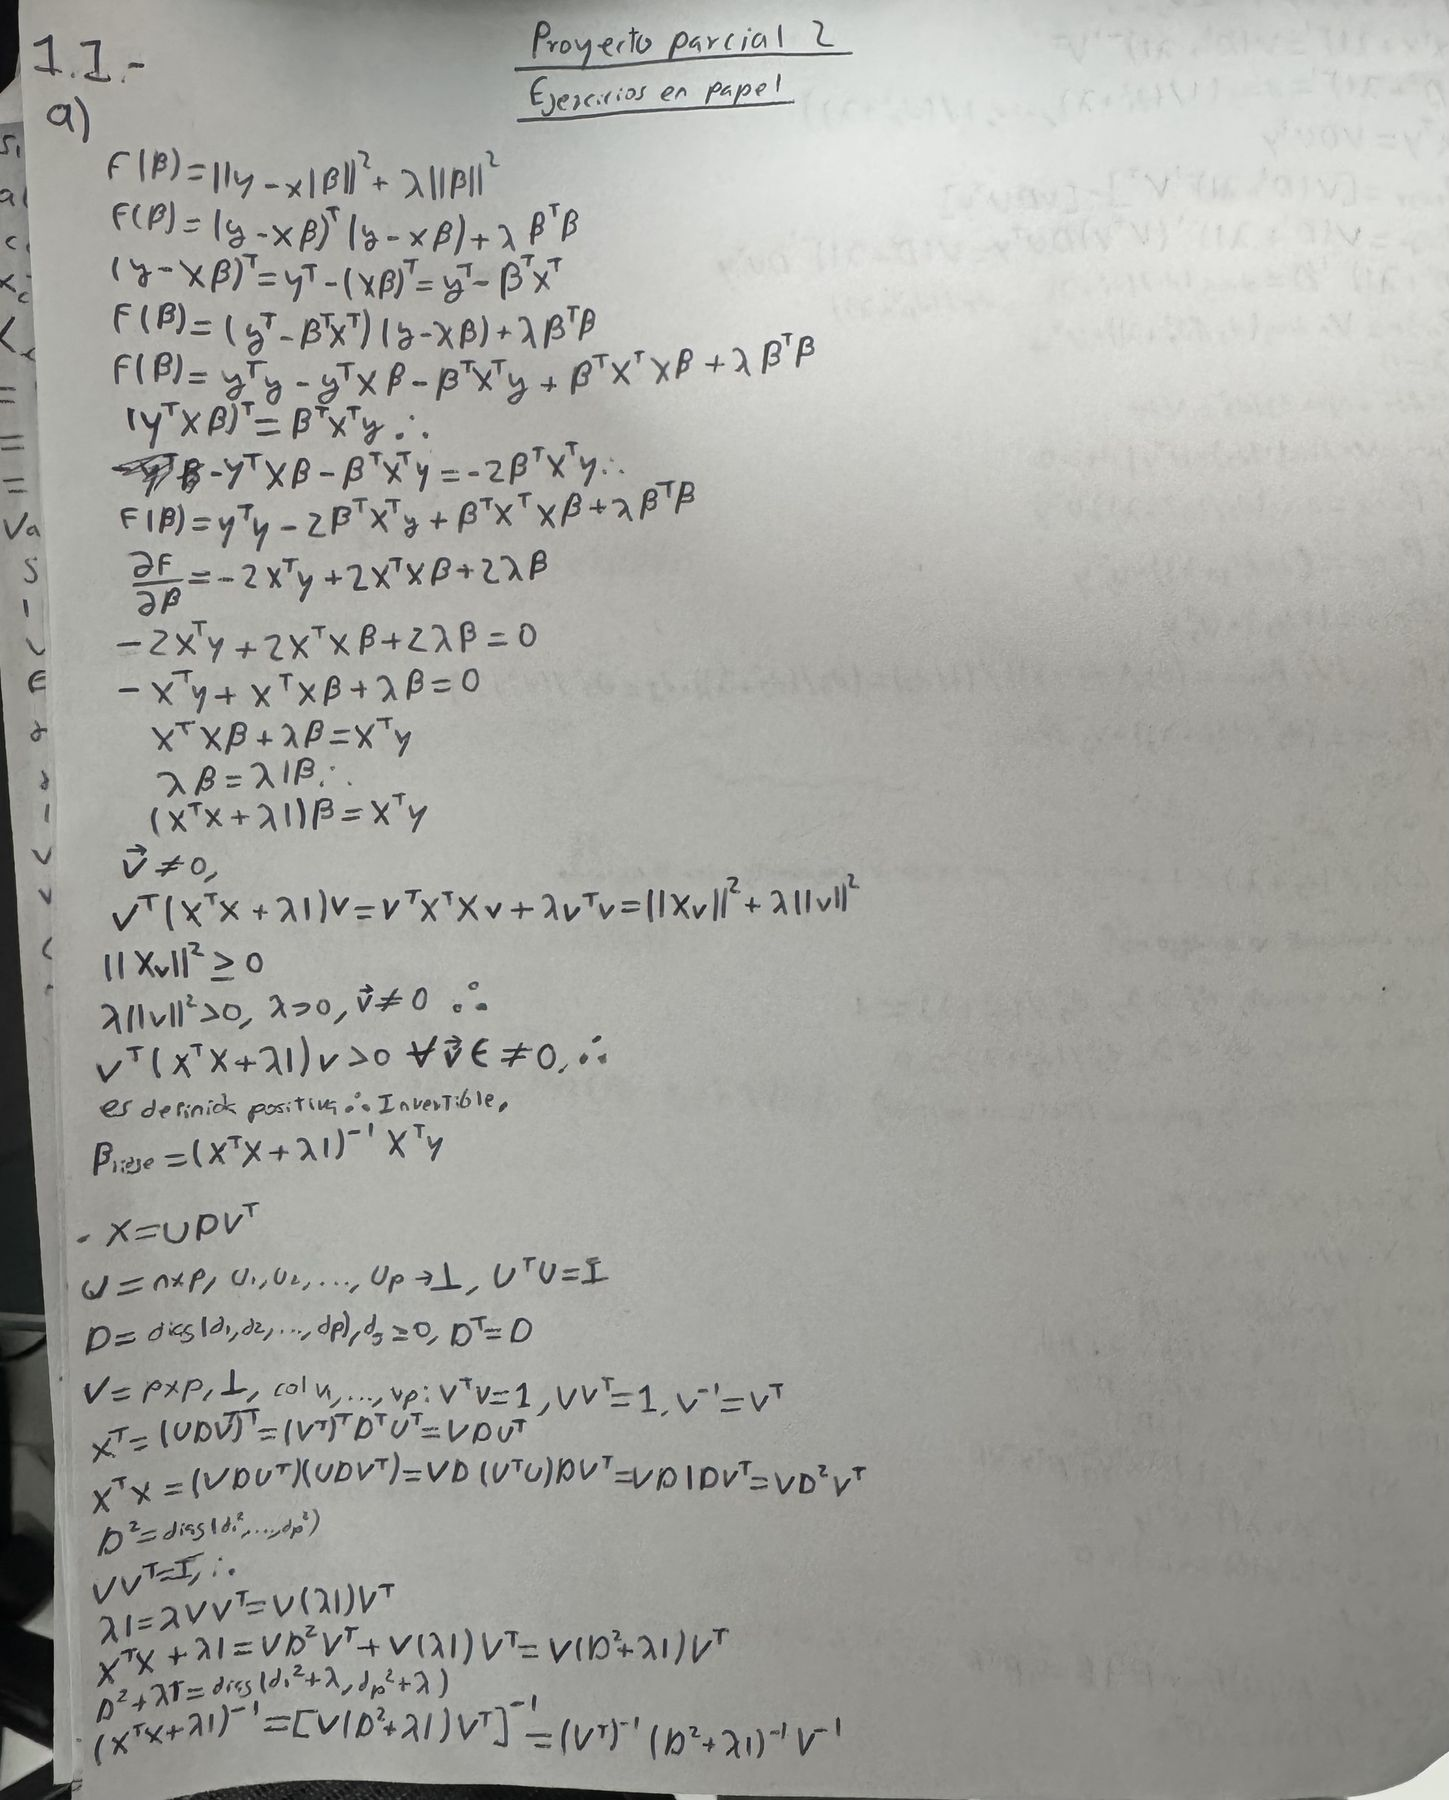

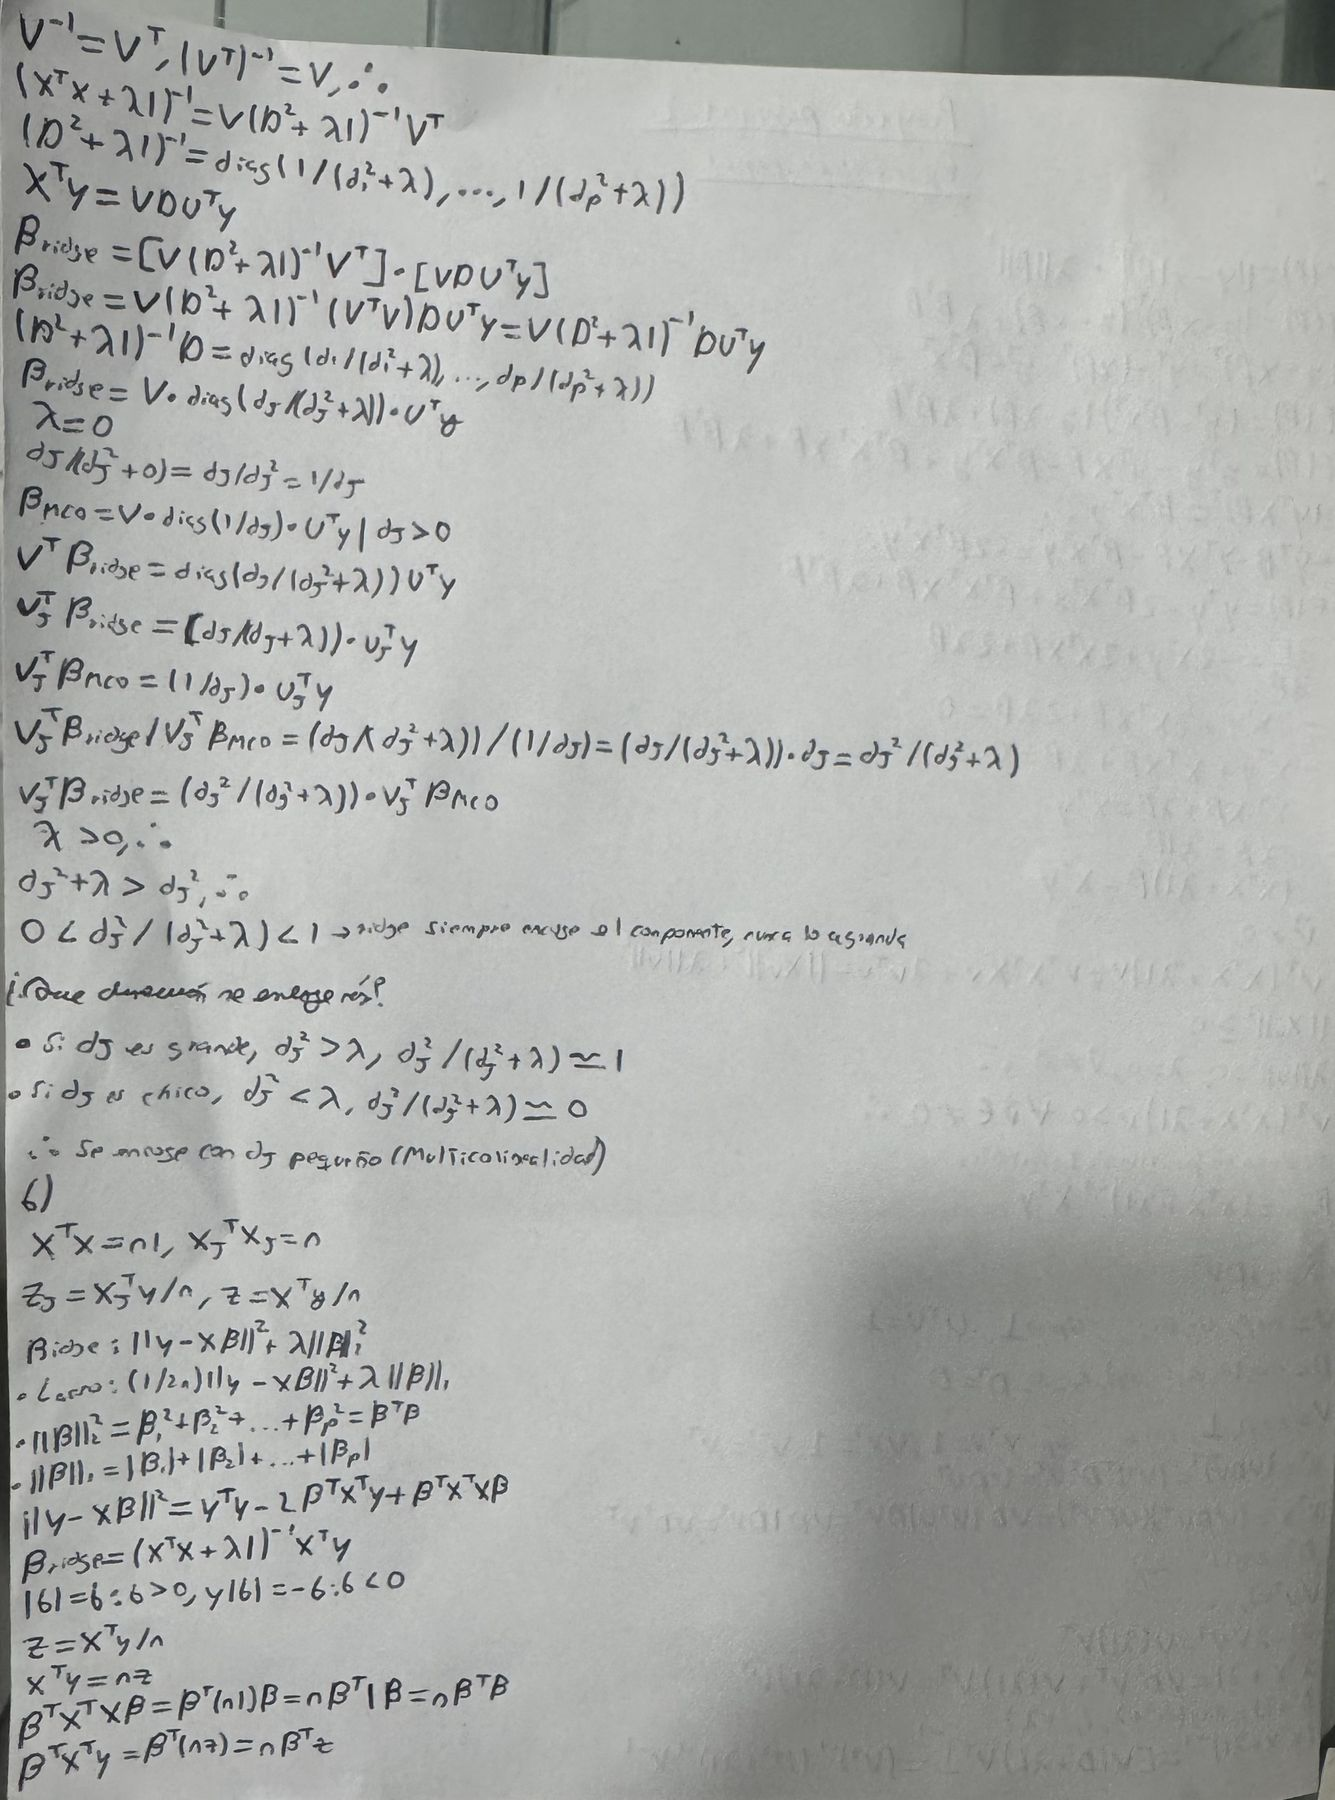

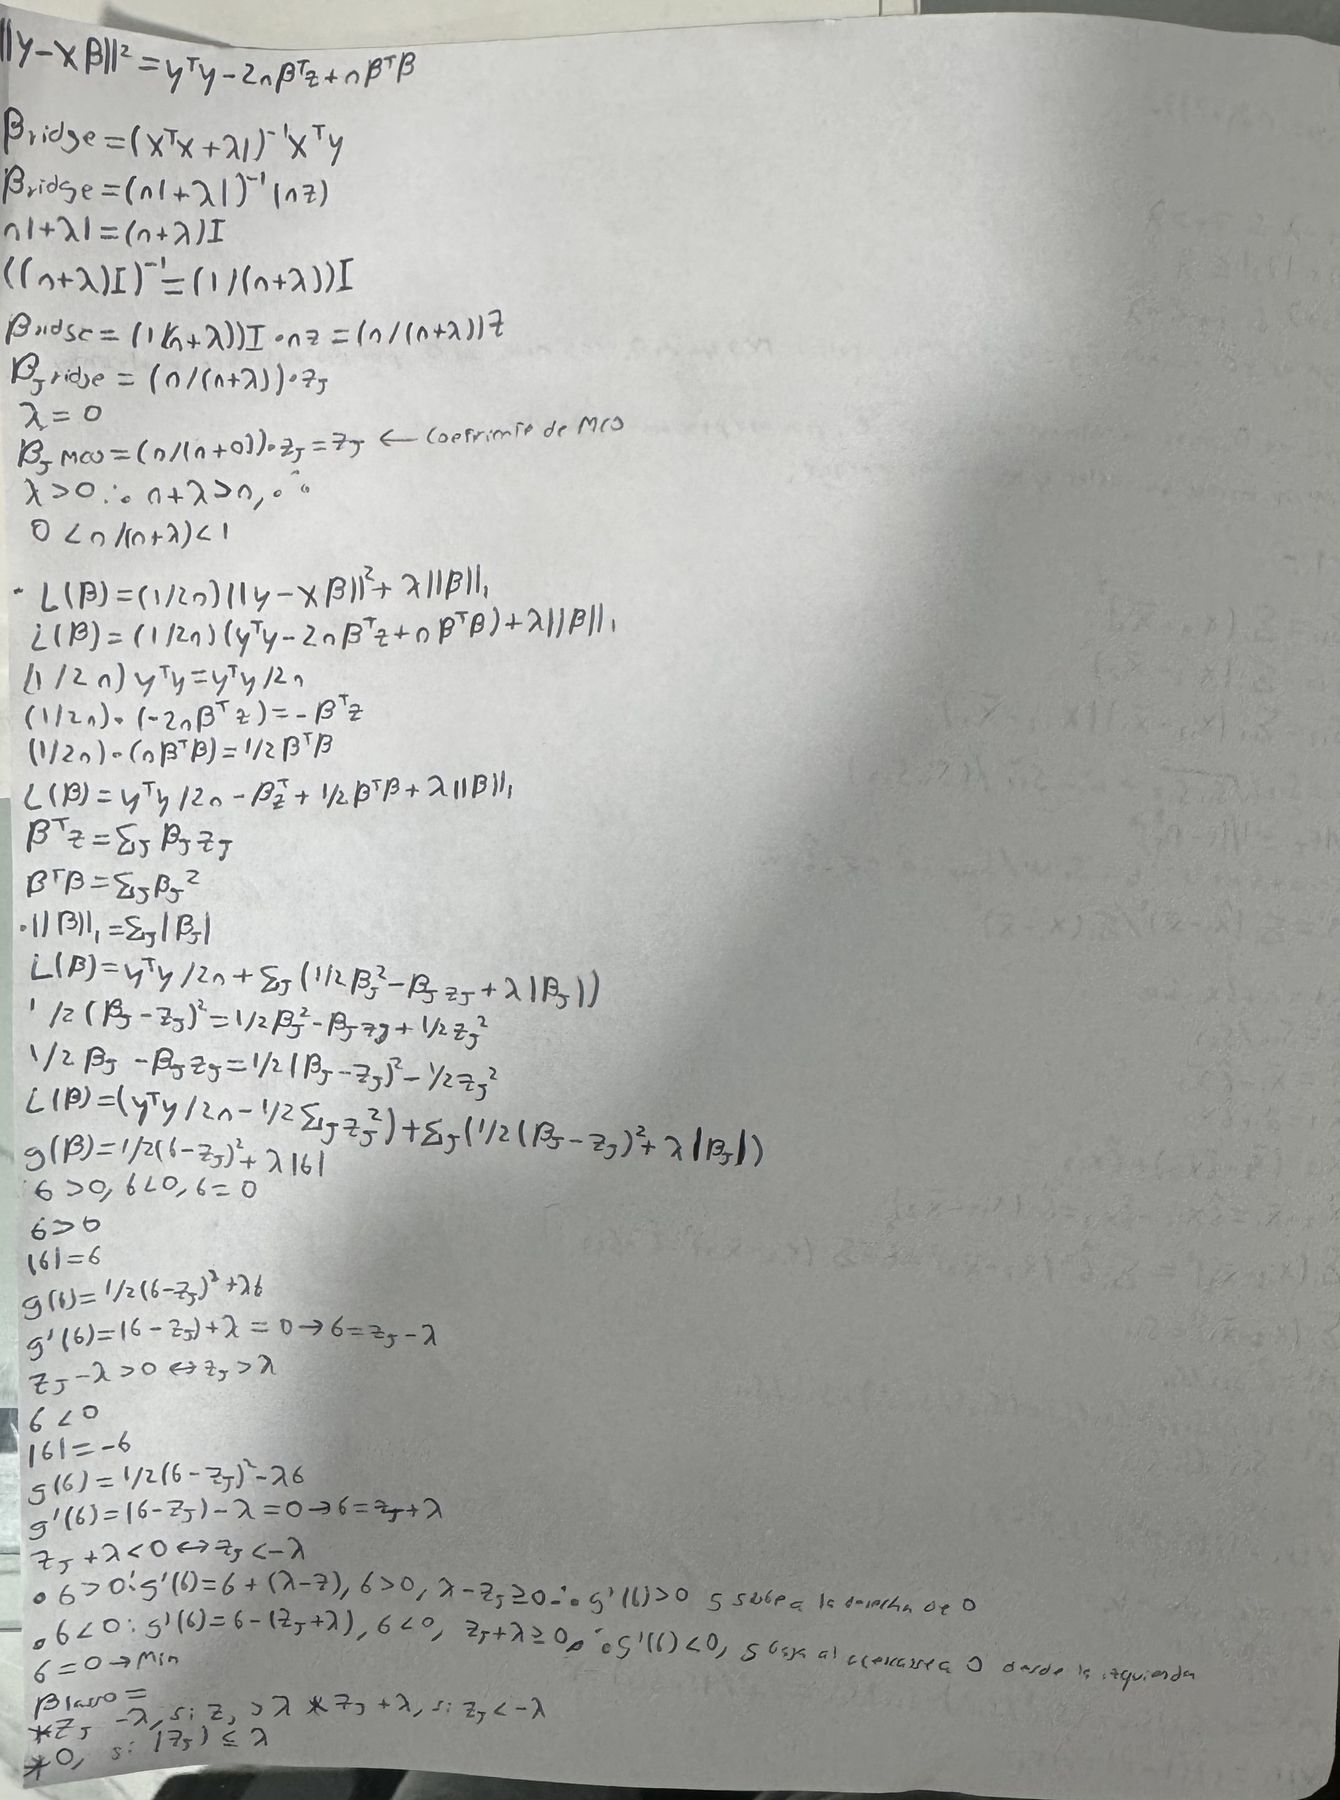

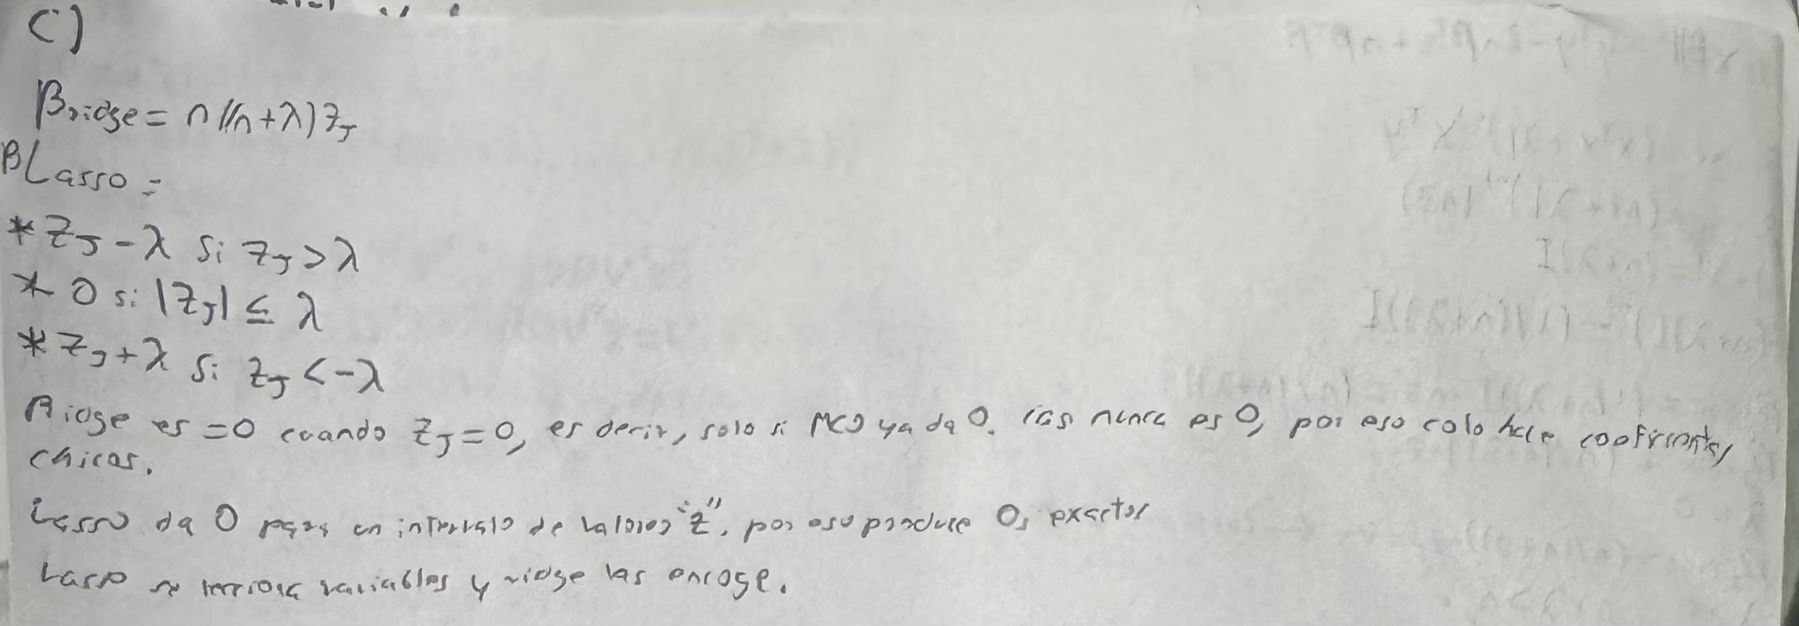

## Ejercicio 2.1

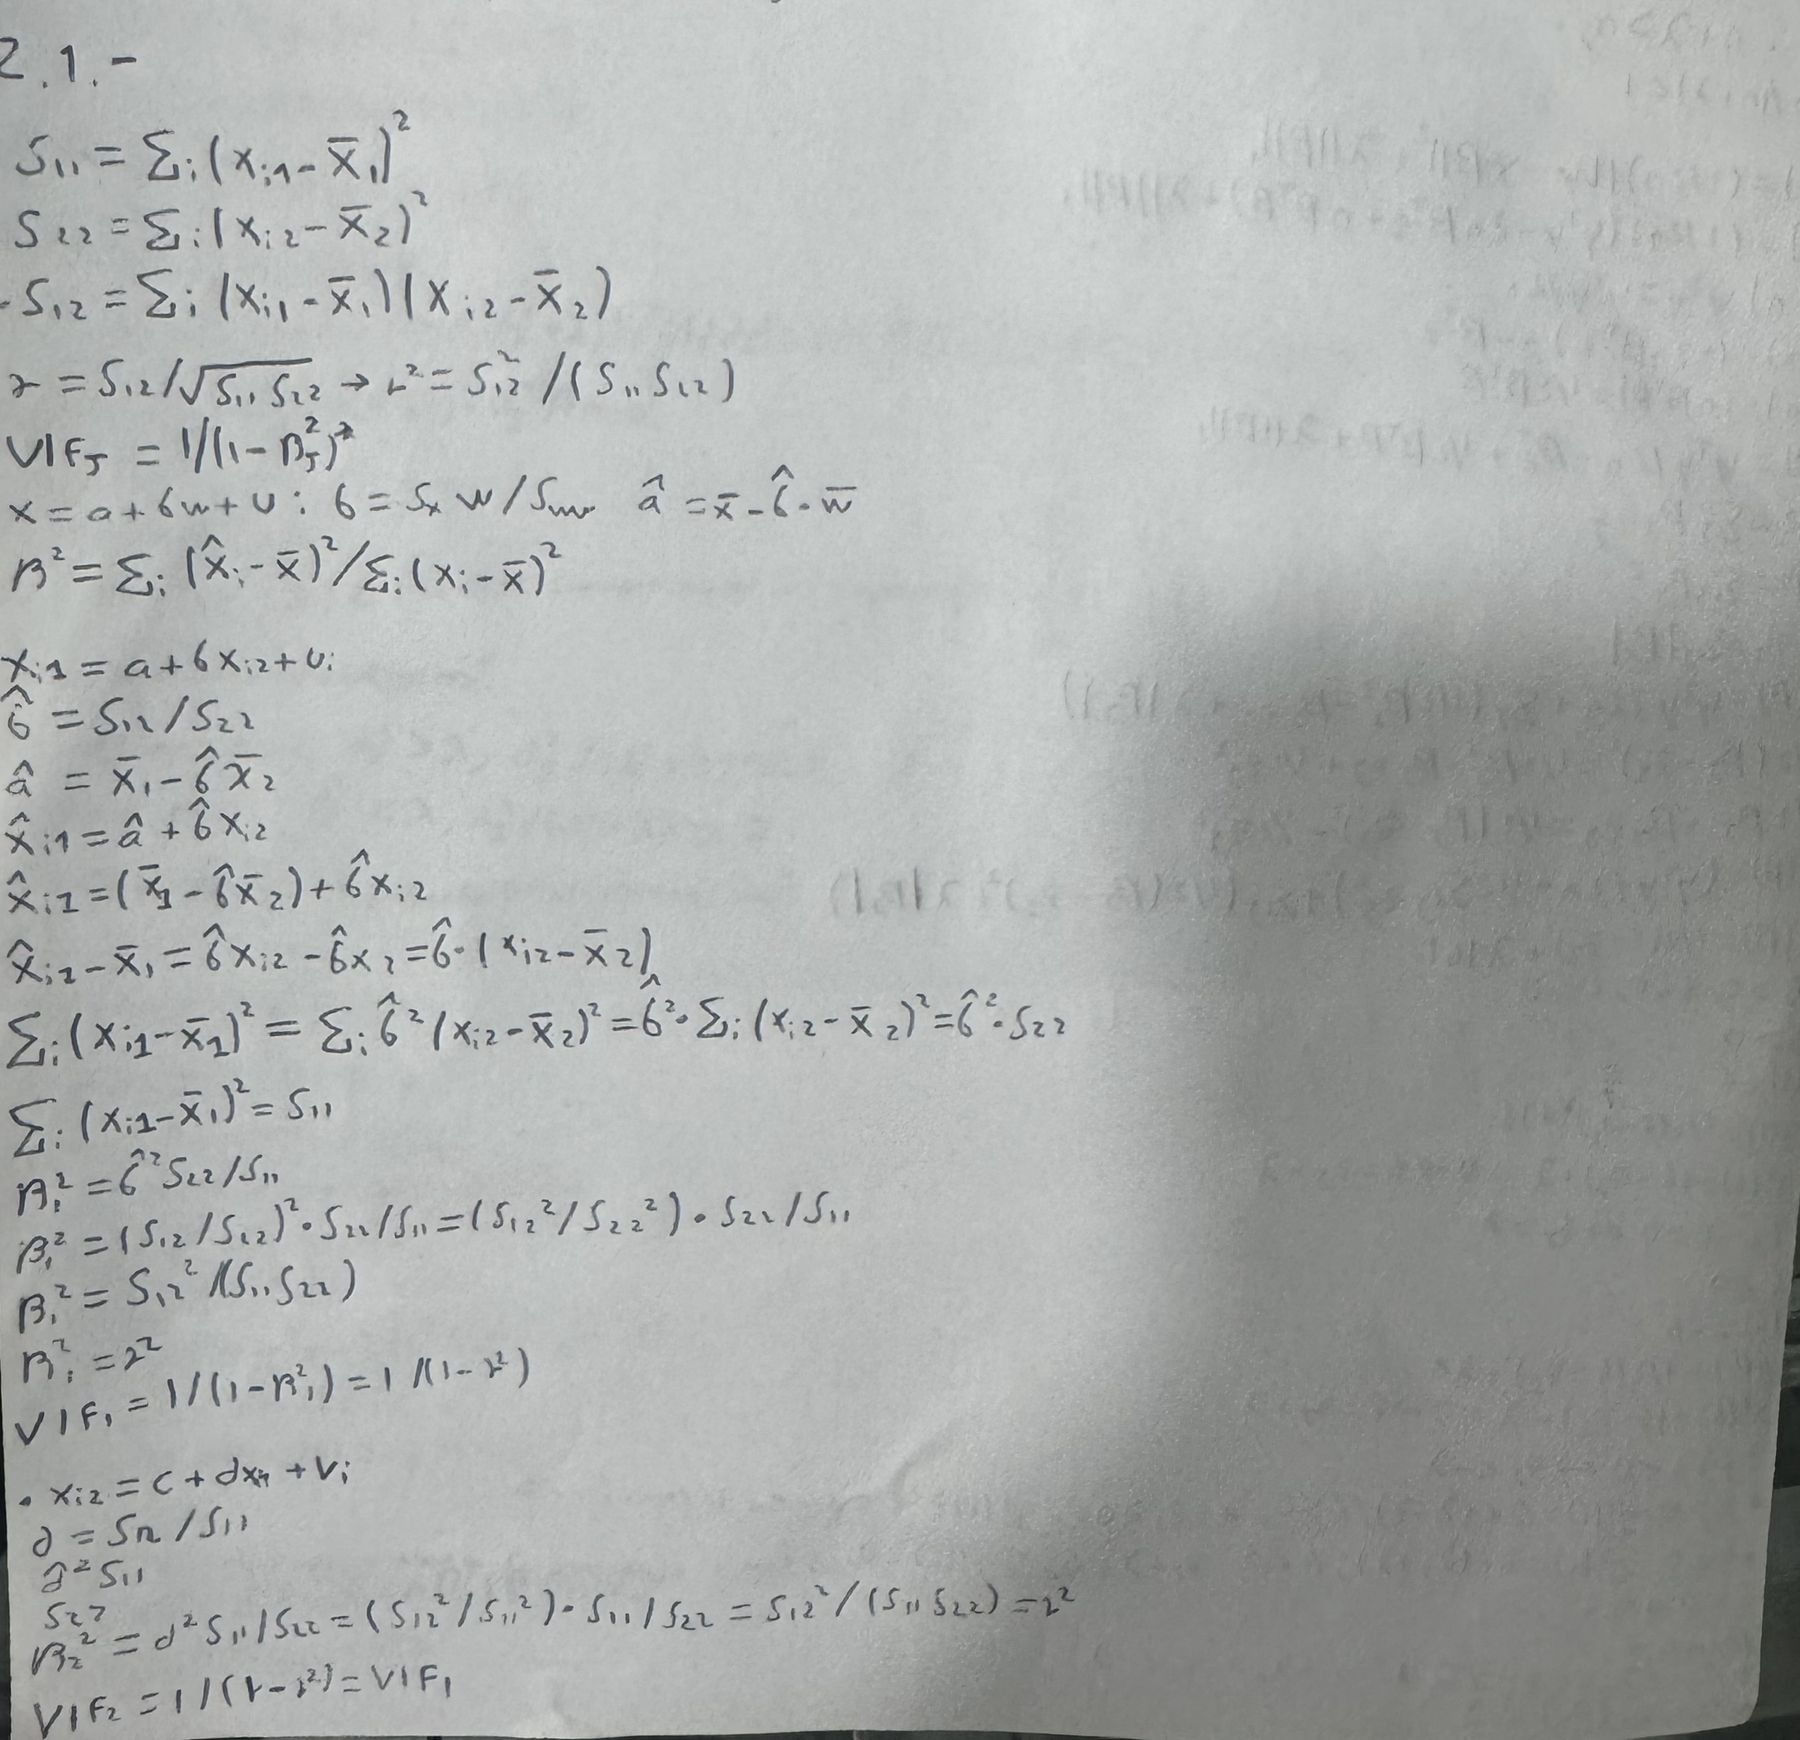

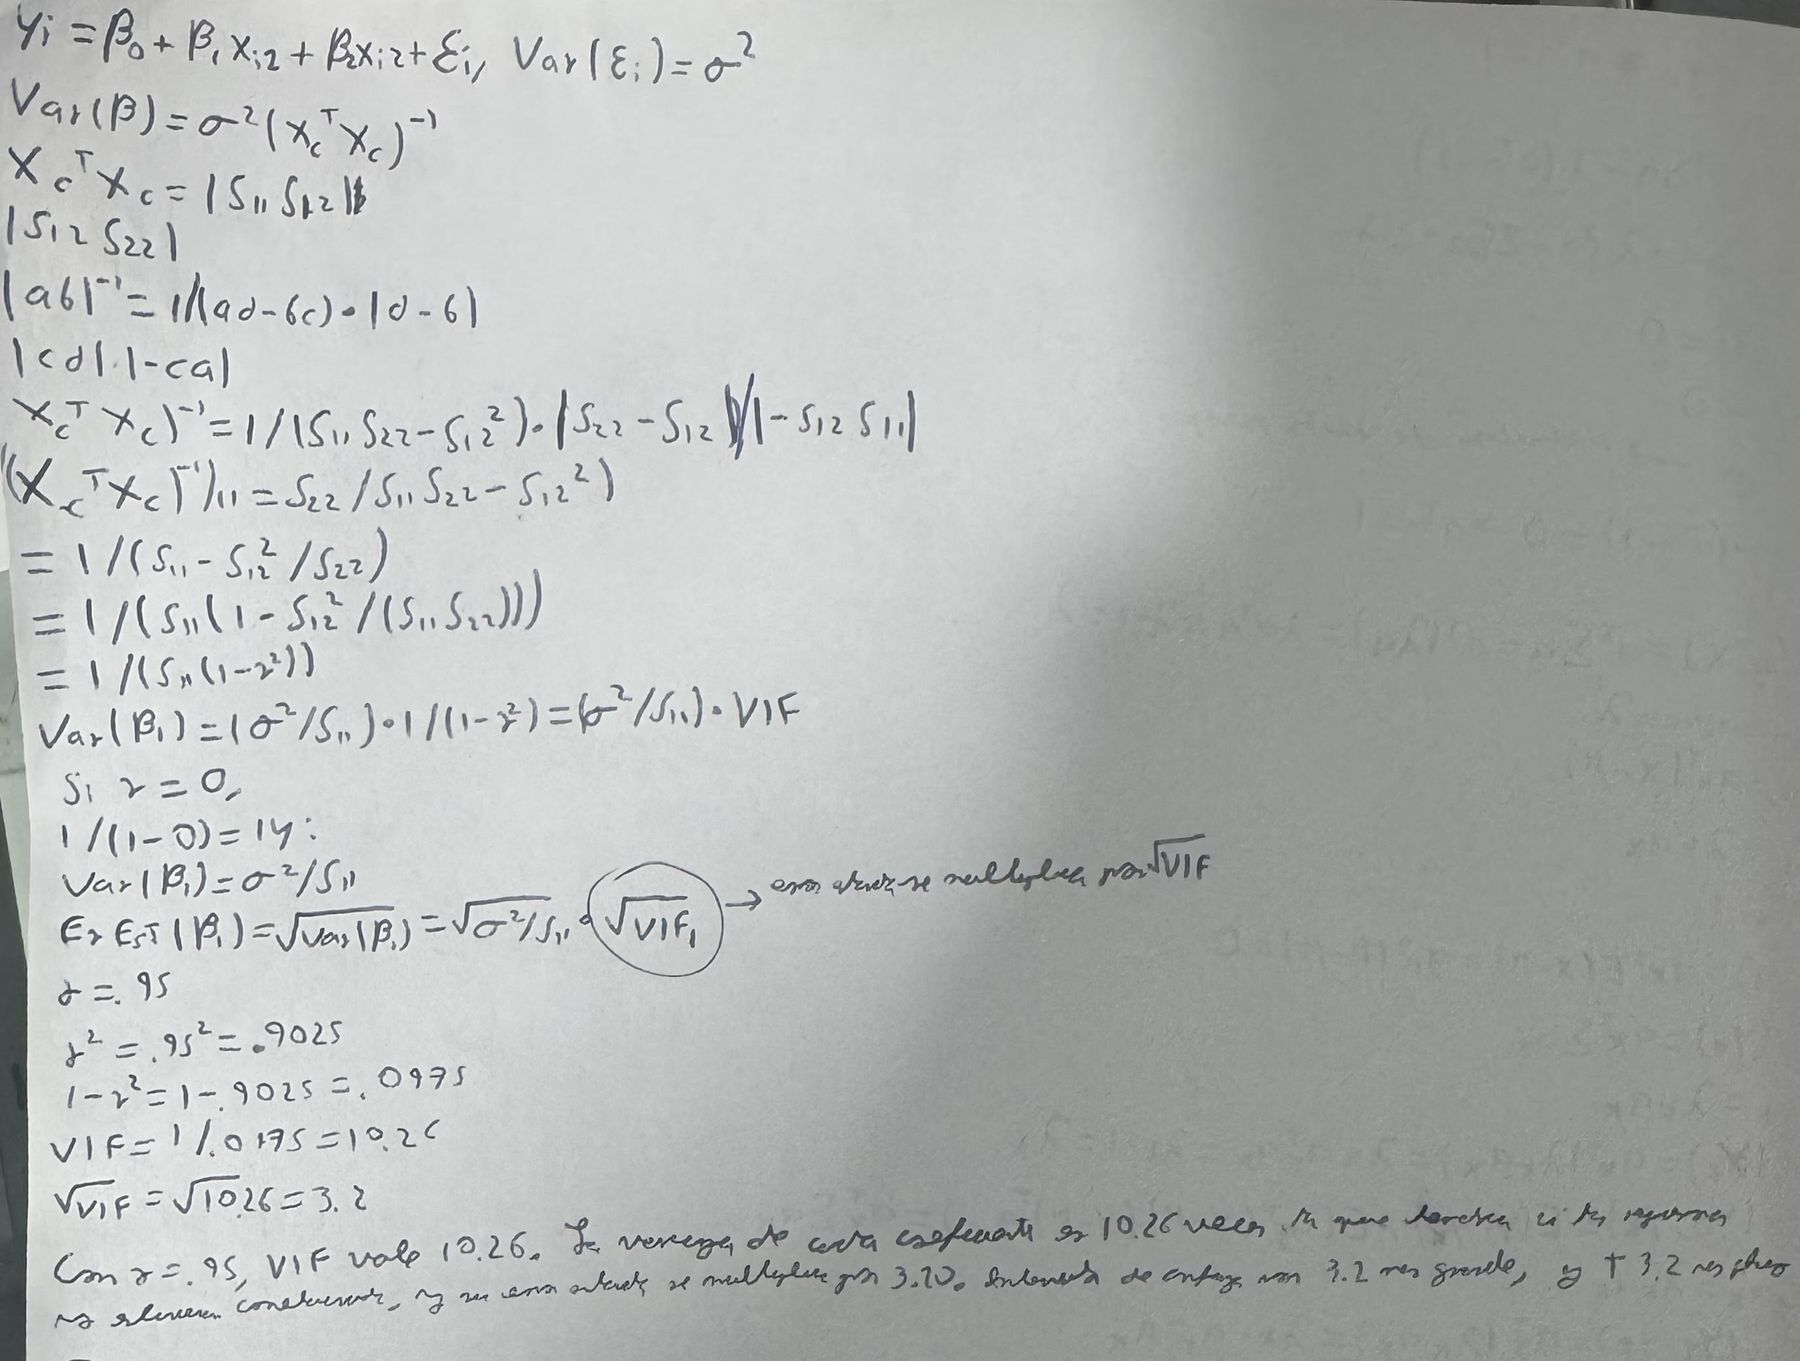

## Ejercicio 3.1

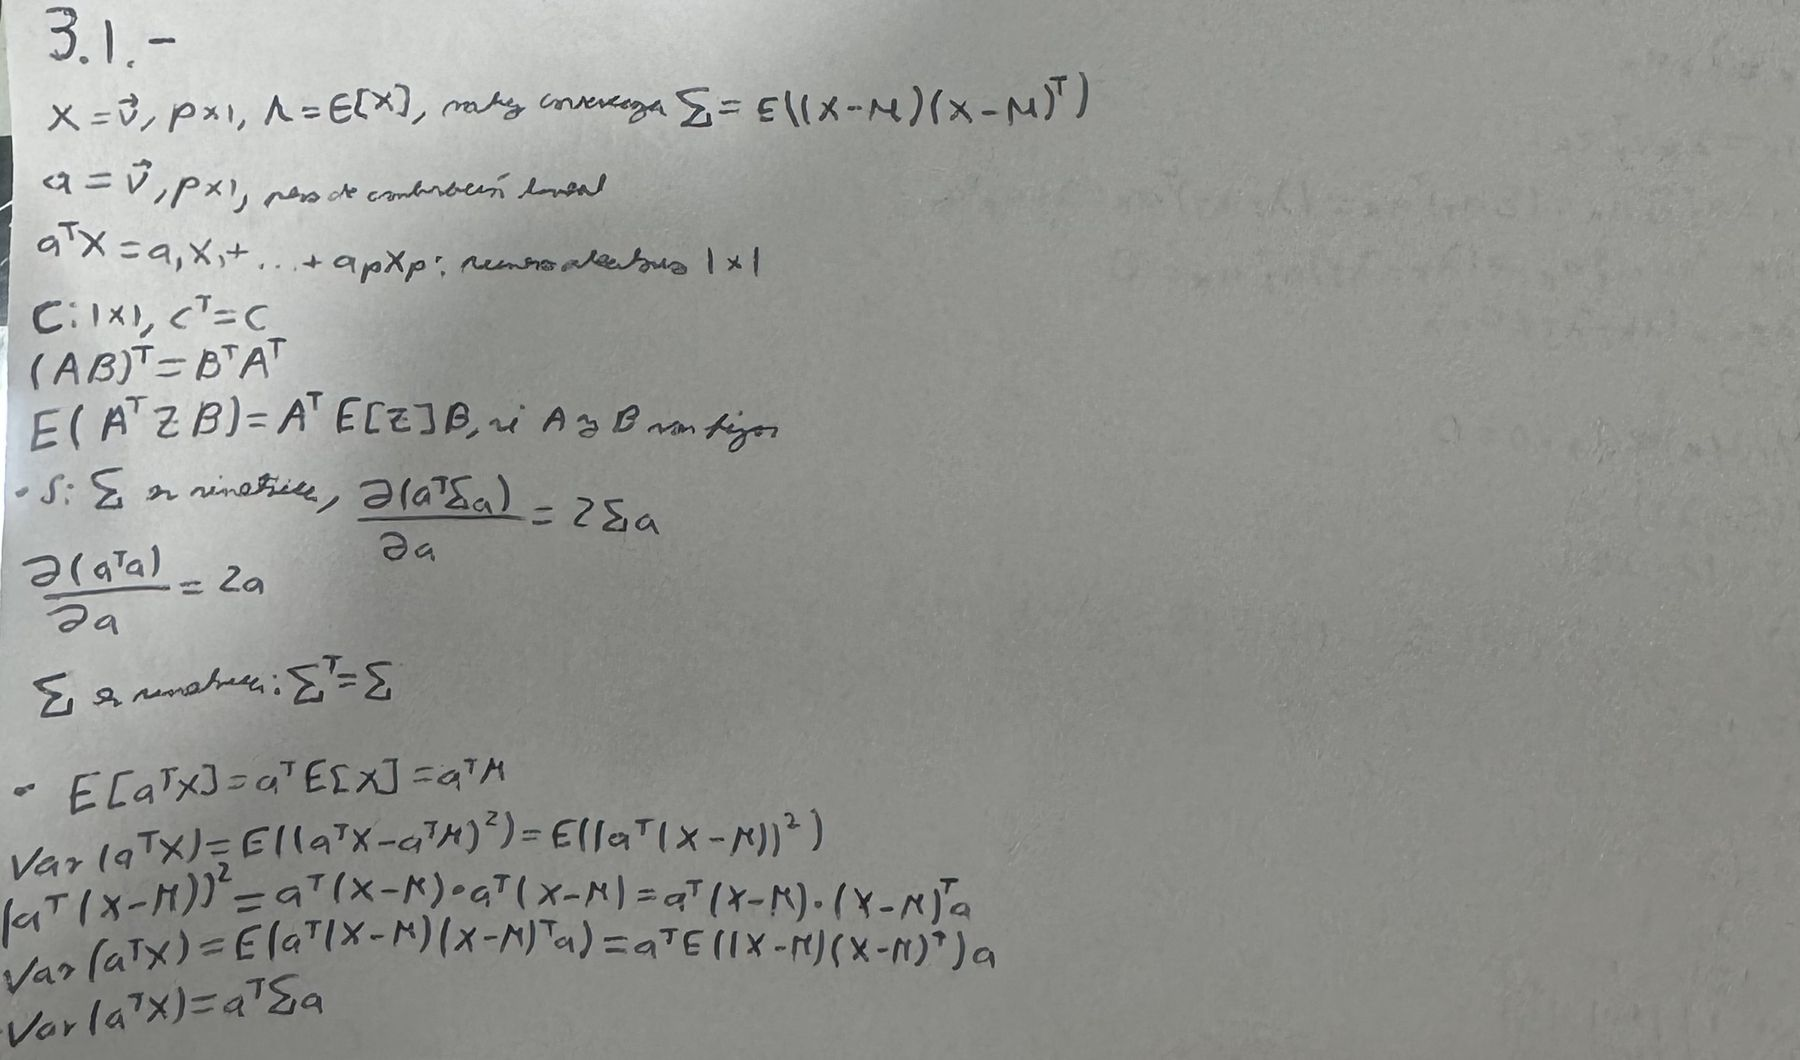

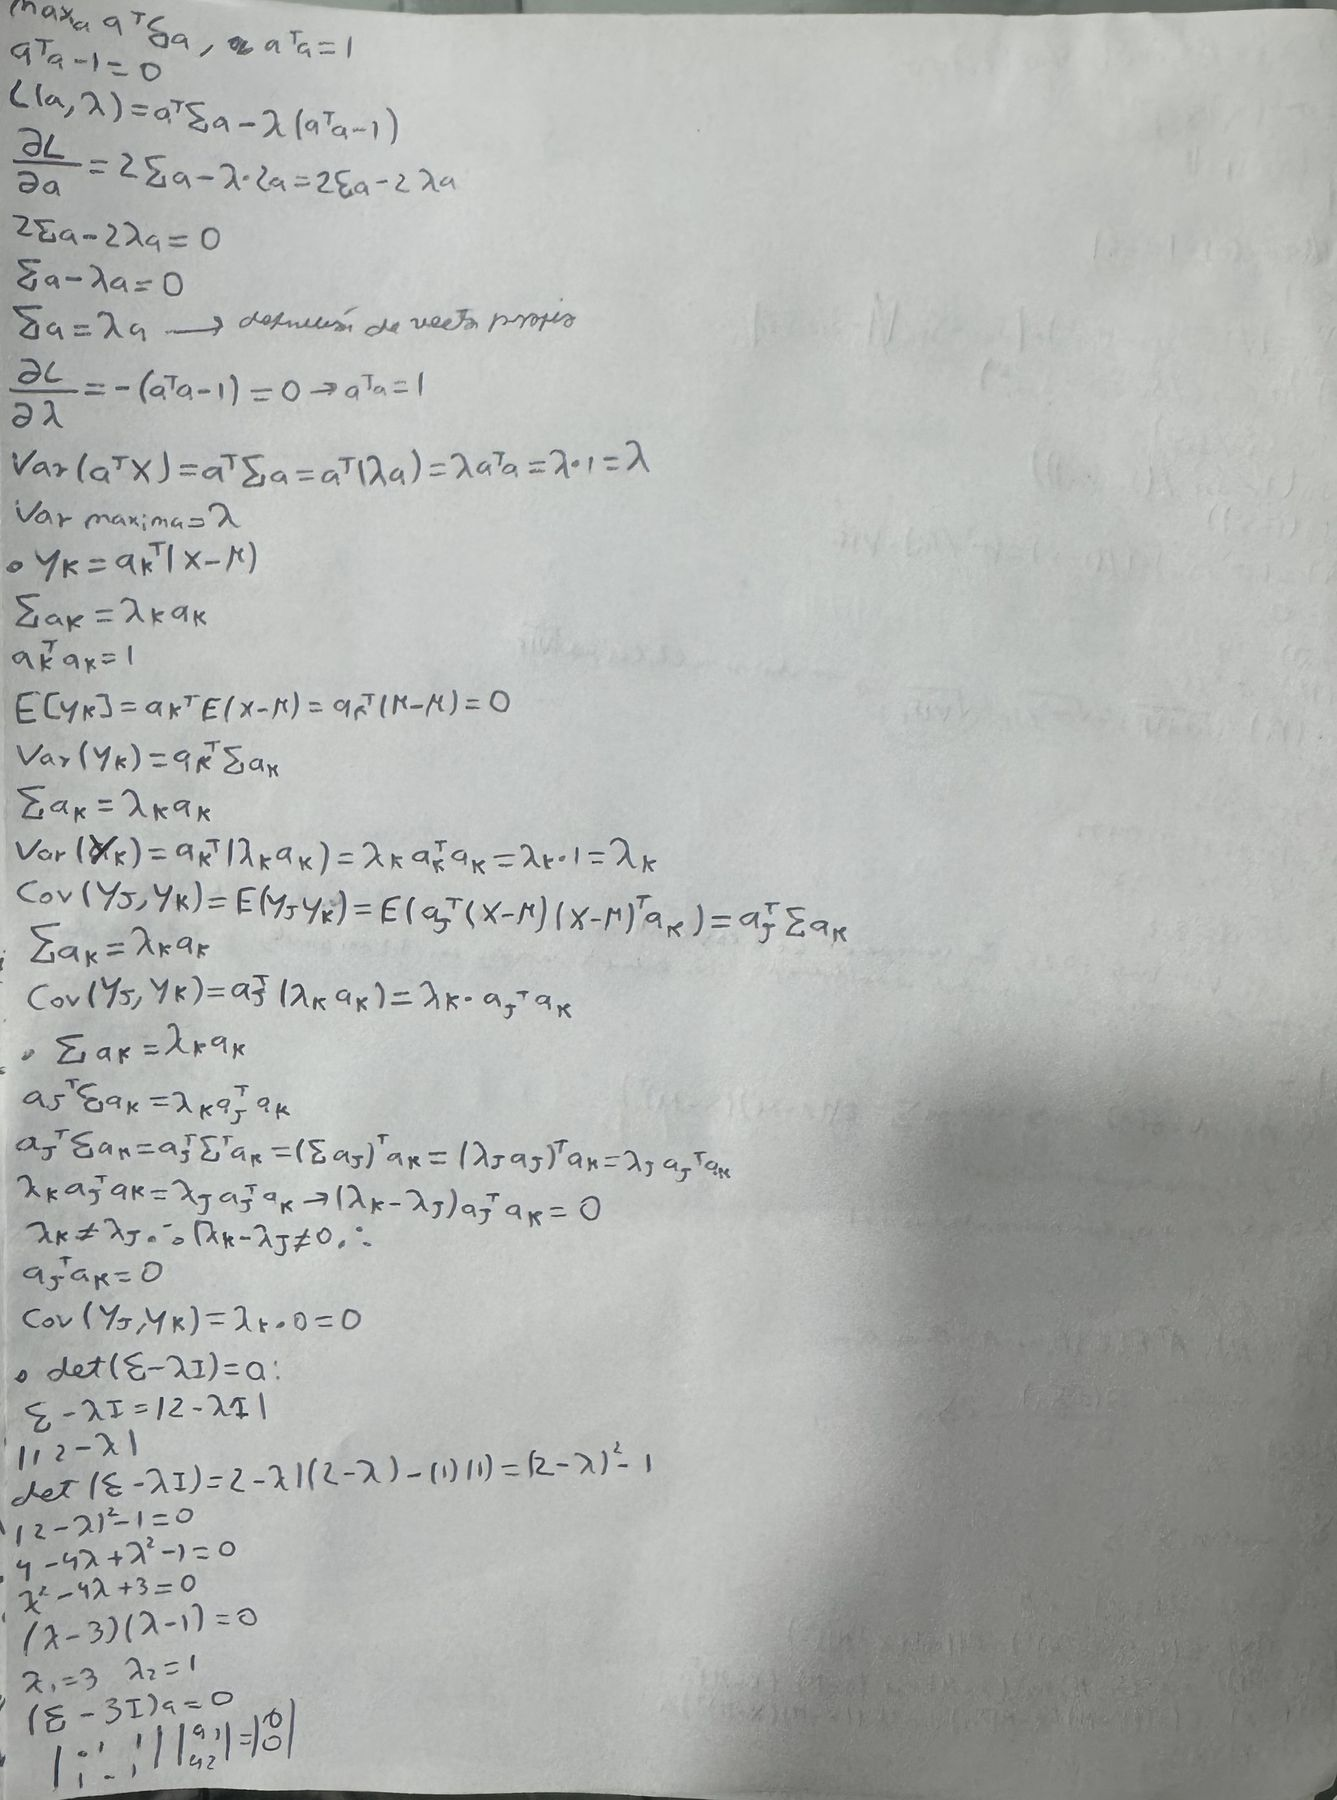

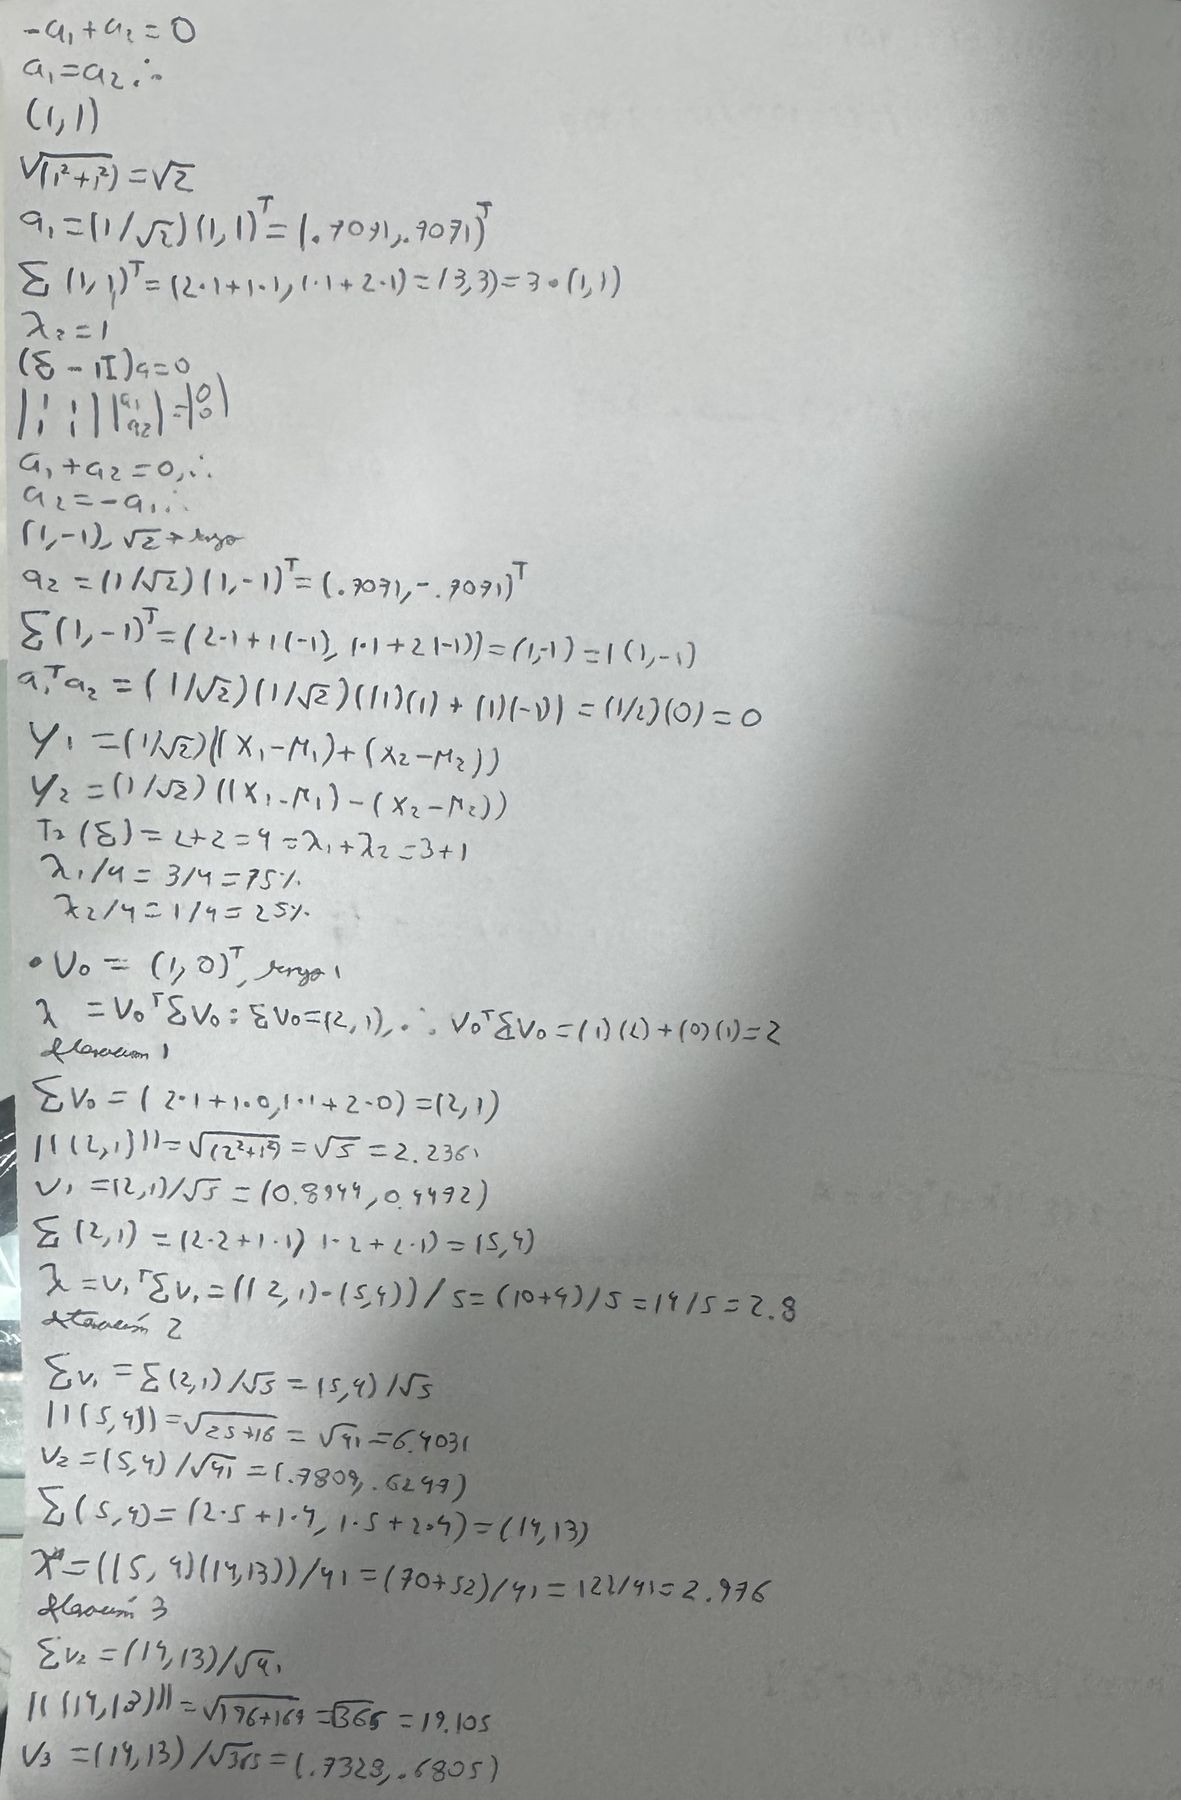

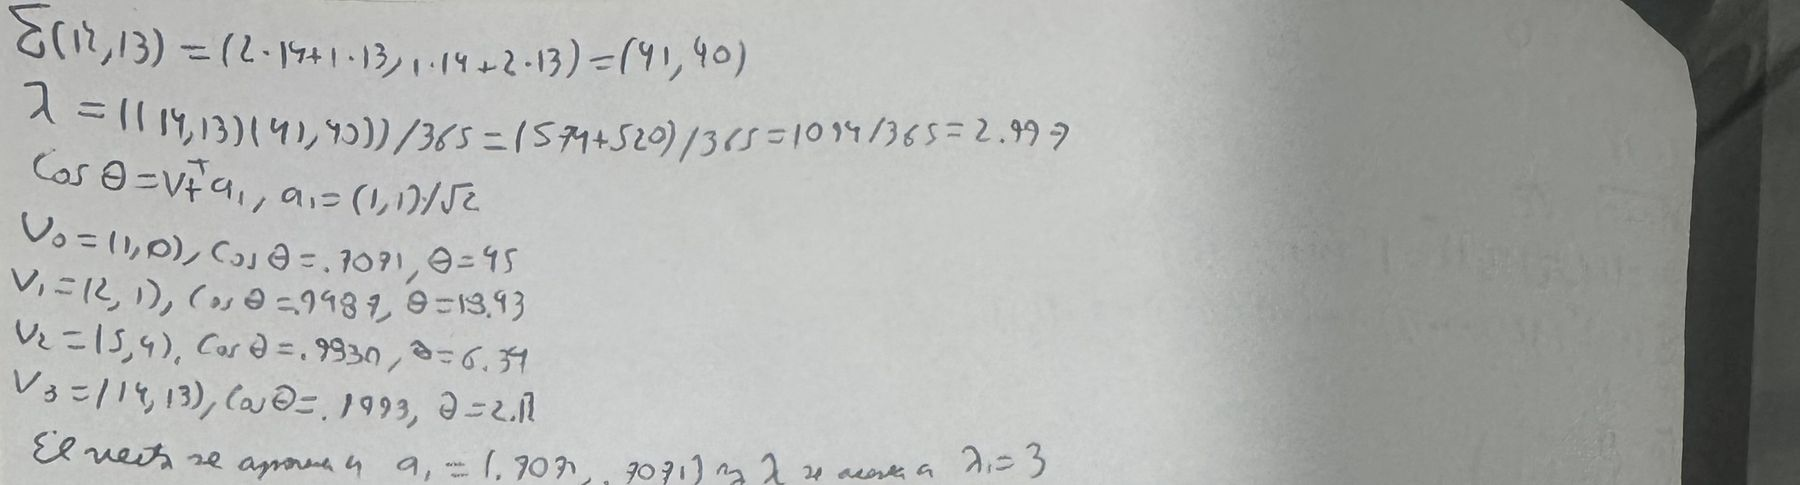

## Ejercicio 4.1

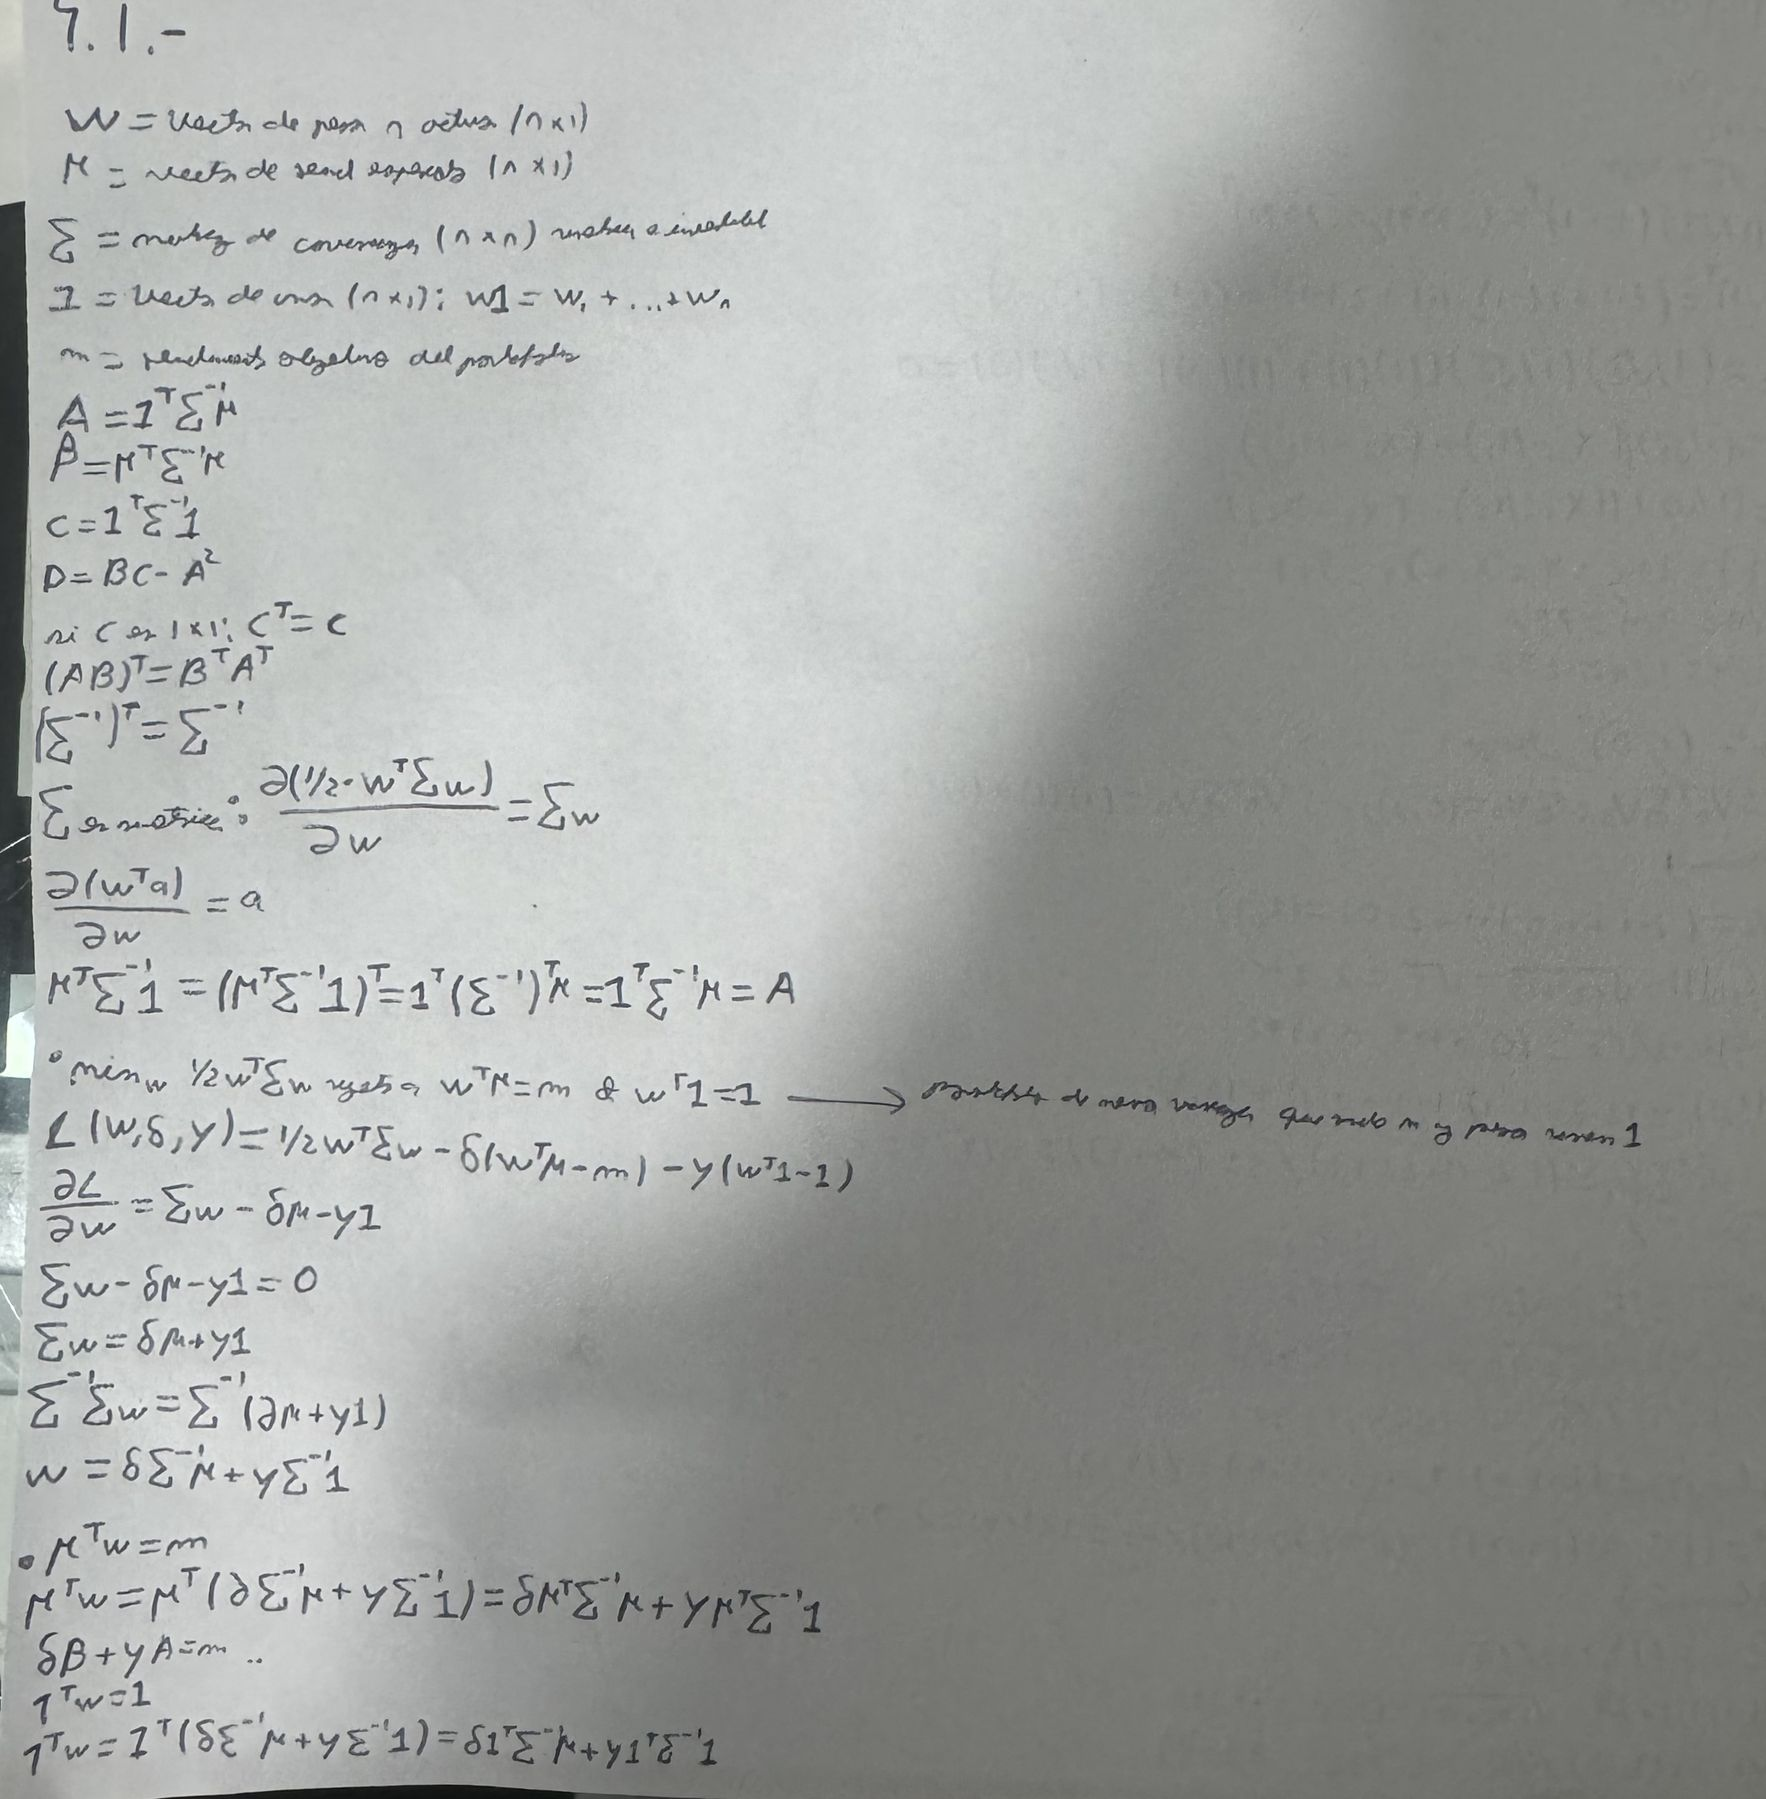

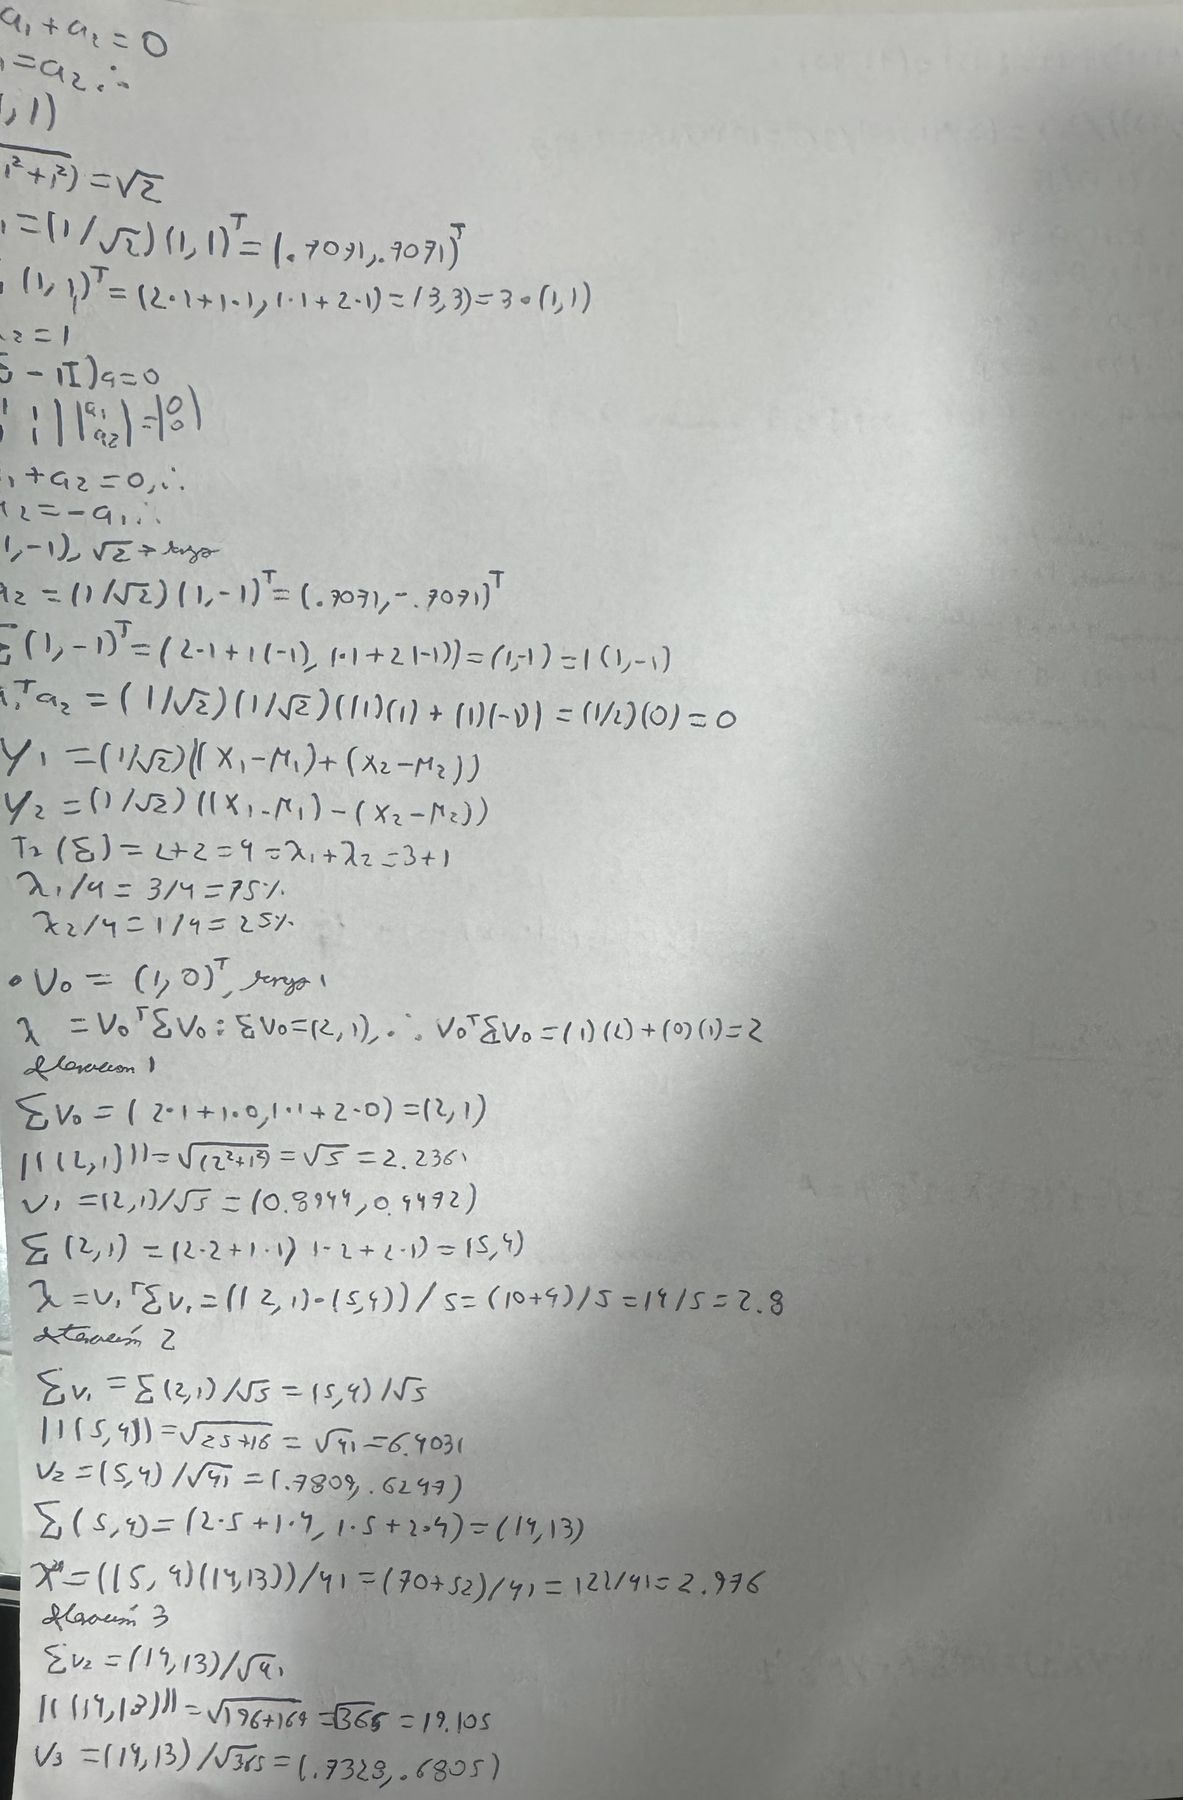

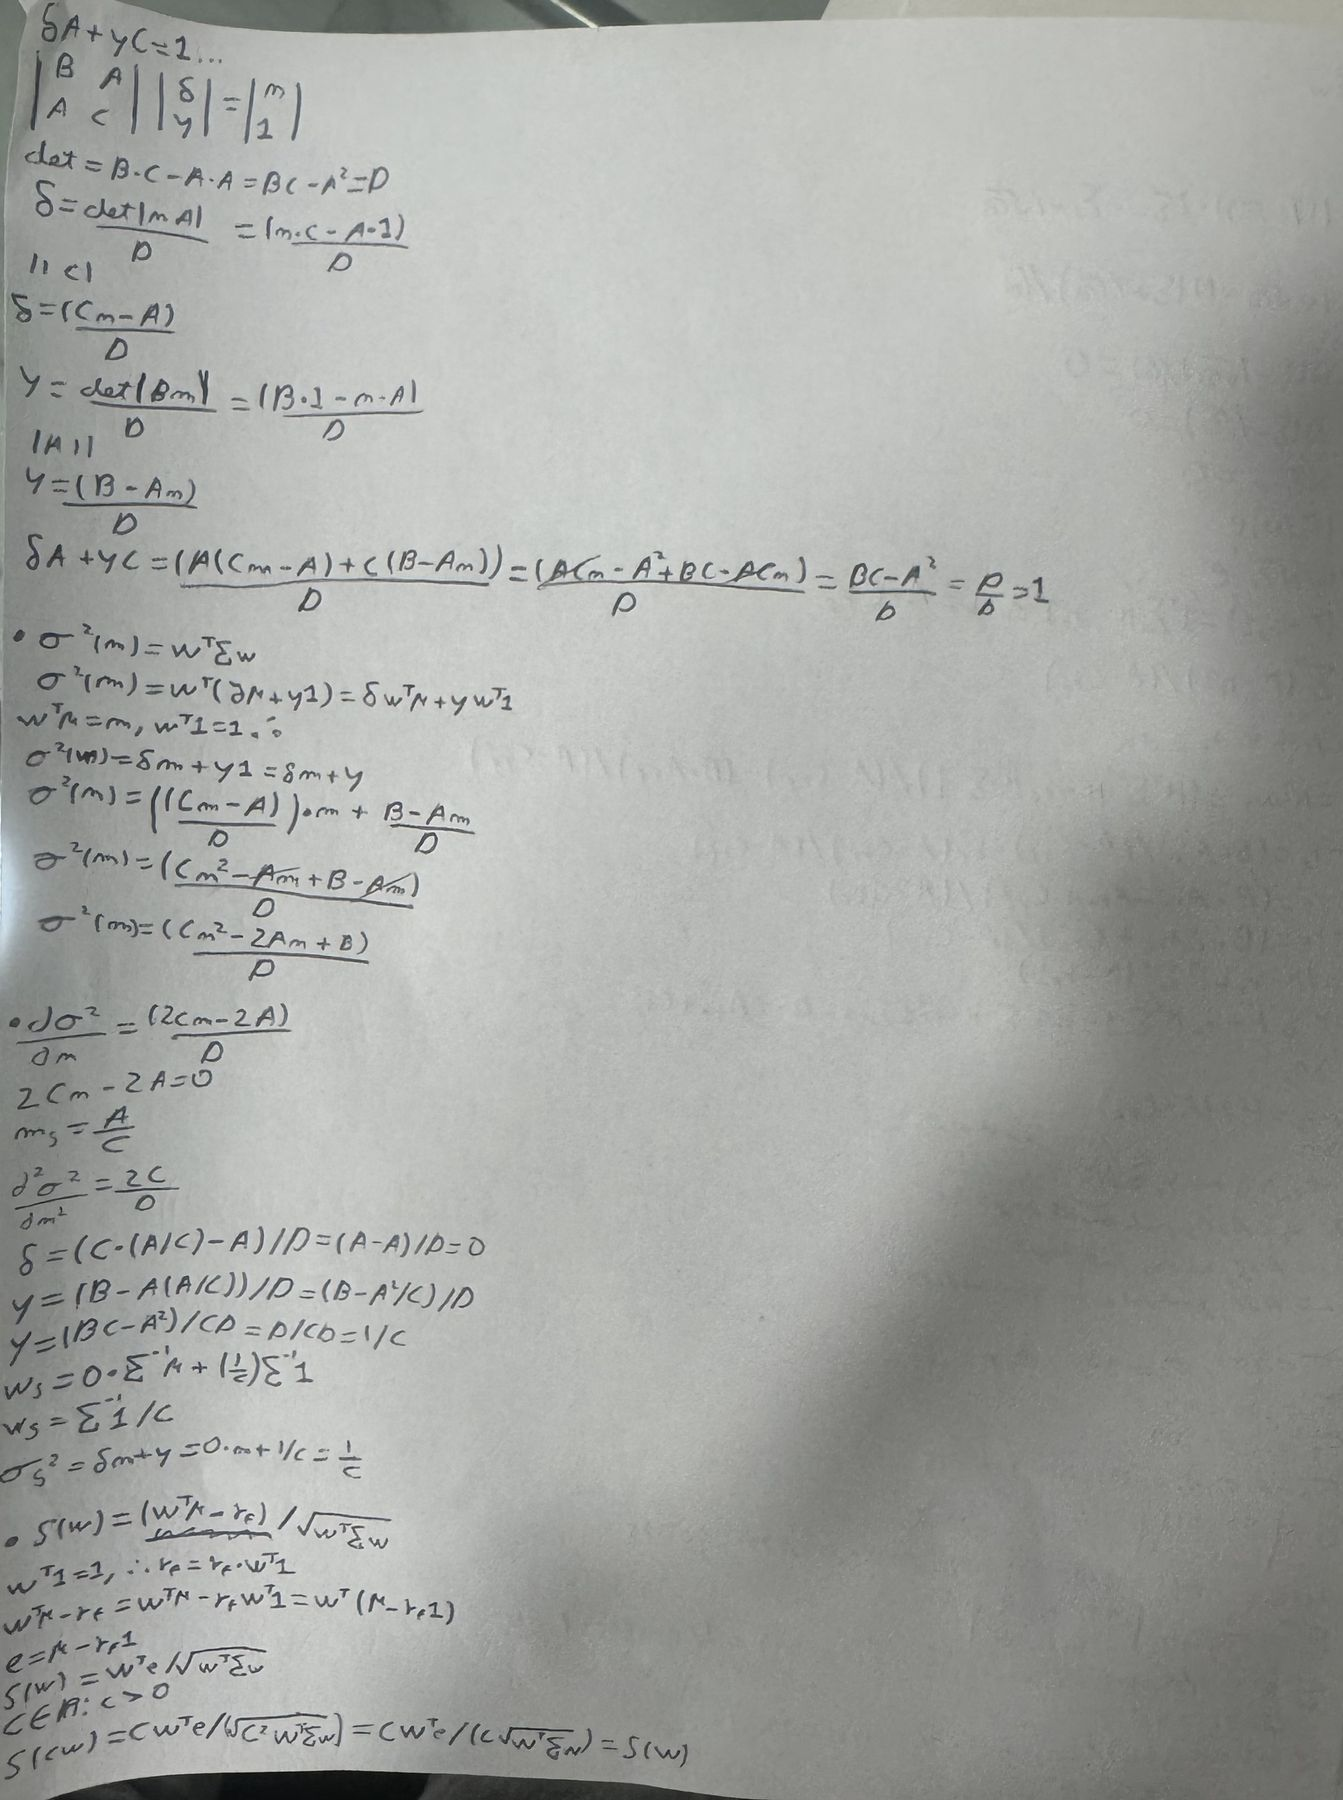

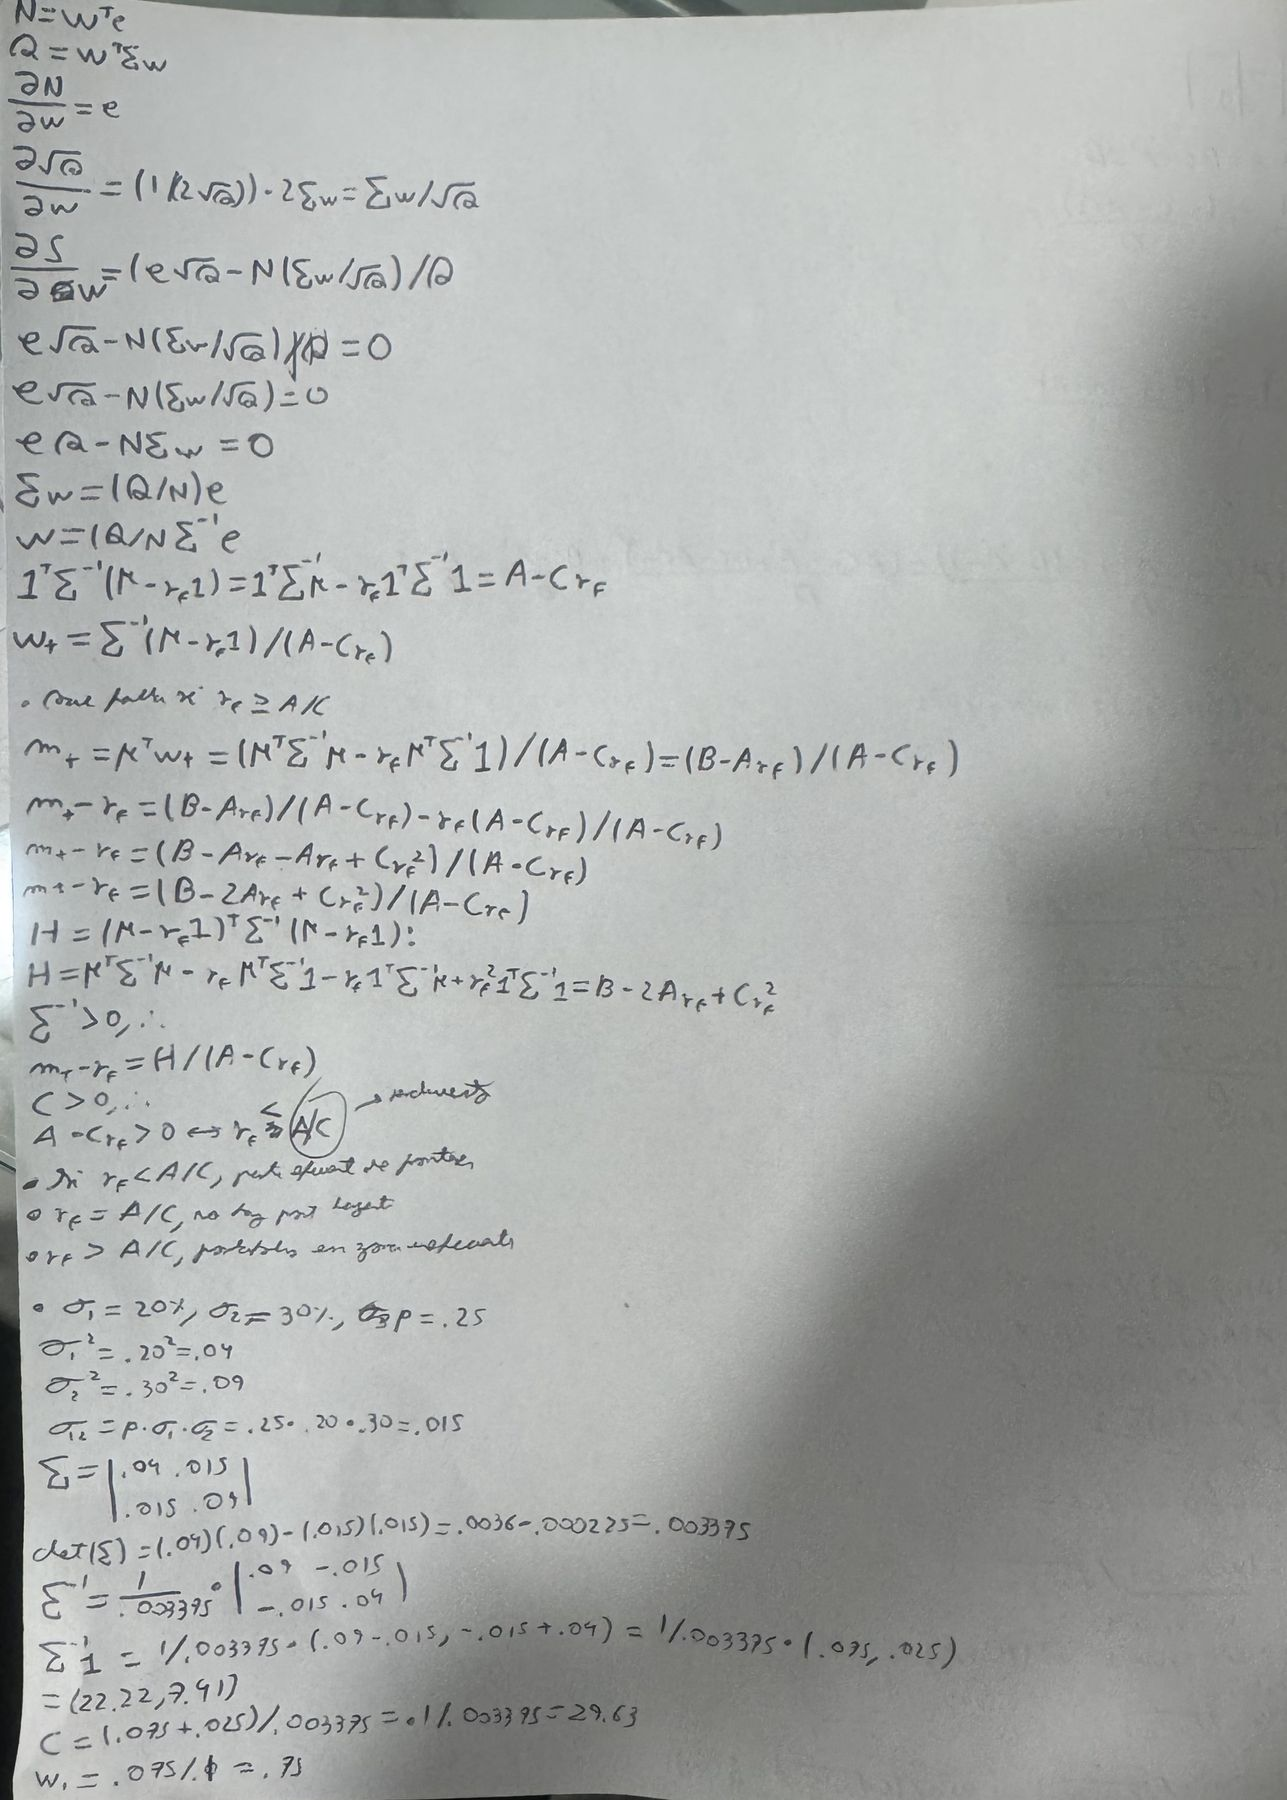

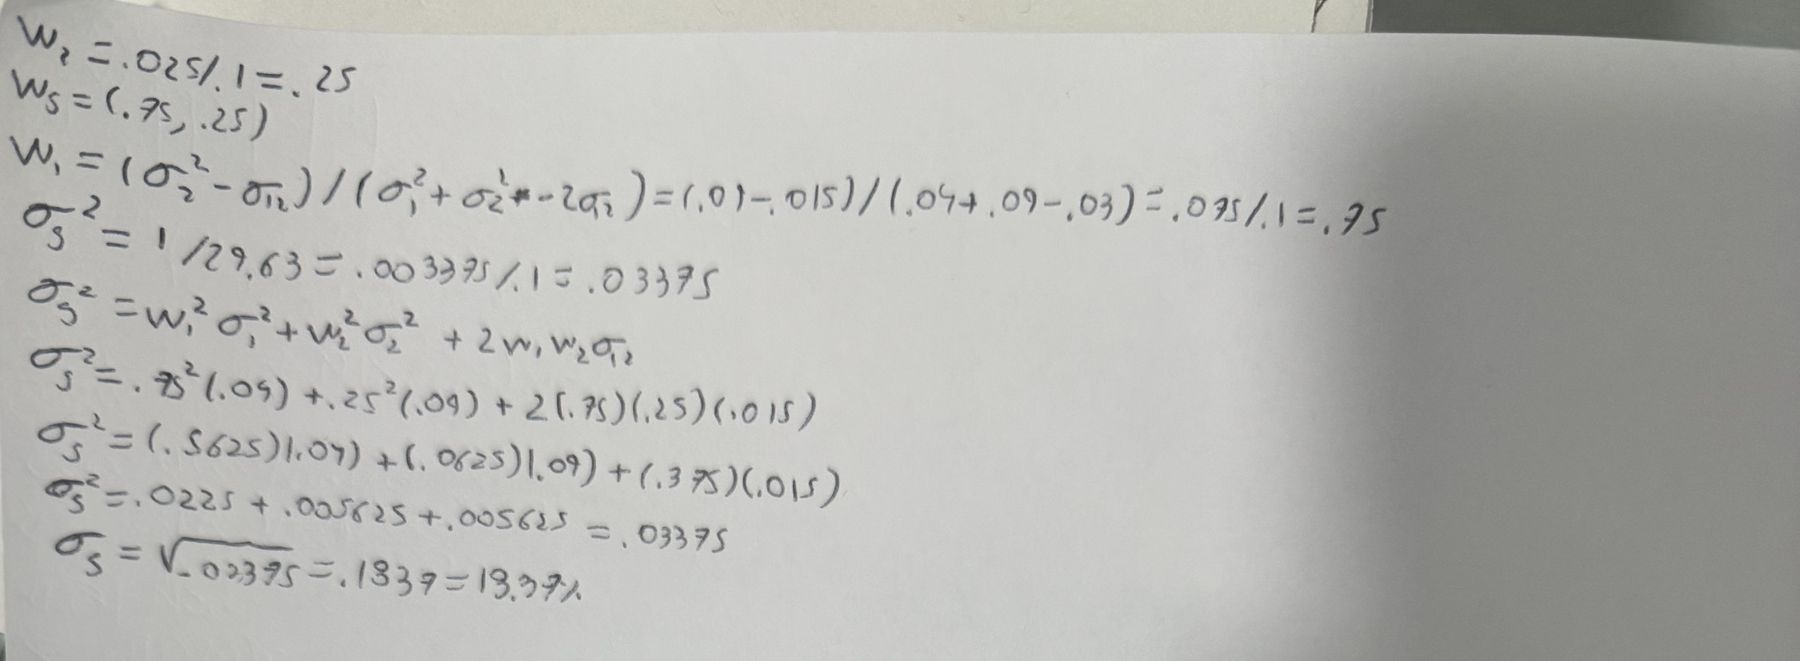

# Parte 5. Dashboard

Sube tus resultados a un dashboard interactivo. Sigue los pasos de `INSTRUCCIONES.md`. **Presentarás este dashboard oralmente, en vivo, ante profesores.** Elige **una** opción:

- **Opción A: Streamlit** (`dashboard/app.py`). Calcula en vivo.
- **Opción B: página HTML** (`dashboard/generar_html.py`). Se publica gratis en GitHub Pages.

Esta celda guarda tus resultados, para que el dashboard pueda mostrarlos sin volver a correr el Monte Carlo.

**Qué vamos a hacer y por qué.** Guardamos las tablas principales (MANOVA, Monte Carlo, remedios y desempeño de las estrategias de Markowitz) en la carpeta `dashboard/resultados`. Así el dashboard puede mostrarlas sin repetir los cálculos más lentos.

In [32]:
carpeta = Path("dashboard/resultados")
carpeta.mkdir(parents=True, exist_ok=True)
tabla_manova.reset_index().to_csv(carpeta / "tabla_manova.csv", index=False)
tabla_rmse.reset_index().to_csv(carpeta / "montecarlo_rmse.csv", index=False)
tabla_beta.reset_index().to_csv(carpeta / "montecarlo_beta.csv", index=False)
tabla_remedios.to_csv(carpeta / "remedios.csv")
tabla_prueba.to_csv(carpeta / "markowitz_prueba.csv")
tabla_movil.to_csv(carpeta / "markowitz_movil.csv")
pd.Series({"SEMILLA": SEMILLA, "EQUIPO": EQUIPO, "OBJETIVO": OBJETIVO, "ACTIVOS": ",".join(ACTIVOS)}).to_json(carpeta / "equipo.json")
print("Resultados guardados en", carpeta.resolve())

Resultados guardados en /content/dashboard/resultados


# Parte 6. Memorándum final

✍️ En **máximo 250 palabras**, dirigidas al comité de inversión de un fondo, responde: **¿qué método usarías para replicar tu sector y cómo construirías el portafolio?** Incluye tres cifras de tu análisis y una limitación. El comité no sabe qué es un valor propio: explícalo sin esa palabra.

Antes de entregar: revisa que el notebook esté documentado y corre `Kernel > Restart & Run All`. Debe correr de principio a fin sin errores.

**✍️ Tu respuesta (con los números de TU equipo):**

**Memorándum para Comite de Inversión**

Replicación de Carry. Recomendamos usar Lasso, un método de regresión que elimina los sectores que no aportan. Con él replicamos Carry usando solo 12 de los 29 sectores, con un error en 2020-2026 1.1 % menor que el de la regresión tradicional. logramos casi la misma precisión con menos posiciones y por lo tanto, menos costos. Su ventaja es mayor cuando hay pocos datos: con solo tres años de historia, el error baja 62 %.

Construcción del portafolio: Las 30 industrias se mueven en gran parte por una misma fuerza: el comportamiento general del mercado, que explica el 57 % de su variacion. Ese riesgo no desaparece al diversificar. el portafolio "óptimo" de Markowitz prometía un Sharpe de 1.19 con datos históricos, pero en 2020-2026 solo logró 0.36, porque depende de rendimientos esperados que son muy difíciles de estimar. El portafolio más sencillo, con el mismo peso en los 12 sectores, obtuvo el mejor Sharpe: 0.64.

Por eso recomendamos usar el portafolio de pesos iguales como base. Si el comité prefiere optimizar, sugerimos hacerlo sin ventas en corto para evitar posiciones extremas.

Nuestra limitacion esta en que solo evaluamos un periodo de 81 meses y no incluimos costos de transacción, por lo que las diferencias entre estrategias no son estadisticamente concluyentes. Recomendamos revisar estos resultados cada año.


# Fuentes

- Kenneth R. French Data Library: rendimientos mensuales de 30 portafolios de industria ponderados por valor y factores Fama-French (Mkt-RF, SMB, HML, RF), de enero de 2000 a septiembre de 2026, en porcentaje. https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html
- Notas del curso y proyecto "Proyecto de Regularización, PCA y Markowitz", Dr. César Galindo, Universidad Panamericana, Octubre 2026.
- Repositorio del proyecto: https://github.com/IvliCaesar/Proyecto-Econometria-Regularizacion-PCA-Markowitz
- **Claude (Anthropic):** para aprender a usar GitHub y para guiarnos en cada celda del notebook.